In [1]:
# ============================================================
# 07_Statistics.ipynb | Cell 1: setup, basin cell arrays, cross-notebook audit
# ============================================================
import importlib, warnings
import numpy as np
from scipy import stats as sps
from pyproj import Transformer
import matplotlib.colors as mcolors
from matplotlib.lines import Line2D
import utils
importlib.reload(utils)
from utils import *
warnings.filterwarnings("ignore", category=RuntimeWarning)

P = get_paths()
ws = WatershedGrid(P.RAS / "watershed_mask.tif", P.VEC / "watershed_boundary.gpkg",
                   P.VEC / "outlet_snapped.shp")
H, W = ws.mask.shape
M = ws.mask
CELL_KM2 = ws.cell_area_km2
A_BASIN = ws.n_cells * CELL_KM2
to_ll = Transformer.from_crs(ws.crs, 4326, always_xy=True)
print(ws)


def add(rows, section, metric, value, unit="", note=""):
    rows.append({"section": section, "metric": metric, "value": value, "unit": unit, "note": note})


def read_grid(path):
    with rasterio.open(path) as s:
        a = s.read(1).astype("float32"); nd = s.nodata
    if nd is not None:
        a[a == nd] = np.nan
    return a


def basin_cells(name, required=True):
    """Values of a raster inside the basin as a 1-D array (same row-major order for every raster)."""
    p = P.RAS / name
    if not p.exists():
        assert not required, f"missing raster {name} - run the earlier notebooks first"
        print(f"  optional raster not found: {name}")
        return None
    a = read_grid(p)
    assert a.shape == (H, W), f"{name} is on a different grid - rerun notebooks 01-06 in order"
    return a[M]


R = {"elev": basin_cells("dem.tif"), "slope": basin_cells("slope_deg.tif"), "aspect": basin_cells("aspect_deg.tif"),
     "acc": basin_cells("flow_accumulation_km2.tif"), "sub": basin_cells("subcatchments.tif"),
     "twi": basin_cells("twi.tif"), "lc": basin_cells("landcover_worldcover.tif", False),
     "hsg": basin_cells("hsg.tif", False), "cn": basin_cells("curve_number_amcII.tif", False),
     "hand": basin_cells("hand_m.tif", False)}
R["sub"] = np.nan_to_num(R["sub"]).astype("int32")
for k in ("lc", "hsg"):
    if R[k] is not None:
        R[k] = np.nan_to_num(R[k]).astype("uint8")
print("Loaded:", {k: (None if v is None else f"{v.size:,}") for k, v in R.items()})

bgeom = ws.boundary.geometry.union_all()
PERIM_RAW_KM = bgeom.length / 1000
PERIM_KM = bgeom.simplify(ws.res[0]).length / 1000          # simplified by one cell to damp the raster staircase
print(f"Basin area {A_BASIN:,.1f} km2 | perimeter {PERIM_KM:,.1f} km (raw raster outline {PERIM_RAW_KM:,.1f} km)")

# ---------- tables and vectors used by the audit and by later cells ----------
sub_info = pd.read_csv(P.TAB / "04_subcatchments.csv")
st_sum = pd.read_csv(P.TAB / "04_stream_summary.csv").set_index("metric")["value"]
strahler = pd.read_csv(P.TAB / "04_strahler_statistics.csv")
hyd_sum = pd.read_csv(P.TAB / "03_hydrology_summary.csv").set_index("metric")["value"]
links = pd.read_csv(P.TAB / "06_river_links.csv")
river_t = pd.read_csv(P.TAB / "06_main_stem_profile.csv")
prof04 = pd.read_csv(P.TAB / "04_main_stem_profile.csv")
master = pd.read_csv(P.TAB / "05_subcatchment_runoff_parameters.csv")
lc_tab = pd.read_csv(P.TAB / "05_landcover_classes.csv")
streams_g = gpd.read_file(P.VEC / "streams.gpkg")
lfp = gpd.read_file(P.VEC / "longest_flowpath.gpkg")

# ---------- audit ----------
checks = []
def chk(name, a, b, rel=1e-3, ab=1e-6):
    a, b = float(a), float(b)
    ok = abs(a - b) <= max(ab, rel * max(abs(a), abs(b)))
    checks.append({"check": name, "value_a": round(a, 4), "value_b": round(b, 4),
                   "difference": round(a - b, 4), "passed": bool(ok)})

n_sub_raster = len(np.unique(R["sub"][R["sub"] > 0]))
chk("basin area: mask vs boundary polygon (km2)", A_BASIN, ws.boundary.geometry.area.sum() / 1e6)
chk("basin area: mask vs sum of subcatchments (km2)", A_BASIN, sub_info.area_km2.sum())
chk("basin area: mask vs land cover classes (km2)", A_BASIN, lc_tab.area_km2.sum())
chk("subcatchments: raster vs notebook 04 table", n_sub_raster, len(sub_info), rel=0)
chk("subcatchments: notebook 04 table vs notebook 05 table", len(sub_info), len(master), rel=0)
chk("stream length: notebook 04 summary vs vector (km)", st_sum["total_length_km"], streams_g.length.sum() / 1000)
chk("stream length: vector vs river links table (km)", streams_g.length.sum() / 1000, links.length_km.sum())
chk("stream links: summary vs vector", st_sum["n_links"], len(streams_g), rel=0)
chk("stream links: vector vs river links table", len(streams_g), len(links), rel=0)
chk("stream links: vector vs sum over subcatchments", len(streams_g), sub_info.n_links.sum(), rel=0)
chk("Strahler streams: summed over orders vs summary", strahler.streams_N.sum(), st_sum["n_streams_all_orders"], rel=0)
chk("channel heads: subcatchments vs order-1 streams", sub_info.n_channel_heads.sum(),
    strahler.loc[strahler["order"] == 1, "streams_N"].iloc[0], rel=0)
chk("main stem length: notebook 04 vs 06 (km)", prof04.dist_from_outlet_m.max() / 1000, river_t.d_out_m.max() / 1000, rel=2e-3)
chk("longest flowpath: summary vs vector (km)", hyd_sum["longest_flowpath_km"], lfp.length.sum() / 1000)
chk("outlet accumulation vs basin area (km2)", np.nanmax(R["acc"]), A_BASIN)
chk("mean elevation: area-weighted subcatchments vs raster (m)",
    np.average(sub_info.elev_mean_m, weights=sub_info.area_km2), R["elev"].mean())
d_ = sub_info.set_index("sub_id")
direct_up = sub_info.groupby("down_id").upstr_area_km2.sum().reindex(d_.index).fillna(0)
chk("upstream-area bookkeeping: max error per unit (km2)", (d_.area_km2 + direct_up - d_.upstr_area_km2).abs().max(), 0, ab=0.05)
lc_cols = [c for c in master.columns if c.startswith("lc_") and c.endswith("_pct")]
chk("land cover shares sum to 100: max deviation", (master[lc_cols].sum(axis=1) - 100).abs().max(), 0, ab=0.1)
chk("all subcatchment CN between 30 and 100", float(master.CN_II.between(30, 100).all()), 1.0, rel=0)

audit = pd.DataFrame(checks)
save_table(audit, P.TAB / "07_consistency_checks.csv")
display(audit)
print(f"\n{int(audit.passed.sum())} of {len(audit)} checks passed")
if not audit.passed.all():
    print("FAILED:", audit.loc[~audit.passed, "check"].tolist())
    print("Rerun the notebook named in the check (usually 04 or 05) before trusting the statistics below.")

WatershedGrid(window=(6018, 5247), cells=13,631,535, area=11,873.1 km2, res=29.51 m)
Loaded: {'elev': '13,631,535', 'slope': '13,631,535', 'aspect': '13,631,535', 'acc': '13,631,535', 'sub': '13,631,535', 'twi': '13,631,535', 'lc': '13,631,535', 'hsg': '13,631,535', 'cn': '13,631,535', 'hand': '13,631,535'}
Basin area 11,873.1 km2 | perimeter 905.6 km (raw raster outline 1,110.4 km)


,check,value_a,value_b,difference,passed
0,basin area: mask vs boundary polygon (km2),11873.0888,11873.0888,-0.0000,True
1,basin area: mask vs sum of subcatchments (km2),11873.0888,11873.0889,-0.0001,True
2,basin area: mask vs land cover classes (km2),11873.0888,11873.0800,0.0088,True
3,subcatchments: raster vs notebook 04 table,36.0000,36.0000,0.0000,True
4,subcatchments: notebook 04 table vs notebook 0...,36.0000,36.0000,0.0000,True
5,stream length: notebook 04 summary vs vector (km),3919.8763,3919.8753,0.0010,True
6,stream length: vector vs river links table (km),3919.8753,3919.8763,-0.0010,True
7,stream links: summary vs vector,1269.0000,1269.0000,0.0000,True
8,stream links: vector vs river links table,1269.0000,1269.0000,0.0000,True
9,stream links: vector vs sum over subcatchments,1269.0000,1269.0000,0.0000,True



19 of 19 checks passed


In [2]:
# ============================================================
# Cell 2: watershed morphometry -> 07_watershed_morphometry.csv
# ============================================================
def horton_fit(t):
    """Bifurcation (Rb) and length (Rl) ratios from log-linear fits over Strahler order, plus R2."""
    u = t["order"].values.astype(float)
    if len(u) < 3:
        return np.nan, np.nan, np.nan, np.nan
    n, l = np.log(t["streams_N"].values.astype(float)), np.log(t["mean_length_km"].values.astype(float))
    b1, a1 = np.polyfit(u, n, 1); b2, a2 = np.polyfit(u, l, 1)
    r2 = lambda y, b, a: 1 - np.sum((y - (a + b * u)) ** 2) / np.sum((y - y.mean()) ** 2)
    return float(np.exp(-b1)), float(np.exp(b2)), float(r2(n, b1, a1)), float(r2(l, b2, a2))


def weighted_rb(t):
    N = t["streams_N"].values.astype(float)
    if len(N) < 2:
        return np.nan
    return float(np.average(N[:-1] / N[1:], weights=N[:-1] + N[1:]))


A, Pm = A_BASIN, PERIM_KM
Lb = float(hyd_sum["longest_flowpath_km"])
z = R["elev"]
zmin, zmax, zmean = float(z.min()), float(z.max()), float(z.mean())
relief_m = zmax - zmin
Dd, Fs = float(st_sum["drainage_density_km_per_km2"]), float(st_sum["stream_frequency_per_km2"])
T_KM2, L_STREAM = float(st_sum["threshold_km2"]), float(st_sum["total_length_km"])
N_ALL = int(st_sum["n_streams_all_orders"])
N1 = int(strahler.loc[strahler["order"] == 1, "streams_N"].iloc[0])

polys = getattr(bgeom, "geoms", [bgeom])
ring = np.vstack([np.asarray(p_.exterior.coords) for p_ in polys])
ox, oy = ws.outlet
L_straight = float(np.hypot(ring[:, 0] - ox, ring[:, 1] - oy).max() / 1000)
west, south, east, north = ws.boundary.to_crs(4326).total_bounds
cen = bgeom.centroid
clon, clat = to_ll.transform(cen.x, cen.y)
olon, olat = to_ll.transform(ox, oy)
rb_reg, rl_reg, r2n, r2l = horton_fit(strahler)
rb_w = weighted_rb(strahler)
hi_ = (zmean - zmin) / (zmax - zmin)

rows = []
add(rows, "general", "area_km2", A, "km2")
add(rows, "general", "area_cells", ws.n_cells, "cells", f"{ws.res[0]:.2f} m grid")
add(rows, "general", "perimeter_km", Pm, "km", "outline simplified by one cell")
add(rows, "general", "perimeter_raw_km", PERIM_RAW_KM, "km", "raster staircase outline, overstated")
add(rows, "general", "basin_length_longest_flowpath_km", Lb, "km", "used as basin length Lb below")
add(rows, "general", "basin_length_straight_km", L_straight, "km", "outlet to the farthest boundary point")
add(rows, "general", "mean_basin_width_km", A / Lb, "km", "A / Lb")
add(rows, "general", "centroid_lon", clon, "deg"); add(rows, "general", "centroid_lat", clat, "deg")
add(rows, "general", "extent_west_lon", west, "deg"); add(rows, "general", "extent_east_lon", east, "deg")
add(rows, "general", "extent_south_lat", south, "deg"); add(rows, "general", "extent_north_lat", north, "deg")
add(rows, "general", "outlet_lon", olon, "deg"); add(rows, "general", "outlet_lat", olat, "deg")
add(rows, "general", "outlet_elev_m", float(hyd_sum["flowpath_outlet_elev_m"]), "m")

add(rows, "shape", "form_factor", A / Lb ** 2, "-", "Horton: A / Lb^2")
add(rows, "shape", "elongation_ratio", 1.128 * np.sqrt(A) / Lb, "-", "Schumm: 1.128 sqrt(A) / Lb")
add(rows, "shape", "circularity_ratio", 4 * np.pi * A / Pm ** 2, "-", "Miller: 4 pi A / P^2")
add(rows, "shape", "compactness_coefficient", Pm / (2 * np.sqrt(np.pi * A)), "-", "Gravelius: P / (2 sqrt(pi A))")
add(rows, "shape", "shape_factor", Lb ** 2 / A, "-", "Lb^2 / A")
add(rows, "shape", "lemniscate_ratio", np.pi * Lb ** 2 / (4 * A), "-", "Chorley: pi Lb^2 / 4A")
add(rows, "shape", "hack_coefficient", Lb / A ** 0.6, "-", "Hack's law: L = c A^0.6, c is typically 1.3-1.5")

add(rows, "relief", "min_elevation_m", zmin, "m"); add(rows, "relief", "max_elevation_m", zmax, "m")
add(rows, "relief", "mean_elevation_m", zmean, "m")
add(rows, "relief", "relief_m", relief_m, "m")
add(rows, "relief", "relief_ratio", relief_m / (Lb * 1000), "-", "Schumm: relief / Lb")
add(rows, "relief", "relative_relief_pct", relief_m / (Pm * 1000) * 100, "%", "Melton: relief / perimeter")
add(rows, "relief", "melton_ruggedness", relief_m / (np.sqrt(A) * 1000), "-", "relief / sqrt(A)")
add(rows, "relief", "hypsometric_integral", hi_, "-", "(mean - min) / (max - min)")
add(rows, "relief", "mean_slope_deg", float(R["slope"].mean()), "deg")
add(rows, "relief", "longest_flowpath_gradient_m_per_m", float(hyd_sum["flowpath_mean_gradient_m_per_m"]), "m/m")

n_ = f"threshold {T_KM2:g} km2"
add(rows, "drainage", "stream_threshold_km2", T_KM2, "km2", "every drainage figure below depends on this threshold")
add(rows, "drainage", "total_stream_length_km", L_STREAM, "km", n_)
add(rows, "drainage", "drainage_density_km_per_km2", Dd, "km/km2", n_)
add(rows, "drainage", "stream_frequency_per_km2", Fs, "1/km2", n_)
add(rows, "drainage", "n_streams_all_orders", N_ALL, "-")
add(rows, "drainage", "n_first_order_streams", N1, "-")
add(rows, "drainage", "max_strahler_order", int(strahler["order"].max()), "-", n_)
add(rows, "drainage", "bifurcation_ratio_regression", rb_reg, "-", f"log N vs order, R2 = {r2n:.2f}")
add(rows, "drainage", "bifurcation_ratio_weighted_mean", rb_w, "-", "Strahler weighted mean")
add(rows, "drainage", "length_ratio_regression", rl_reg, "-", f"log mean length vs order, R2 = {r2l:.2f}")
add(rows, "drainage", "drainage_texture_streams_per_km", N_ALL / Pm, "1/km", "all streams / perimeter")
add(rows, "drainage", "texture_ratio_first_order_per_km", N1 / Pm, "1/km", "Smith: N1 / perimeter")
add(rows, "drainage", "constant_of_channel_maintenance_km2_per_km", 1 / Dd, "km2/km", "Schumm: 1 / Dd")
add(rows, "drainage", "overland_flow_length_km", 1 / (2 * Dd), "km", "Horton: 1 / 2Dd")
add(rows, "drainage", "ruggedness_number", relief_m / 1000 * Dd, "-", "Strahler: relief(km) x Dd")
add(rows, "drainage", "infiltration_number", Dd * Fs, "-", "Faniran: Dd x Fs")

morph = pd.DataFrame(rows)
morph["value"] = morph["value"].astype(float).round(5)
save_table(morph, P.TAB / "07_watershed_morphometry.csv")
display(morph[["section", "metric", "value", "unit"]])
print("Note: drainage metrics are tied to the stream threshold, and shape metrics use the longest flowpath as basin length.")

,section,metric,value,unit
0,general,area_km2,1.187309e+04,km2
1,general,area_cells,1.363154e+07,cells
2,general,perimeter_km,9.055939e+02,km
3,general,perimeter_raw_km,1.110387e+03,km
4,general,basin_length_longest_flowpath_km,4.222746e+02,km
5,general,basin_length_straight_km,1.859880e+02,km
6,general,mean_basin_width_km,2.811699e+01,km
7,general,centroid_lon,8.364471e+01,deg
8,general,centroid_lat,2.844955e+01,deg
9,general,extent_west_lon,8.287858e+01,deg


Note: drainage metrics are tied to the stream threshold, and shape metrics use the longest flowpath as basin length.


,band,area_km2,percent,cum_percent_above,mean_slope_deg,pct_snow_ice,pct_tree,mean_cn
0,0-500 m,350.913,2.956,100.000,16.263000,0.000,71.152,68.620
1,"500-1,000 m",1559.604,13.136,97.044,25.326000,0.000,82.653,72.709
2,"1,000-1,500 m",2099.973,17.687,83.909,28.121000,0.000,81.353,69.975
3,"1,500-2,000 m",1264.022,10.646,66.222,29.832001,0.000,78.214,71.469
4,"2,000-2,500 m",930.259,7.835,55.576,31.273001,0.000,83.955,69.754
5,"2,500-3,000 m",797.176,6.714,47.741,31.066999,0.000,81.763,66.964
6,"3,000-3,500 m",645.640,5.438,41.027,31.129999,0.004,46.951,69.395
7,"3,500-4,000 m",751.191,6.327,35.589,27.600000,0.131,6.911,78.573
8,"4,000-4,500 m",777.088,6.545,29.262,27.892000,2.378,0.299,77.572
9,"4,500-5,000 m",710.541,5.984,22.717,27.604000,11.387,0.014,77.996


,layer,unit,min,p2,p25,median,mean,p75,p98,max,std
0,elevation,m,184.000000,437.000000,1231.000000,2345.000000,2797.275146,4315.000000,6051.000000,8141.000000,1762.239746
1,slope,deg,0.000000,4.137615,19.077310,27.937220,28.145716,36.644318,55.733242,83.682114,12.732911
2,TRI (3x3),m,0.000000,2.715695,9.804336,14.383150,15.773120,19.836834,39.673668,536.966248,9.002125
3,relative relief (1 km),m,16.000000,173.000000,378.000000,505.000000,536.018677,660.000000,1116.000000,2125.000000,227.282730
4,profile curvature,1/m,-0.063149,-0.006313,-0.001404,-0.000062,-0.000078,0.001270,0.006028,0.089521,0.002732
5,plan curvature,1/m,-11.088687,-0.026105,-0.003983,0.000092,-0.000016,0.004212,0.025100,12.805642,0.020325
6,total curvature,1/m,0.000000,0.000001,0.000009,0.000023,0.000048,0.000055,0.000264,0.090151,0.000101
7,TPI (0.3 km),m,-444.297516,-39.578514,-11.099174,-0.404959,0.001297,10.917356,40.719009,615.099182,18.807781
8,TPI (1 km),m,-492.418762,-129.489792,-41.956734,-2.797551,-0.001480,39.965714,140.696320,696.211426,64.720528


,class,cells,area_km2,percent,mean_elev_m,mean_twi
0,0-5° gentle,370865,323.024,2.721,2663.206055,8.901
1,5-15° moderate,1836924,1599.964,13.476,2938.611084,7.244
2,15-30° steep,5465146,4760.151,40.092,2640.510986,6.122
3,30-45° very steep,4654979,4054.494,34.149,2770.582031,5.472
4,>45° extreme,1303621,1135.456,9.563,3388.778076,4.849


,direction,cells,area_km2,percent,mean_slope_deg,mean_elev_m
0,N,1752293,1526.250,12.855,27.886000,2681.917969
1,NE,1714837,1493.626,12.580,26.940001,2733.837891
2,E,1646445,1434.056,12.078,27.973000,2832.552979
3,SE,1763090,1535.654,12.934,28.415001,2885.840088
4,S,1852923,1613.899,13.593,28.719999,2822.125000
5,SW,1835261,1598.515,13.463,29.176001,2811.032959
6,W,1522495,1326.096,11.169,28.666000,2856.533936
7,NW,1522500,1326.100,11.169,27.594999,2761.174072
8,Flat,21691,18.893,0.159,1.493000,2342.981934


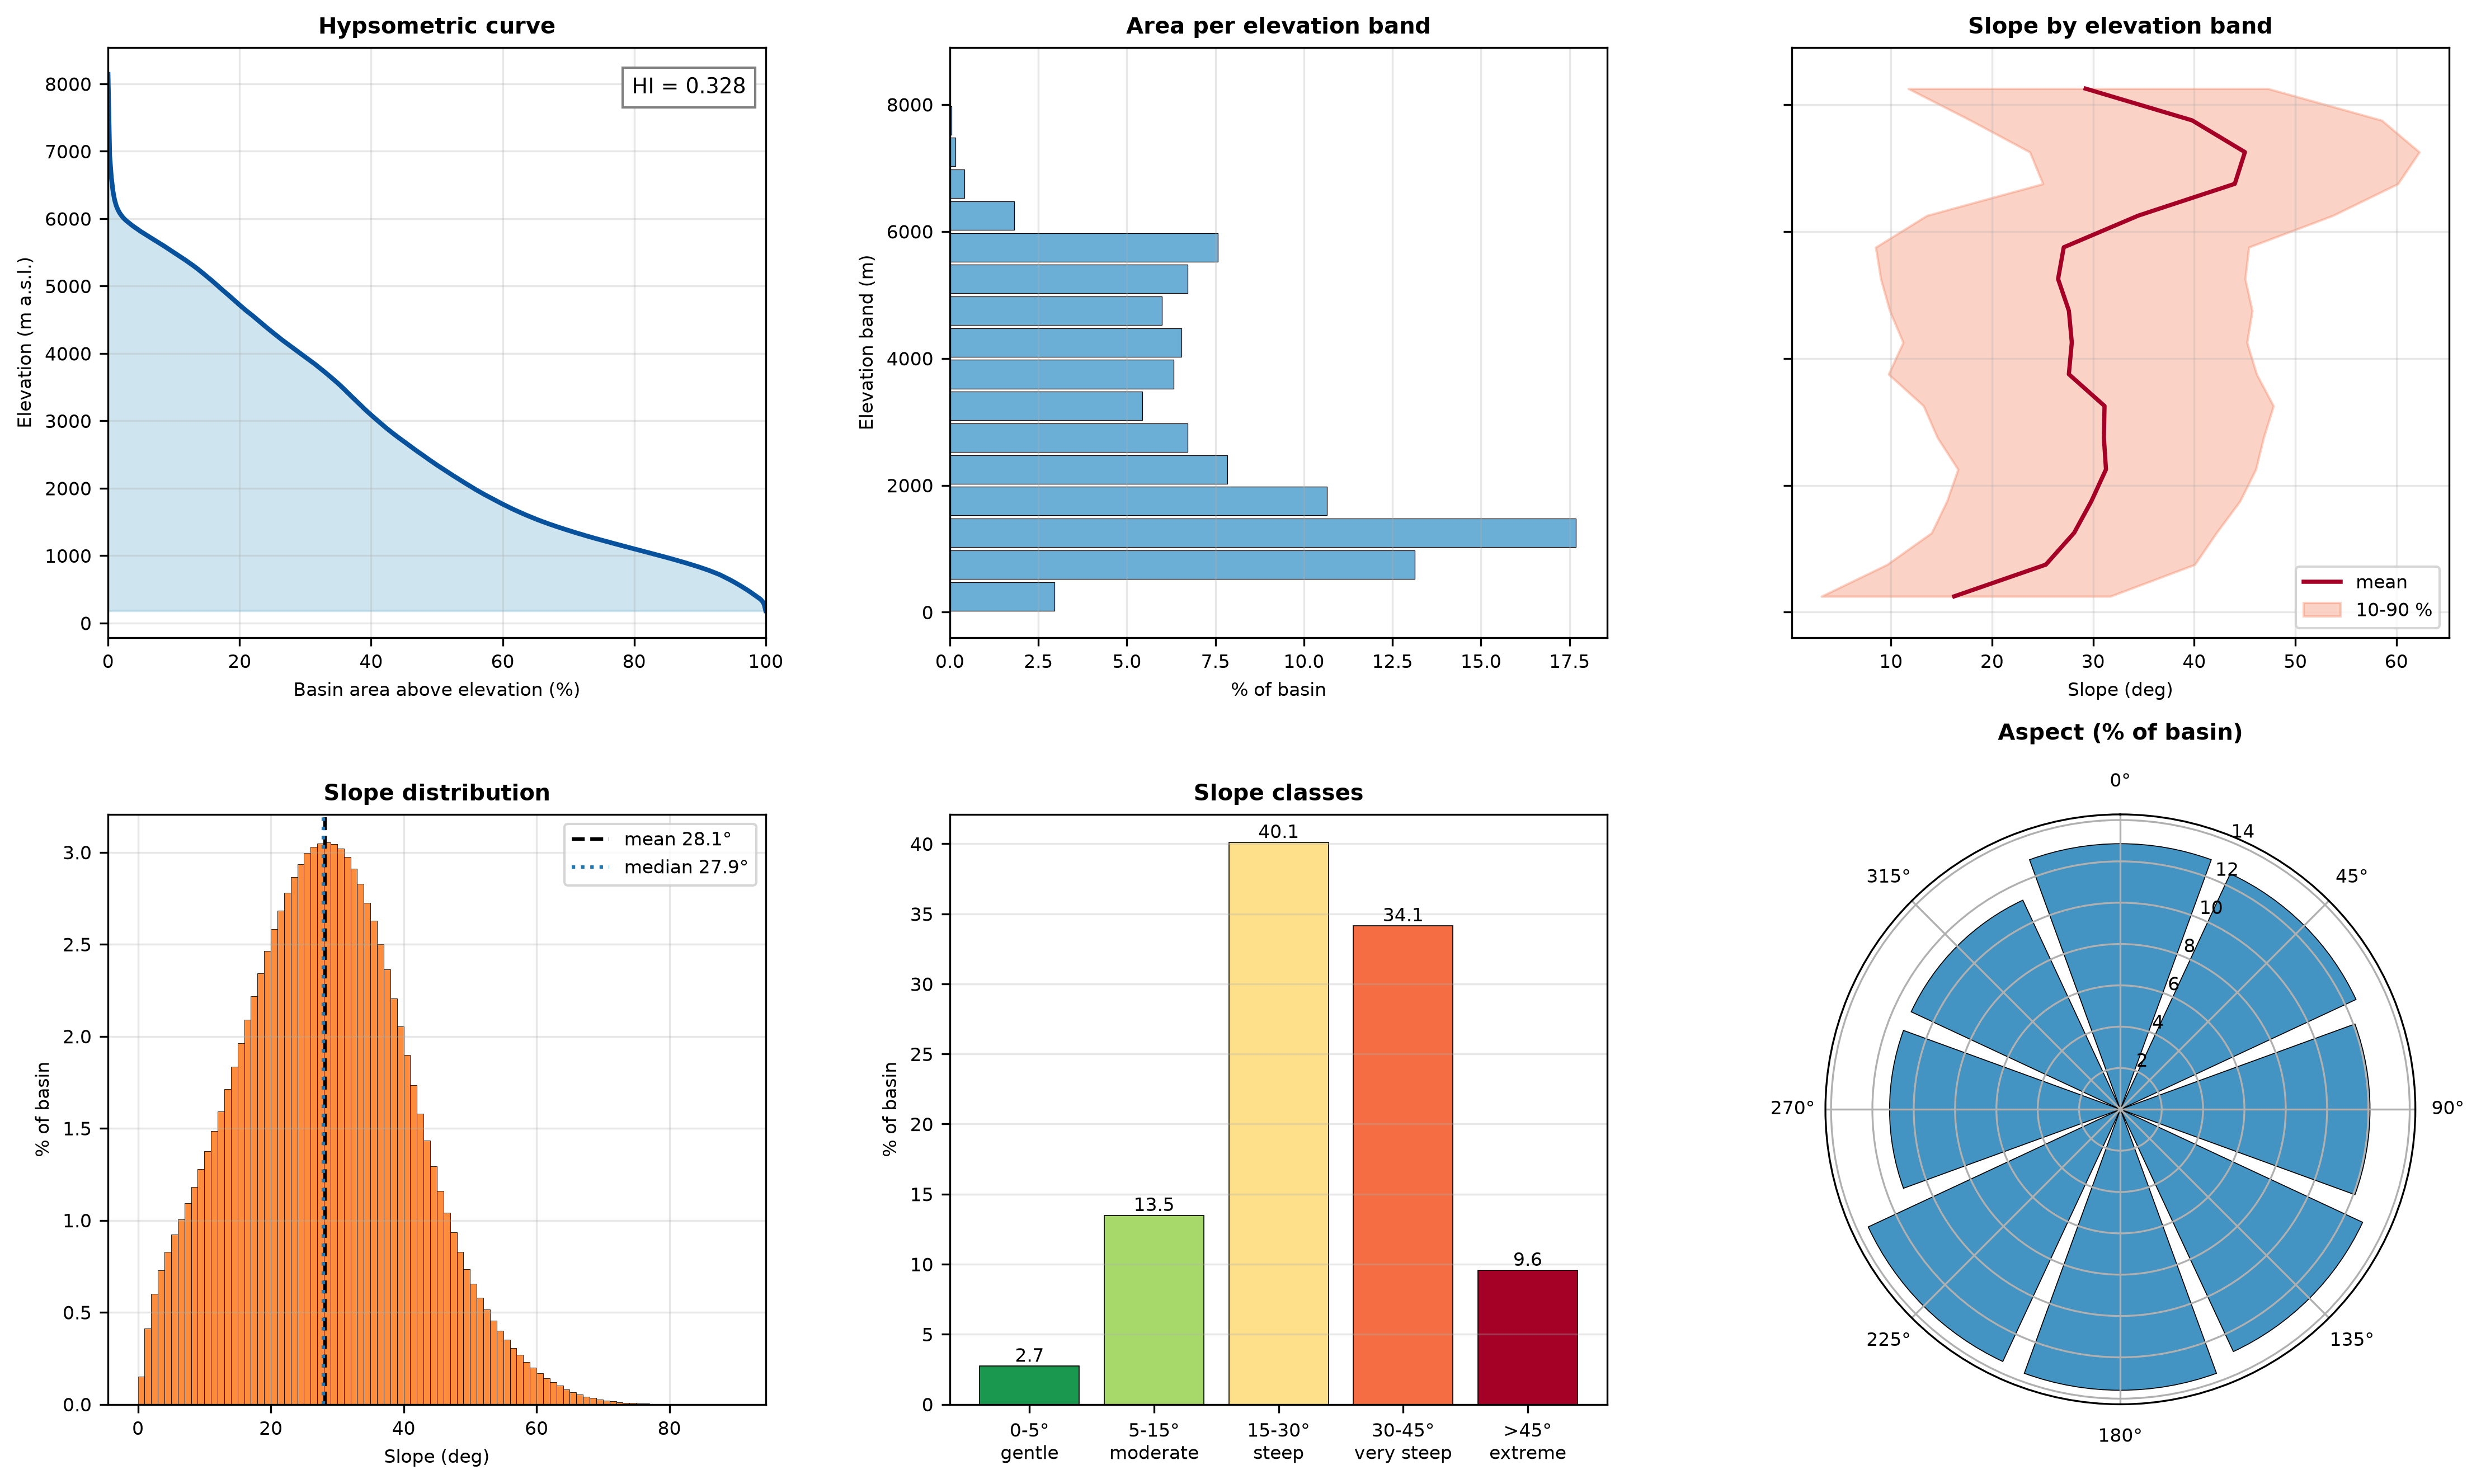

In [3]:
# ============================================================
# Cell 3: elevation, slope, aspect, hypsometry, elevation bands, terrain layers
# ============================================================
z, s = R["elev"], R["slope"]
PCTS = [1, 2, 5, 10, 25, 50, 75, 90, 95, 98, 99]
BAND = 500
SLOPE_BREAKS = [5, 15, 30, 45]
SLOPE_LABELS = ["0-5° gentle", "5-15° moderate", "15-30° steep", "30-45° very steep", ">45° extreme"]
SLOPE_COLORS = ["#1a9850", "#a6d96a", "#fee08b", "#f46d43", "#a50026"]
ASP_NAMES = ["N", "NE", "E", "SE", "S", "SW", "W", "NW", "Flat"]


def stat_rows(v, unit):
    q = np.percentile(v, PCTS)
    d = {"min": v.min(), "max": v.max(), "range": v.max() - v.min(), "mean": v.mean(), "median": np.median(v),
         "std": v.std(), "skewness": sps.skew(v), "kurtosis_excess": sps.kurtosis(v)}
    d.update({f"p{p}": x for p, x in zip(PCTS, q)})
    dimless = ("skewness", "kurtosis_excess")
    return [(k if k in dimless else f"{k}_{unit}", float(x), "" if k in dimless else unit) for k, x in d.items()]


def layer_row(name, unit, v):
    v = v[np.isfinite(v)]
    p = np.percentile(v, [2, 25, 50, 75, 98])
    return {"layer": name, "unit": unit, "min": v.min(), "p2": p[0], "p25": p[1], "median": p[2], "mean": v.mean(),
            "p75": p[3], "p98": p[4], "max": v.max(), "std": v.std()}


# ---------- elevation ----------
rows = stat_rows(z, "m")
hi_z = (z.mean() - z.min()) / (z.max() - z.min())
rows.append(("hypsometric_integral", float(hi_z), "-"))
for pa in (10, 50, 90):
    rows.append((f"elev_exceeded_by_{pa}pct_of_area_m", float(np.percentile(z, 100 - pa)), "m"))
for t in (1000, 2000, 3000, 4000, 5000, 6000, 7000):
    k = z >= t
    rows += [(f"area_above_{t}m_km2", float(k.sum() * CELL_KM2), "km2"), (f"area_above_{t}m_pct", float(100 * k.mean()), "%")]
elev_stats = pd.DataFrame(rows, columns=["metric", "value", "unit"]).round(4)
save_table(elev_stats, P.TAB / "07_elevation_statistics.csv")

# ---------- hypsometric curve ----------
area_above = np.linspace(0, 100, 401)
hyps = pd.DataFrame({"area_above_pct": area_above, "elevation_m": np.percentile(z, 100 - area_above)}).round(2)
save_table(hyps, P.TAB / "07_hypsometric_curve.csv")

# ---------- elevation bands ----------
edges = np.arange(np.floor(z.min() / BAND) * BAND, np.ceil(z.max() / BAND) * BAND + BAND, BAND)
bi = np.digitize(z, edges[1:-1])
lc_names = {10: "tree", 20: "shrub", 30: "grass", 40: "crop", 60: "bare", 70: "snow_ice", 100: "moss_lichen"}
rows = []
for k in range(len(edges) - 1):
    m = bi == k
    if not m.any():
        continue
    sk = s[m]
    rec = {"band": f"{edges[k]:,.0f}-{edges[k + 1]:,.0f} m", "from_m": edges[k], "to_m": edges[k + 1],
           "cells": int(m.sum()), "area_km2": m.sum() * CELL_KM2, "percent": 100 * m.mean(),
           "mean_slope_deg": sk.mean(), "p10_slope_deg": np.percentile(sk, 10), "p90_slope_deg": np.percentile(sk, 90),
           "mean_twi": R["twi"][m].mean()}
    if R["lc"] is not None:
        for c, nm in lc_names.items():
            rec[f"pct_{nm}"] = 100 * (R["lc"][m] == c).mean()
    if R["cn"] is not None and np.isfinite(R["cn"][m]).any():
        rec["mean_cn"] = float(np.nanmean(R["cn"][m]))
    rows.append(rec)
bands = pd.DataFrame(rows)
bands["cum_percent_above"] = bands.percent[::-1].cumsum()[::-1]
bands = bands.round(3)
save_table(bands, P.TAB / "07_elevation_bands.csv")
display(bands[["band", "area_km2", "percent", "cum_percent_above", "mean_slope_deg"]
              + [c for c in ("pct_snow_ice", "pct_tree", "mean_cn") if c in bands.columns]])

# ---------- slope ----------
rows = stat_rows(s, "deg")
for t in (15, 30, 45):
    k = s >= t
    rows += [(f"area_slope_gt_{t}deg_km2", float(k.sum() * CELL_KM2), "km2"),
             (f"area_slope_gt_{t}deg_pct", float(100 * k.mean()), "%")]
slope_stats = pd.DataFrame(rows, columns=["metric", "value", "unit"]).round(4)
save_table(slope_stats, P.TAB / "07_slope_statistics.csv")

sc = np.digitize(s, SLOPE_BREAKS)
rows = []
for k, lb in enumerate(SLOPE_LABELS):
    m = sc == k
    rows.append({"class": lb, "cells": int(m.sum()), "area_km2": m.sum() * CELL_KM2, "percent": 100 * m.mean(),
                 "mean_elev_m": z[m].mean() if m.any() else np.nan, "mean_twi": R["twi"][m].mean() if m.any() else np.nan})
slope_cls = pd.DataFrame(rows).round(3)
save_table(slope_cls, P.TAB / "07_slope_classes.csv")

# ---------- aspect ----------
asp = R["aspect"]
flat = ~np.isfinite(asp) | (asp < 0) | (s < 1.0)
sector = (np.floor(((np.nan_to_num(asp) + 22.5) % 360) / 45).astype(int)) % 8
sector[flat] = 8
rows = []
for k, nm in enumerate(ASP_NAMES):
    m = sector == k
    rows.append({"direction": nm, "cells": int(m.sum()), "area_km2": m.sum() * CELL_KM2, "percent": 100 * m.mean(),
                 "mean_slope_deg": s[m].mean() if m.any() else np.nan, "mean_elev_m": z[m].mean() if m.any() else np.nan})
asp_tab = pd.DataFrame(rows).round(3)
save_table(asp_tab, P.TAB / "07_slope_by_aspect.csv")

# ---------- terrain derivative layers ----------
TERR = [("tri.tif", "TRI (3x3)", "m"), ("relative_relief.tif", "relative relief (1 km)", "m"),
        ("curvature_profile.tif", "profile curvature", "1/m"), ("curvature_plan.tif", "plan curvature", "1/m"),
        ("curvature_total.tif", "total curvature", "1/m"), ("tpi_small.tif", "TPI (0.3 km)", "m"),
        ("tpi_large.tif", "TPI (1 km)", "m")]
rows = [layer_row("elevation", "m", z), layer_row("slope", "deg", s)]
for fn, nm, un in TERR:
    v = basin_cells(fn, False)
    if v is not None:
        rows.append(layer_row(nm, un, v))
terrain = pd.DataFrame(rows).round(6)
save_table(terrain, P.TAB / "07_terrain_layer_statistics.csv")
display(terrain)
display(slope_cls); display(asp_tab)

# ---------- figure ----------
fig = plt.figure(figsize=(18, 10.5))
gs = fig.add_gridspec(2, 3, hspace=0.3, wspace=0.28)
mid = (bands.from_m + bands.to_m) / 2

ax = fig.add_subplot(gs[0, 0])
ax.plot(hyps.area_above_pct, hyps.elevation_m, color="#08519c", lw=2)
ax.fill_between(hyps.area_above_pct, hyps.elevation_m, z.min(), color="#9ecae1", alpha=0.5)
ax.set_xlim(0, 100); ax.set_xlabel("Basin area above elevation (%)"); ax.set_ylabel("Elevation (m a.s.l.)")
ax.set_title("Hypsometric curve", fontweight="bold"); ax.grid(alpha=0.3)
ax.text(0.97, 0.95, f"HI = {hi_z:.3f}", transform=ax.transAxes, ha="right", va="top", fontsize=9,
        bbox=dict(fc="white", ec="0.5"))

ax2 = fig.add_subplot(gs[0, 1])
ax2.barh(mid, bands.percent, height=BAND * 0.9, color="#6baed6", edgecolor="k", linewidth=0.3)
ax2.set_xlabel("% of basin"); ax2.set_ylabel("Elevation band (m)")
ax2.set_title("Area per elevation band", fontweight="bold"); ax2.grid(alpha=0.3, axis="x")

ax3 = fig.add_subplot(gs[0, 2], sharey=ax2)
ax3.plot(bands.mean_slope_deg, mid, color="#a50026", lw=1.8, label="mean")
ax3.fill_betweenx(mid, bands.p10_slope_deg, bands.p90_slope_deg, color="#f46d43", alpha=0.3, label="10-90 %")
ax3.set_xlabel("Slope (deg)"); ax3.set_title("Slope by elevation band", fontweight="bold")
ax3.legend(fontsize=8); ax3.grid(alpha=0.3)
plt.setp(ax3.get_yticklabels(), visible=False)

ax4 = fig.add_subplot(gs[1, 0])
cnt, ed = np.histogram(s, bins=np.arange(0, 90.5, 1))
ax4.bar(ed[:-1], 100 * cnt / cnt.sum(), width=1, align="edge", color="#fd8d3c", edgecolor="k", linewidth=0.2)
ax4.axvline(s.mean(), color="k", ls="--", label=f"mean {s.mean():.1f}°")
ax4.axvline(np.median(s), color="tab:blue", ls=":", label=f"median {np.median(s):.1f}°")
ax4.set_xlabel("Slope (deg)"); ax4.set_ylabel("% of basin")
ax4.set_title("Slope distribution", fontweight="bold"); ax4.legend(fontsize=8); ax4.grid(alpha=0.3)

ax5 = fig.add_subplot(gs[1, 1])
ax5.bar(range(5), slope_cls.percent, color=SLOPE_COLORS, edgecolor="k", linewidth=0.4)
ax5.set_xticks(range(5)); ax5.set_xticklabels([l.replace(" ", "\n", 1) for l in SLOPE_LABELS], fontsize=8)
for i, v_ in enumerate(slope_cls.percent):
    ax5.text(i, v_, f"{v_:.1f}", ha="center", va="bottom", fontsize=8)
ax5.set_ylabel("% of basin"); ax5.set_title("Slope classes", fontweight="bold"); ax5.grid(alpha=0.3, axis="y")

ax6 = fig.add_subplot(gs[1, 2], projection="polar")
ax6.set_theta_zero_location("N"); ax6.set_theta_direction(-1)
ax6.bar(np.deg2rad(np.arange(8) * 45), asp_tab.percent.values[:8], width=np.deg2rad(40),
        color="#4393c3", edgecolor="k", linewidth=0.4)
ax6.set_title("Aspect (% of basin)", fontweight="bold", pad=14)
fig.savefig(P.FIG / "07_elevation_slope_panel.png", dpi=250, bbox_inches="tight", facecolor="white")
plt.show(); plt.close(fig)

,order,streams_N,total_length_km,mean_length_km,bifurcation_ratio,length_ratio,n_links,mean_link_length_km,mean_gradient_m_per_m,median_link_gradient,mean_sinuosity,median_ksn,mean_area_dn_km2,median_area_dn_km2,pct_of_network_length,cum_pct_of_length_from_order1
0,1,635,1896.541,2.987,4.349,2.041,635,2.9867,0.1263,0.1167,1.2557,227.7245,951.6910,39.6689,48.3827,48.3827
1,2,146,889.790,6.094,4.562,2.799,273,3.2593,0.0686,0.0554,1.2483,190.2269,889.3703,74.7624,22.6994,71.0821
2,3,32,545.901,17.059,4.571,2.136,158,3.4551,0.0486,0.0426,1.2579,205.2242,680.7977,205.2054,13.9265,85.0086
3,4,7,255.017,36.431,7.000,9.130,88,2.8979,0.0234,0.0128,1.2262,157.3901,1489.1929,988.8176,6.5057,91.5143
4,5,1,332.627,332.627,NaN,NaN,115,2.8924,0.0081,0.0039,1.3441,103.7866,7234.0848,6843.9060,8.4857,100.0000


Horton: Rb = 4.93 (R2 1.00) | Rl = 3.07 (R2 0.94) | Ra = 1.58 | weighted Rb = 4.42
Rb of about 3-5 is typical; Rl above 1 means mean stream length grows with order.
Drainage density ~ threshold^-0.44 | segments ~ threshold^-0.96 (from 3 thresholds, so indicative only)


,threshold_km2,threshold_cells,segments,total_length_km,drainage_density_km_per_km2,density_exponent,segments_exponent
0,5,5741,1269,3919.9,0.330,-0.4386,-0.9627
1,10,11481,637,2903.0,0.245,-0.4386,-0.9627
2,25,28703,269,1932.5,0.163,-0.4386,-0.9627


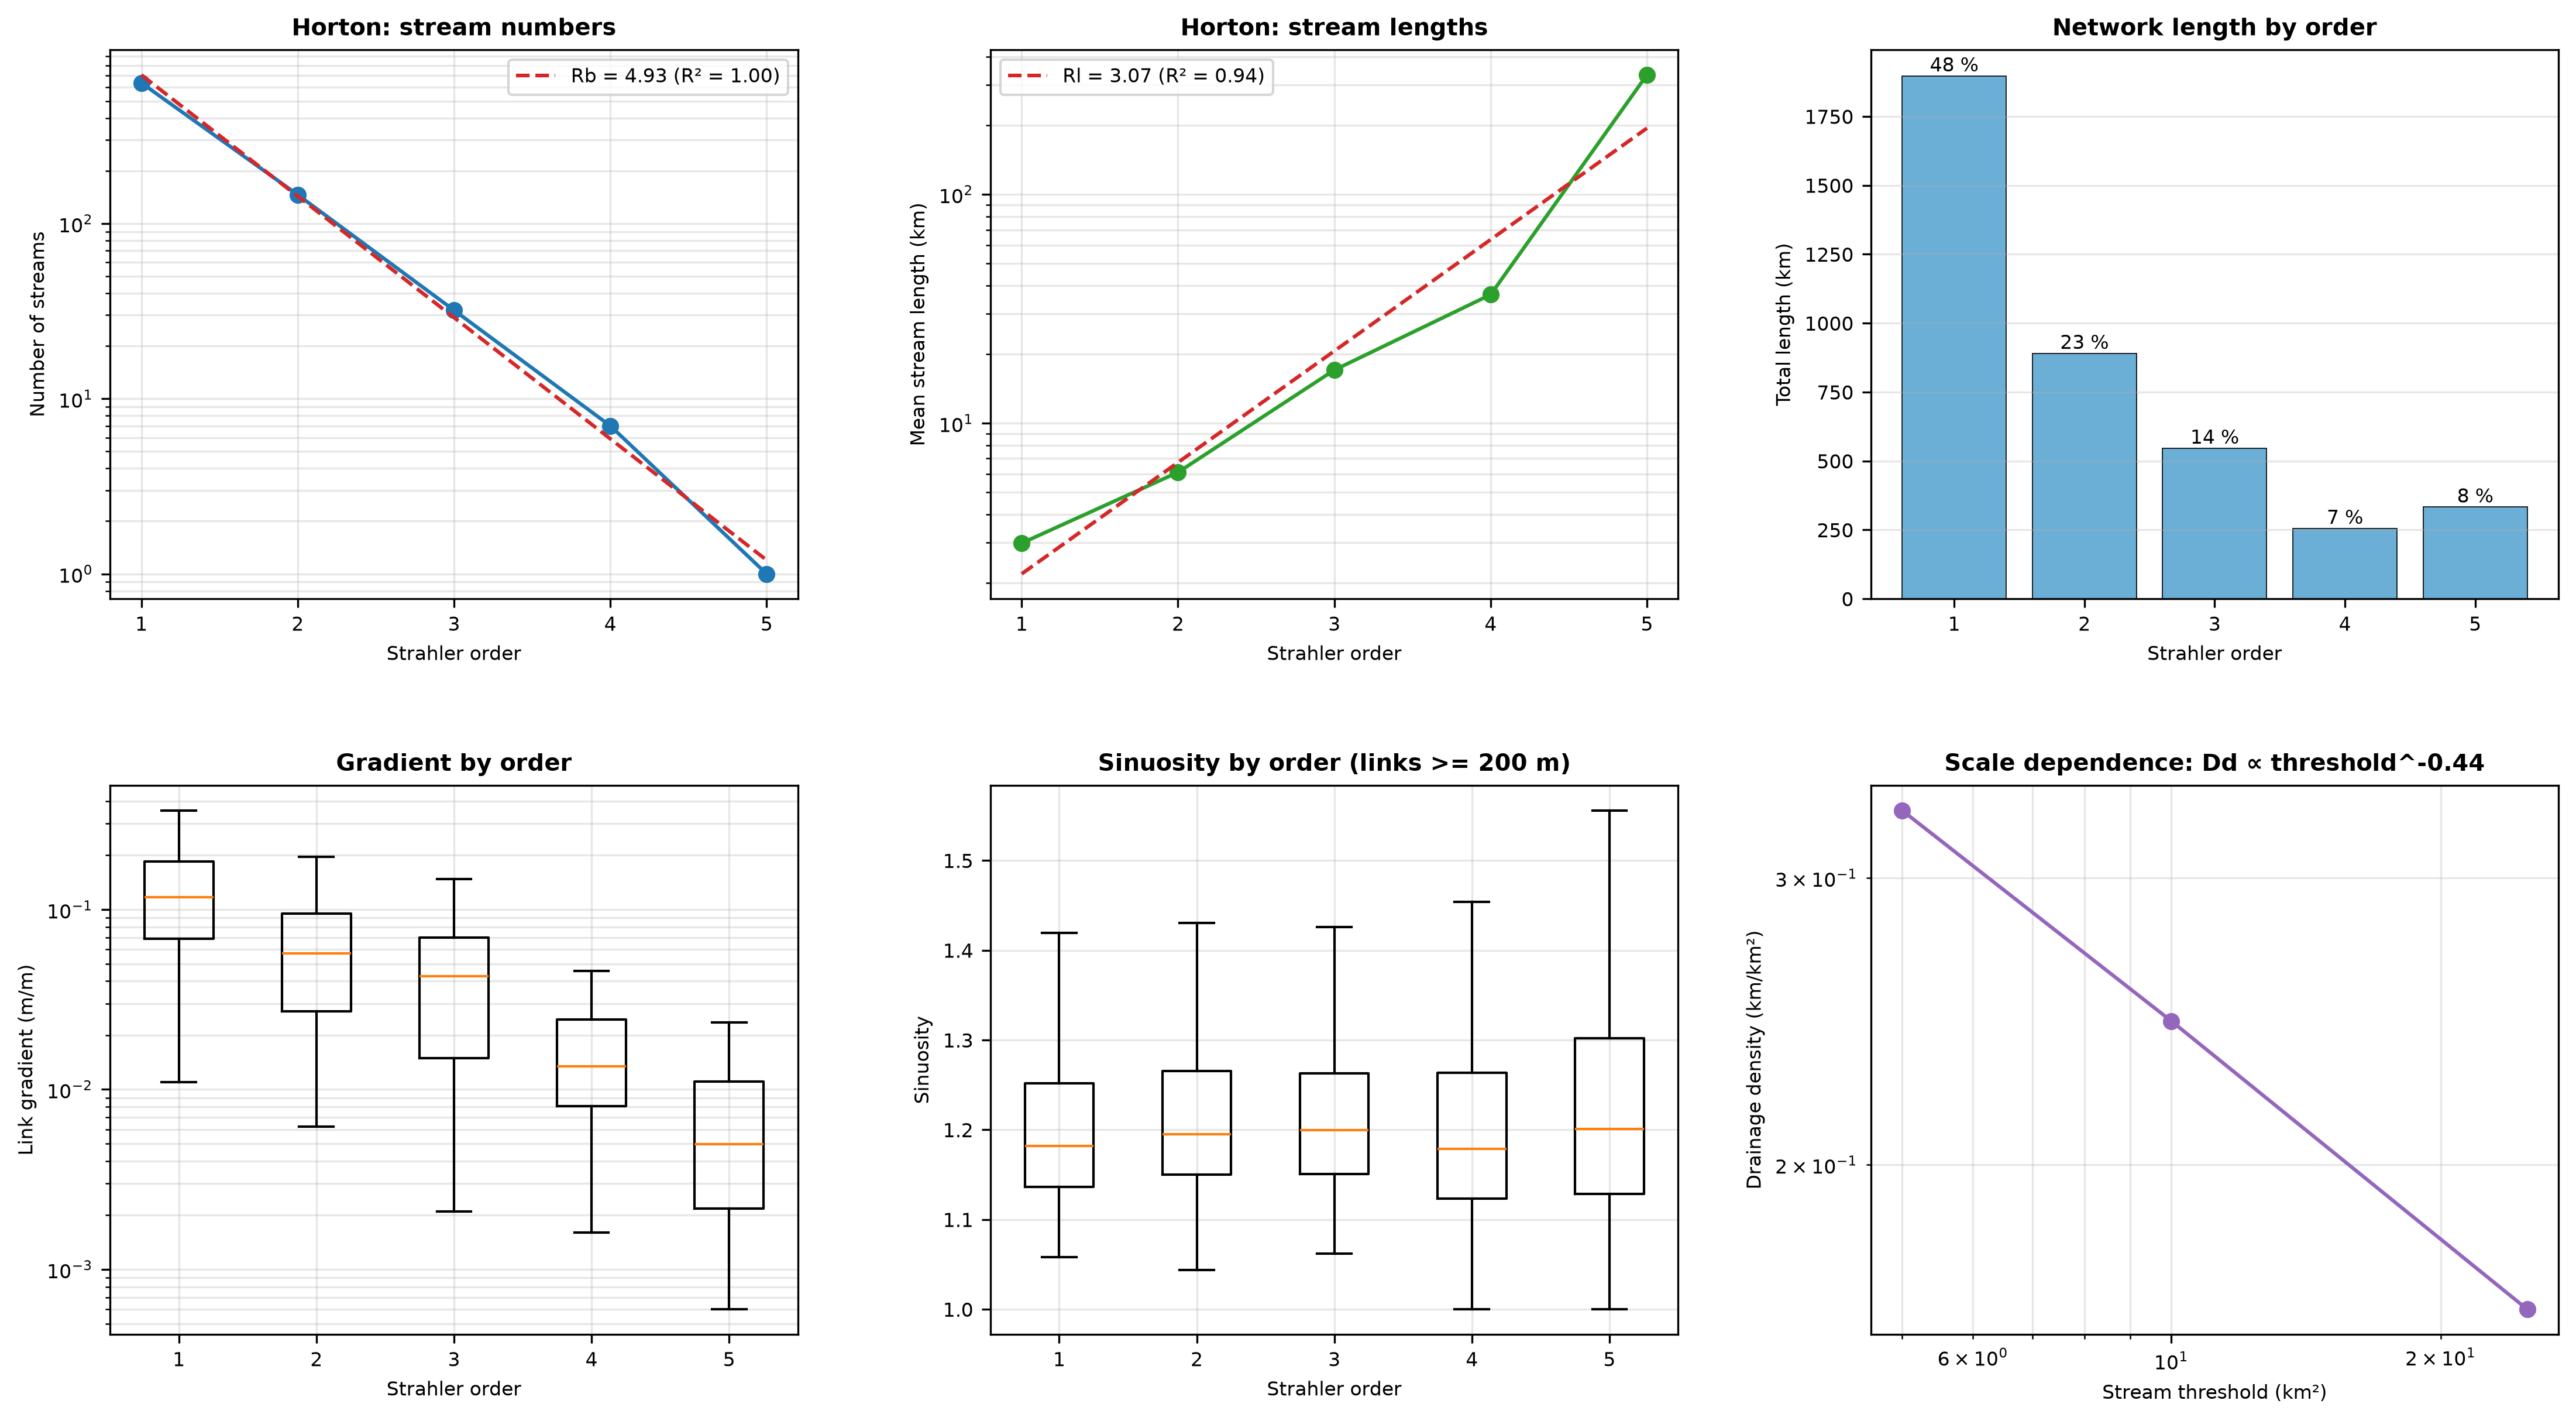

In [4]:
# ============================================================
# Cell 4: stream network - Strahler table, Horton's laws, gradient and sinuosity by order, scale dependence
# ============================================================
lk = links.dropna(subset=["order"]).copy()
lk["order"] = lk["order"].astype(int)
rows = []
for o, g in lk.groupby("order"):
    L = g.length_km.sum()
    ok = g.sinuosity.notna()
    rows.append({"order": int(o), "n_links": len(g), "mean_link_length_km": g.length_km.mean(),
                 "mean_gradient_m_per_m": g.drop_m.sum() / (L * 1000), "median_link_gradient": g.gradient_m_per_m.median(),
                 "mean_sinuosity": np.average(g.sinuosity[ok], weights=g.length_km[ok]) if ok.any() else np.nan,
                 "median_ksn": g.ksn.median(), "mean_area_dn_km2": g.area_dn_km2.mean(),
                 "median_area_dn_km2": g.area_dn_km2.median()})
ts = strahler.merge(pd.DataFrame(rows), on="order", how="left")
ts["pct_of_network_length"] = 100 * ts.total_length_km / ts.total_length_km.sum()
ts["cum_pct_of_length_from_order1"] = ts.pct_of_network_length.cumsum()
ts = ts.round(4)
save_table(ts, P.TAB / "07_stream_statistics.csv")
display(ts)

rb_reg, rl_reg, r2n, r2l = horton_fit(ts)
u = ts["order"].values.astype(float)
if len(u) >= 3:
    b3, a3 = np.polyfit(u, np.log(ts.mean_area_dn_km2.values.astype(float)), 1)
    ra_reg = float(np.exp(b3))
else:
    ra_reg = np.nan
print(f"Horton: Rb = {rb_reg:.2f} (R2 {r2n:.2f}) | Rl = {rl_reg:.2f} (R2 {r2l:.2f}) | Ra = {ra_reg:.2f} "
      f"| weighted Rb = {weighted_rb(ts):.2f}")
print("Rb of about 3-5 is typical; Rl above 1 means mean stream length grows with order.")

# ---------- scale dependence of drainage density (needs notebook 04 Cell 1's threshold test) ----------
thr_path = P.TAB / "04_stream_threshold_test.csv"
if thr_path.exists():
    thr = pd.read_csv(thr_path)
    kd = float(np.polyfit(np.log(thr.threshold_km2), np.log(thr.drainage_density_km_per_km2), 1)[0])
    ks_ = float(np.polyfit(np.log(thr.threshold_km2), np.log(thr.segments), 1)[0])
    thr["density_exponent"] = kd; thr["segments_exponent"] = ks_
    save_table(thr.round(4), P.TAB / "07_stream_threshold_scale.csv")
    print(f"Drainage density ~ threshold^{kd:.2f} | segments ~ threshold^{ks_:.2f} "
          f"(from {len(thr)} thresholds, so indicative only)")
    display(thr.round(4))
else:
    thr = None

# ---------- figure ----------
orders = sorted(lk["order"].unique())
fig, axs = plt.subplots(2, 3, figsize=(18, 9.5), gridspec_kw={"hspace": 0.34, "wspace": 0.28})

ax = axs[0, 0]
ax.semilogy(u, ts.streams_N, "o-", color="tab:blue")
if np.isfinite(rb_reg):
    b_, a_ = np.polyfit(u, np.log(ts.streams_N.astype(float)), 1)
    ax.semilogy(u, np.exp(a_ + b_ * u), "--", color="tab:red", label=f"Rb = {rb_reg:.2f} (R² = {r2n:.2f})")
    ax.legend(fontsize=8)
ax.set_xticks(u); ax.set_xlabel("Strahler order"); ax.set_ylabel("Number of streams")
ax.set_title("Horton: stream numbers", fontweight="bold"); ax.grid(alpha=0.3, which="both")

ax = axs[0, 1]
ax.semilogy(u, ts.mean_length_km, "o-", color="tab:green")
if np.isfinite(rl_reg):
    b_, a_ = np.polyfit(u, np.log(ts.mean_length_km.astype(float)), 1)
    ax.semilogy(u, np.exp(a_ + b_ * u), "--", color="tab:red", label=f"Rl = {rl_reg:.2f} (R² = {r2l:.2f})")
    ax.legend(fontsize=8)
ax.set_xticks(u); ax.set_xlabel("Strahler order"); ax.set_ylabel("Mean stream length (km)")
ax.set_title("Horton: stream lengths", fontweight="bold"); ax.grid(alpha=0.3, which="both")

ax = axs[0, 2]
ax.bar(u, ts.total_length_km, color="#6baed6", edgecolor="k", linewidth=0.4)
for x_, v_, p_ in zip(u, ts.total_length_km, ts.pct_of_network_length):
    ax.text(x_, v_, f"{p_:.0f} %", ha="center", va="bottom", fontsize=8)
ax.set_xticks(u); ax.set_xlabel("Strahler order"); ax.set_ylabel("Total length (km)")
ax.set_title("Network length by order", fontweight="bold"); ax.grid(alpha=0.3, axis="y")

ax = axs[1, 0]
gdata = [lk.loc[(lk["order"] == o) & (lk.gradient_m_per_m > 1e-4), "gradient_m_per_m"].values for o in orders]
ax.boxplot(gdata, showfliers=False); ax.set_xticklabels(orders); ax.set_yscale("log")
ax.set_xlabel("Strahler order"); ax.set_ylabel("Link gradient (m/m)")
ax.set_title("Gradient by order", fontweight="bold"); ax.grid(alpha=0.3, which="both")

ax = axs[1, 1]
sdata = [lk.loc[(lk["order"] == o) & lk.sinuosity.notna(), "sinuosity"].values for o in orders]
ax.boxplot(sdata, showfliers=False); ax.set_xticklabels(orders)
ax.set_xlabel("Strahler order"); ax.set_ylabel("Sinuosity")
ax.set_title("Sinuosity by order (links >= 200 m)", fontweight="bold"); ax.grid(alpha=0.3)

ax = axs[1, 2]
if thr is not None:
    ax.loglog(thr.threshold_km2, thr.drainage_density_km_per_km2, "o-", color="tab:purple")
    ax.set_xlabel("Stream threshold (km²)"); ax.set_ylabel("Drainage density (km/km²)")
    ax.set_title(f"Scale dependence: Dd ∝ threshold^{kd:.2f}", fontweight="bold"); ax.grid(alpha=0.3, which="both")
else:
    ax.axis("off")
fig.savefig(P.FIG / "07_stream_statistics_panel.png", dpi=250, bbox_inches="tight", facecolor="white")
plt.show(); plt.close(fig)

Screening score built from ['CN_II', 'slope_mean_deg', 'drainage_density_km_per_km2', 'form_factor', 'tc_kirpich_h'] (weights [0.3, 0.25, 0.2, 0.15, -0.1]). It ranks units by runoff-producing tendencies; it is NOT a hazard or discharge model.


,metric,count,mean,std,min,25%,50%,75%,max,cv_pct
area_km2,area_km2,36.0,329.808,181.573,32.171,236.595,322.562,414.038,853.967,55.054
elev_mean_m,elev_mean_m,36.0,2732.629,1621.529,659.693,1177.195,2325.236,4275.496,5314.837,59.340
relief_m,relief_m,36.0,3136.722,1800.950,1189.000,1853.750,2760.000,3509.750,7295.000,57.415
slope_mean_deg,slope_mean_deg,36.0,27.739,4.626,17.208,24.809,27.732,30.758,37.442,16.678
drainage_density_km_per_km2,drainage_density_km_per_km2,36.0,0.332,0.036,0.259,0.307,0.336,0.353,0.432,10.734
form_factor,form_factor,36.0,0.189,0.073,0.074,0.147,0.178,0.212,0.400,38.575
flowpath_length_km,flowpath_length_km,36.0,43.202,18.634,9.693,32.266,40.012,51.338,81.160,43.131
flowpath_gradient_m_per_m,flowpath_gradient_m_per_m,36.0,0.070,0.033,0.008,0.044,0.066,0.098,0.160,47.849
CN_II,CN_II,36.0,73.222,6.022,63.403,68.508,72.241,77.552,85.916,8.224
snow_ice_pct,snow_ice_pct,36.0,6.598,11.419,0.000,0.000,0.000,11.102,49.940,173.061



Highest screening scores:


,sub_id,area_km2,CN_II,slope_mean_deg,drainage_density_km_per_km2,form_factor,tc_kirpich_h,snow_ice_pct,runoff_screening_score,score_rank,cn_caution
9,10,367.96,81.78,26.12,0.37,0.30,2.57,4.32,76.67,1,False
32,33,242.15,78.98,24.33,0.35,0.29,2.42,0.13,65.56,2,False
11,12,33.10,85.92,17.21,0.36,0.19,1.44,0.00,65.42,3,False
28,29,303.40,73.43,37.44,0.29,0.21,2.20,31.52,65.28,4,True
30,31,254.14,80.77,26.50,0.34,0.20,2.60,14.58,65.00,5,False
4,5,54.77,70.53,29.21,0.37,0.20,1.41,0.00,64.72,6,False


Lowest screening scores:


,sub_id,area_km2,CN_II,slope_mean_deg,drainage_density_km_per_km2,form_factor,tc_kirpich_h,snow_ice_pct,runoff_screening_score,score_rank,cn_caution
33,34,230.05,63.98,33.13,0.31,0.15,3.20,0.00,39.86,31,False
20,21,408.52,66.51,25.94,0.39,0.15,4.94,0.00,39.31,32,False
25,26,349.11,68.36,31.68,0.28,0.15,3.15,8.84,38.06,33,False
13,14,436.79,68.42,30.89,0.30,0.14,4.55,0.00,36.81,34,False
16,17,675.97,68.99,30.66,0.29,0.15,4.05,19.10,36.81,34,False
18,19,480.63,71.74,24.92,0.34,0.09,7.46,0.00,35.00,36,False


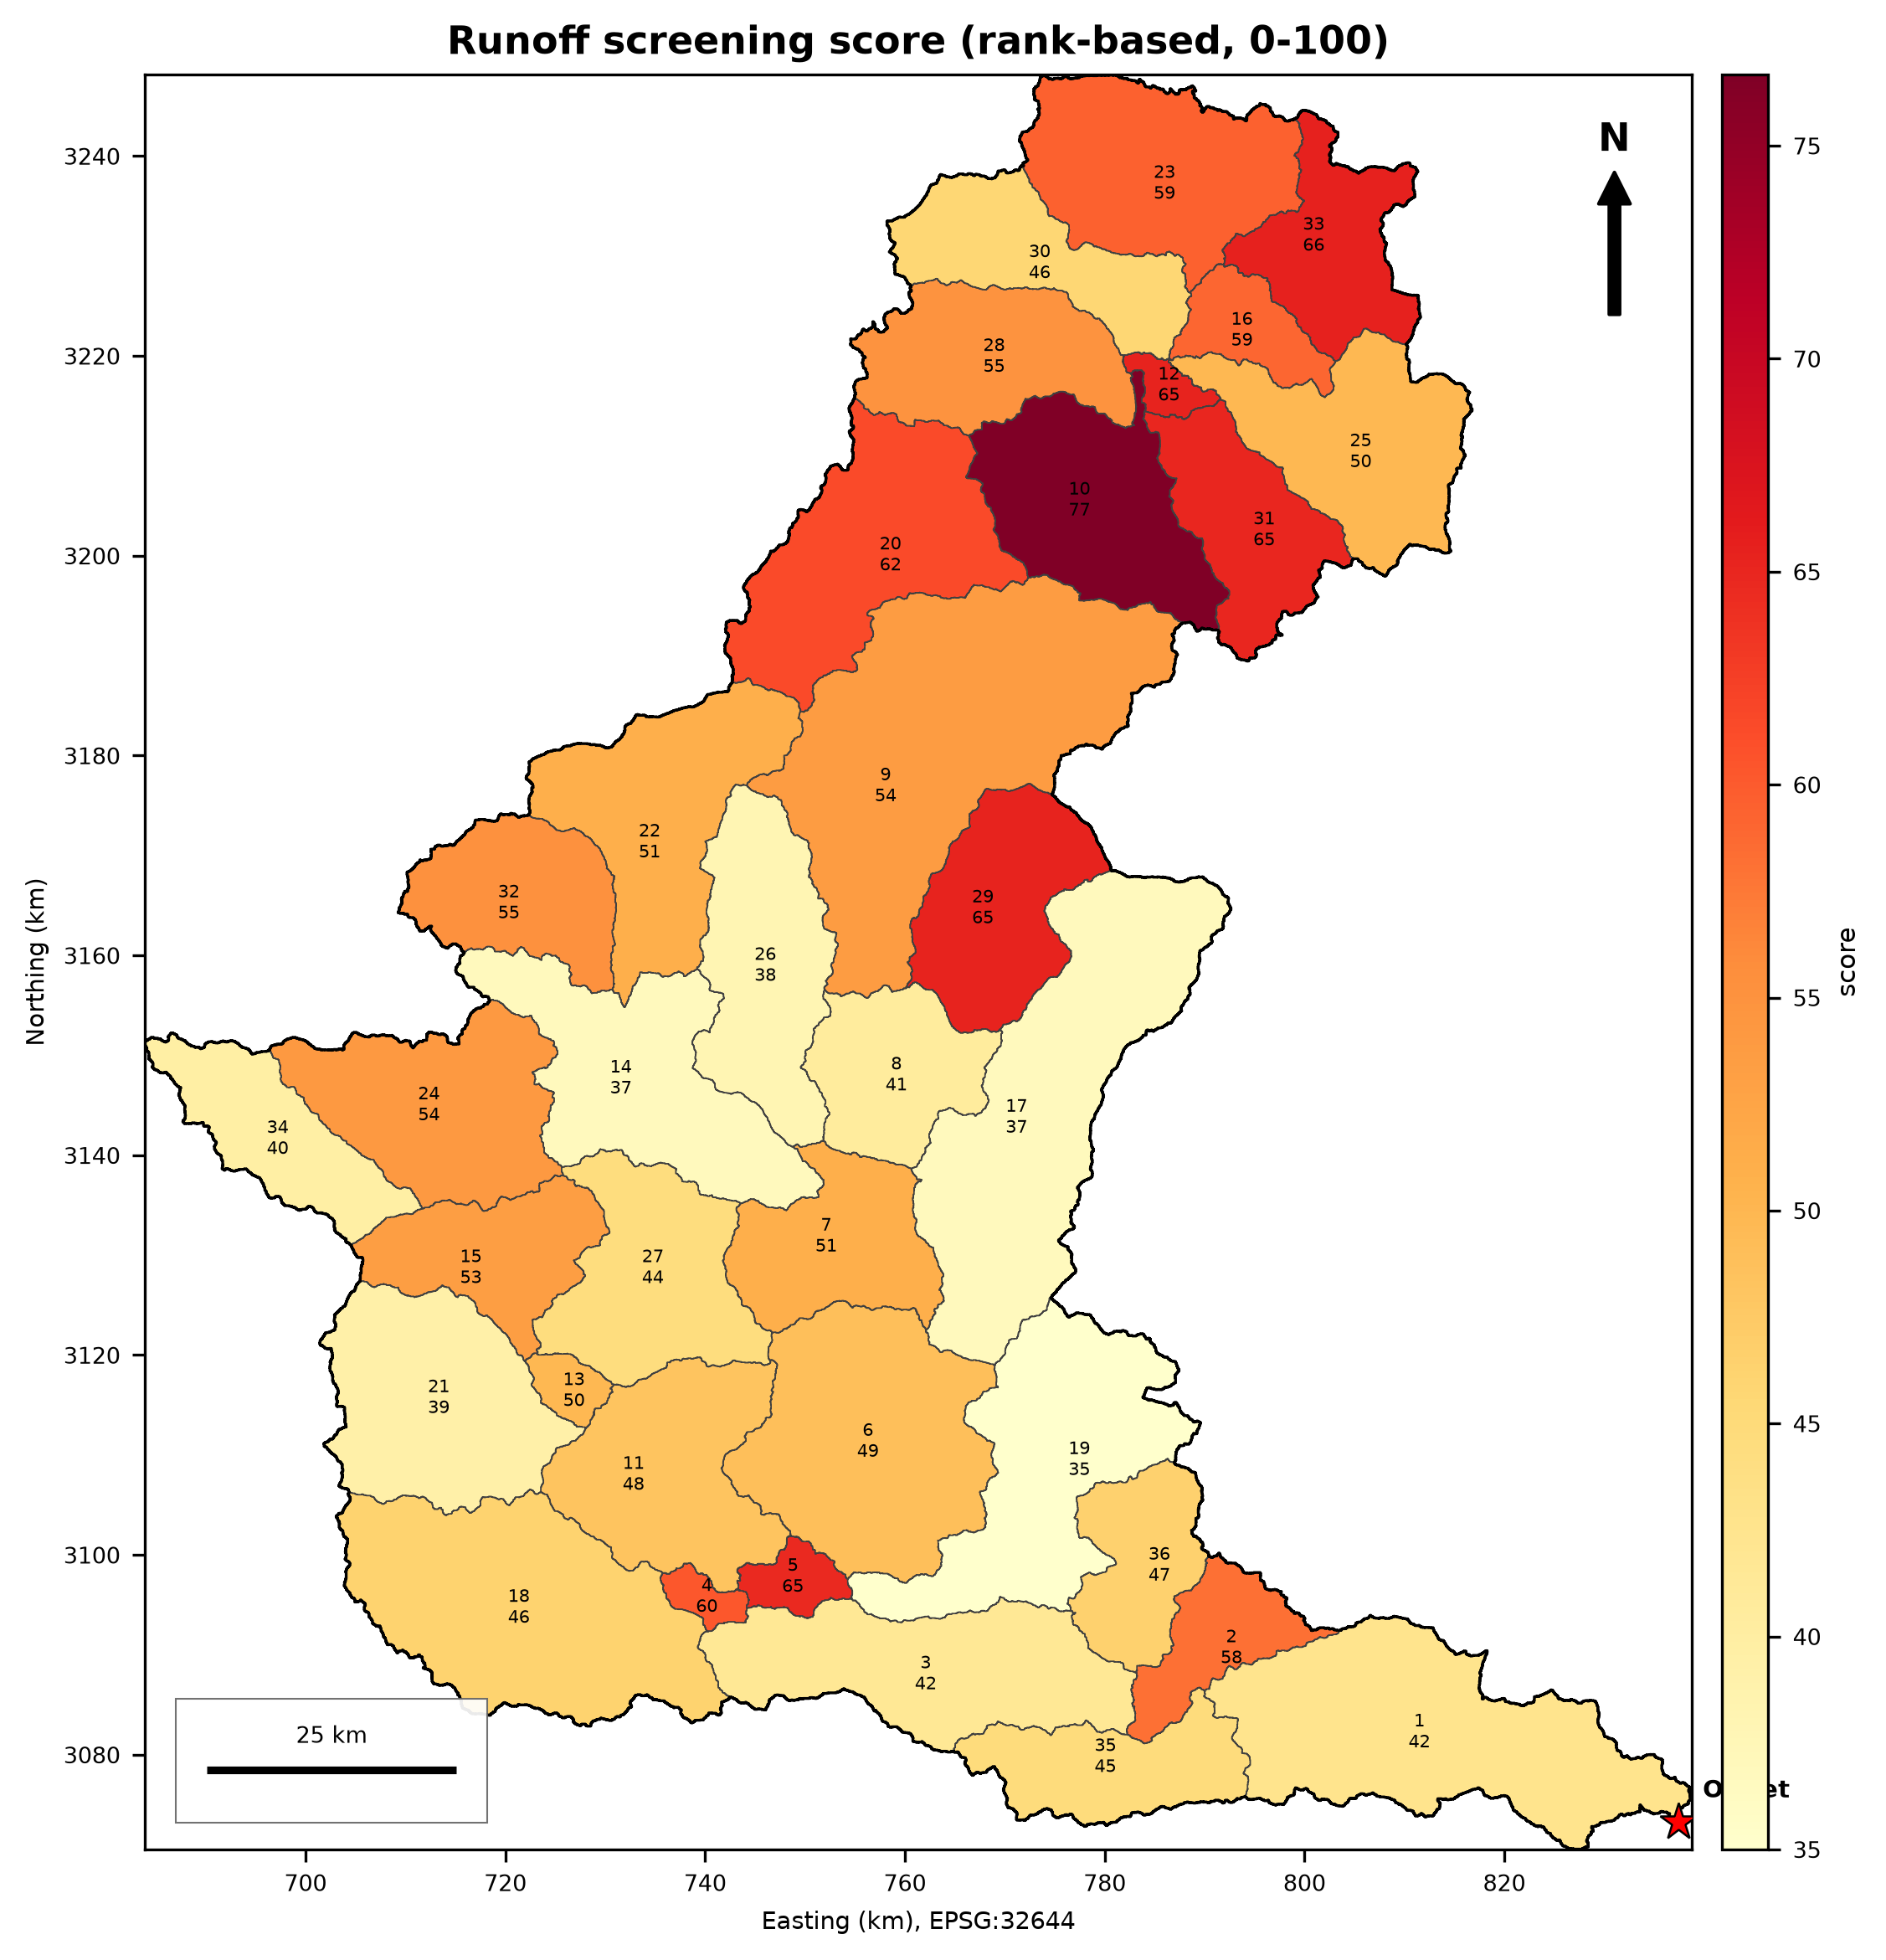

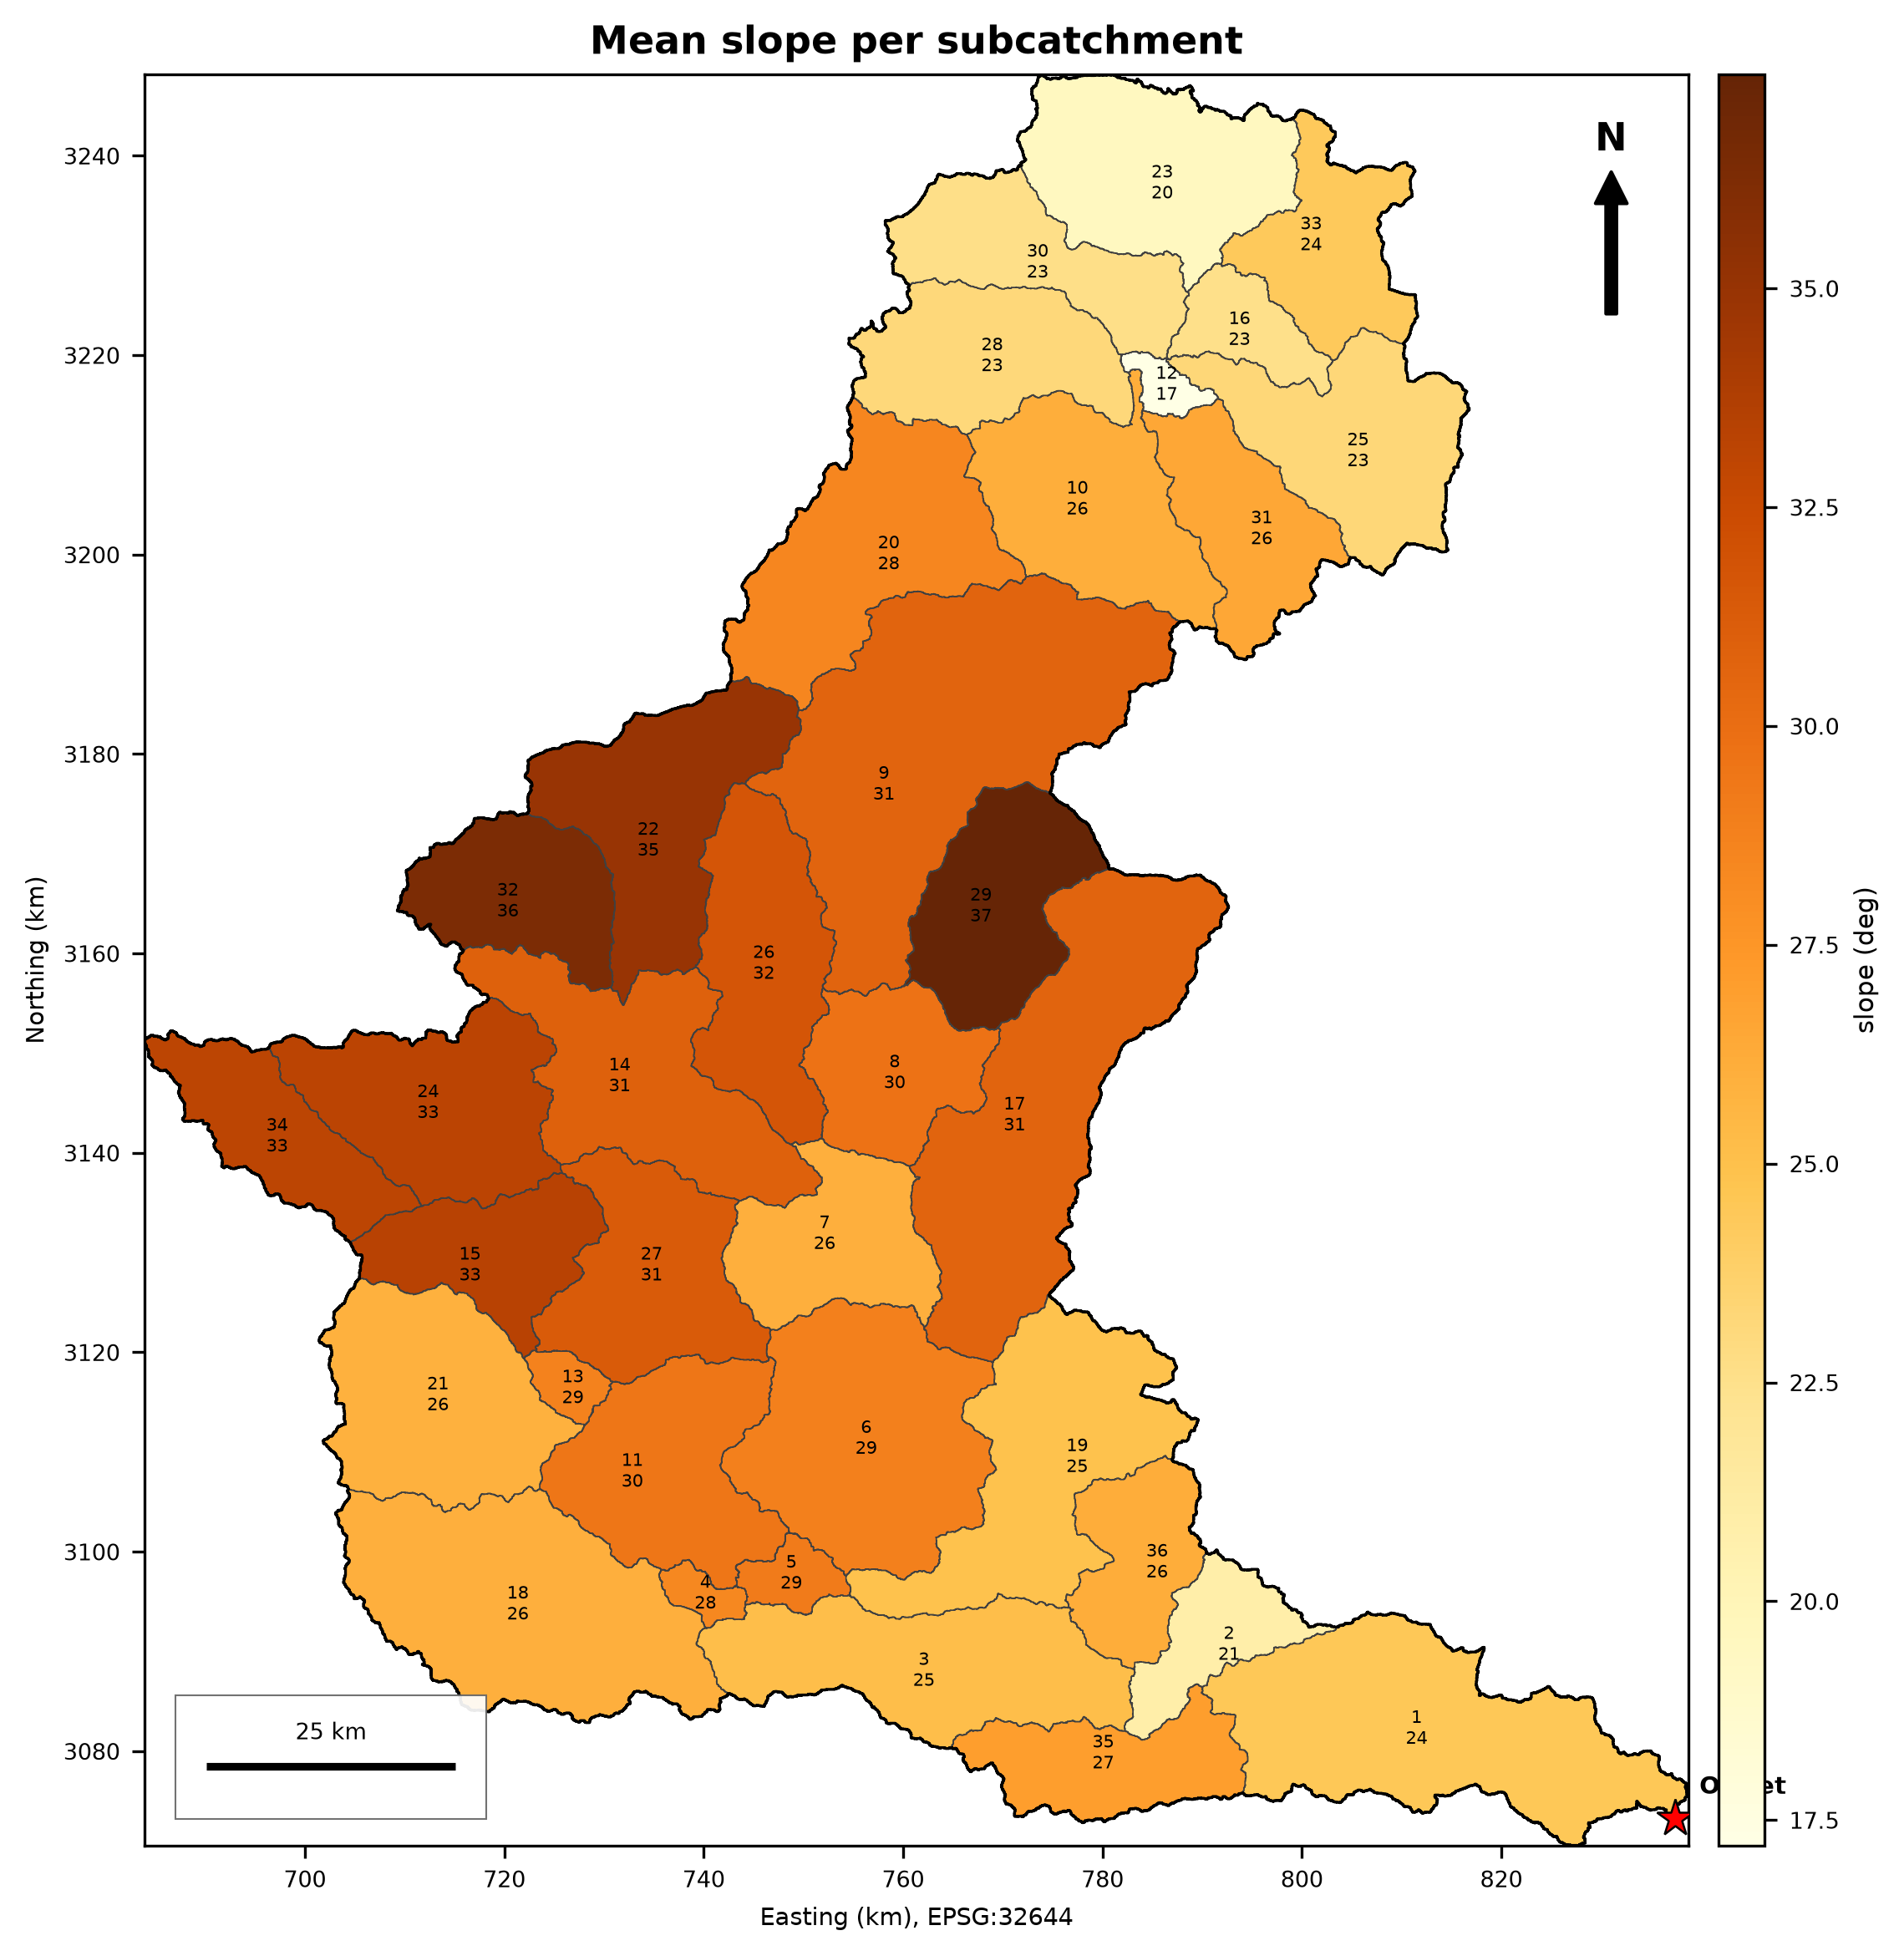

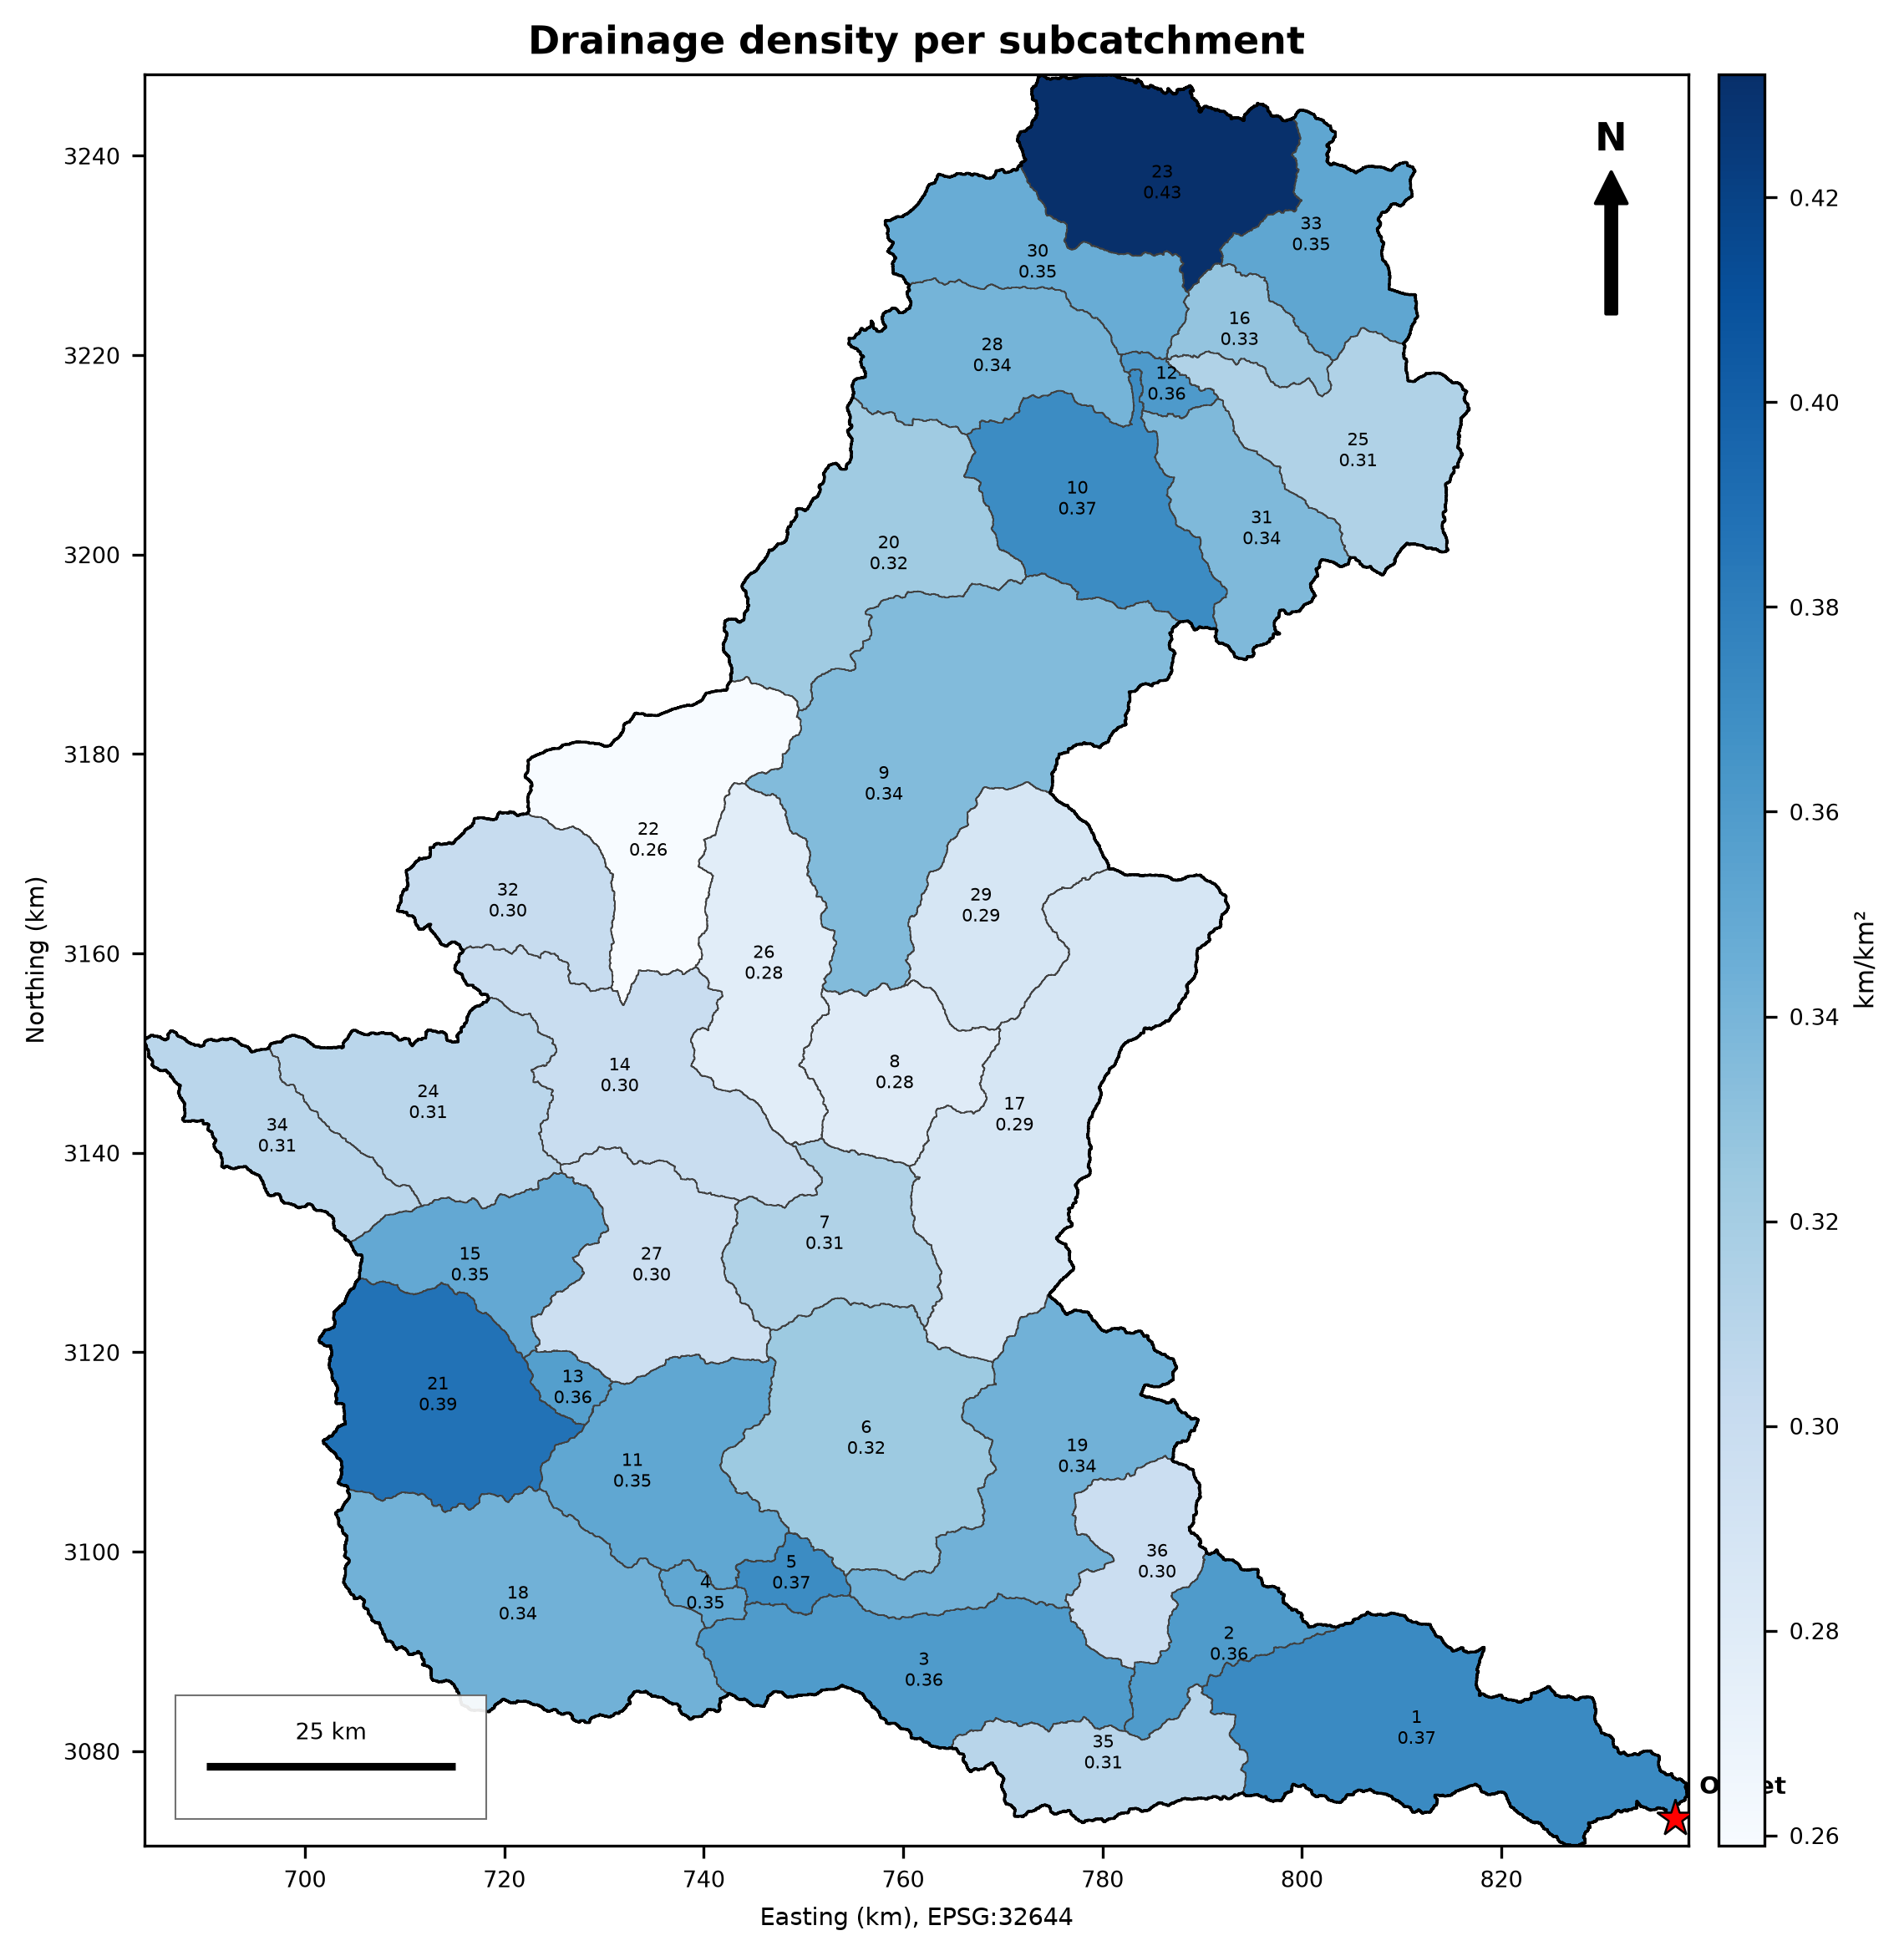

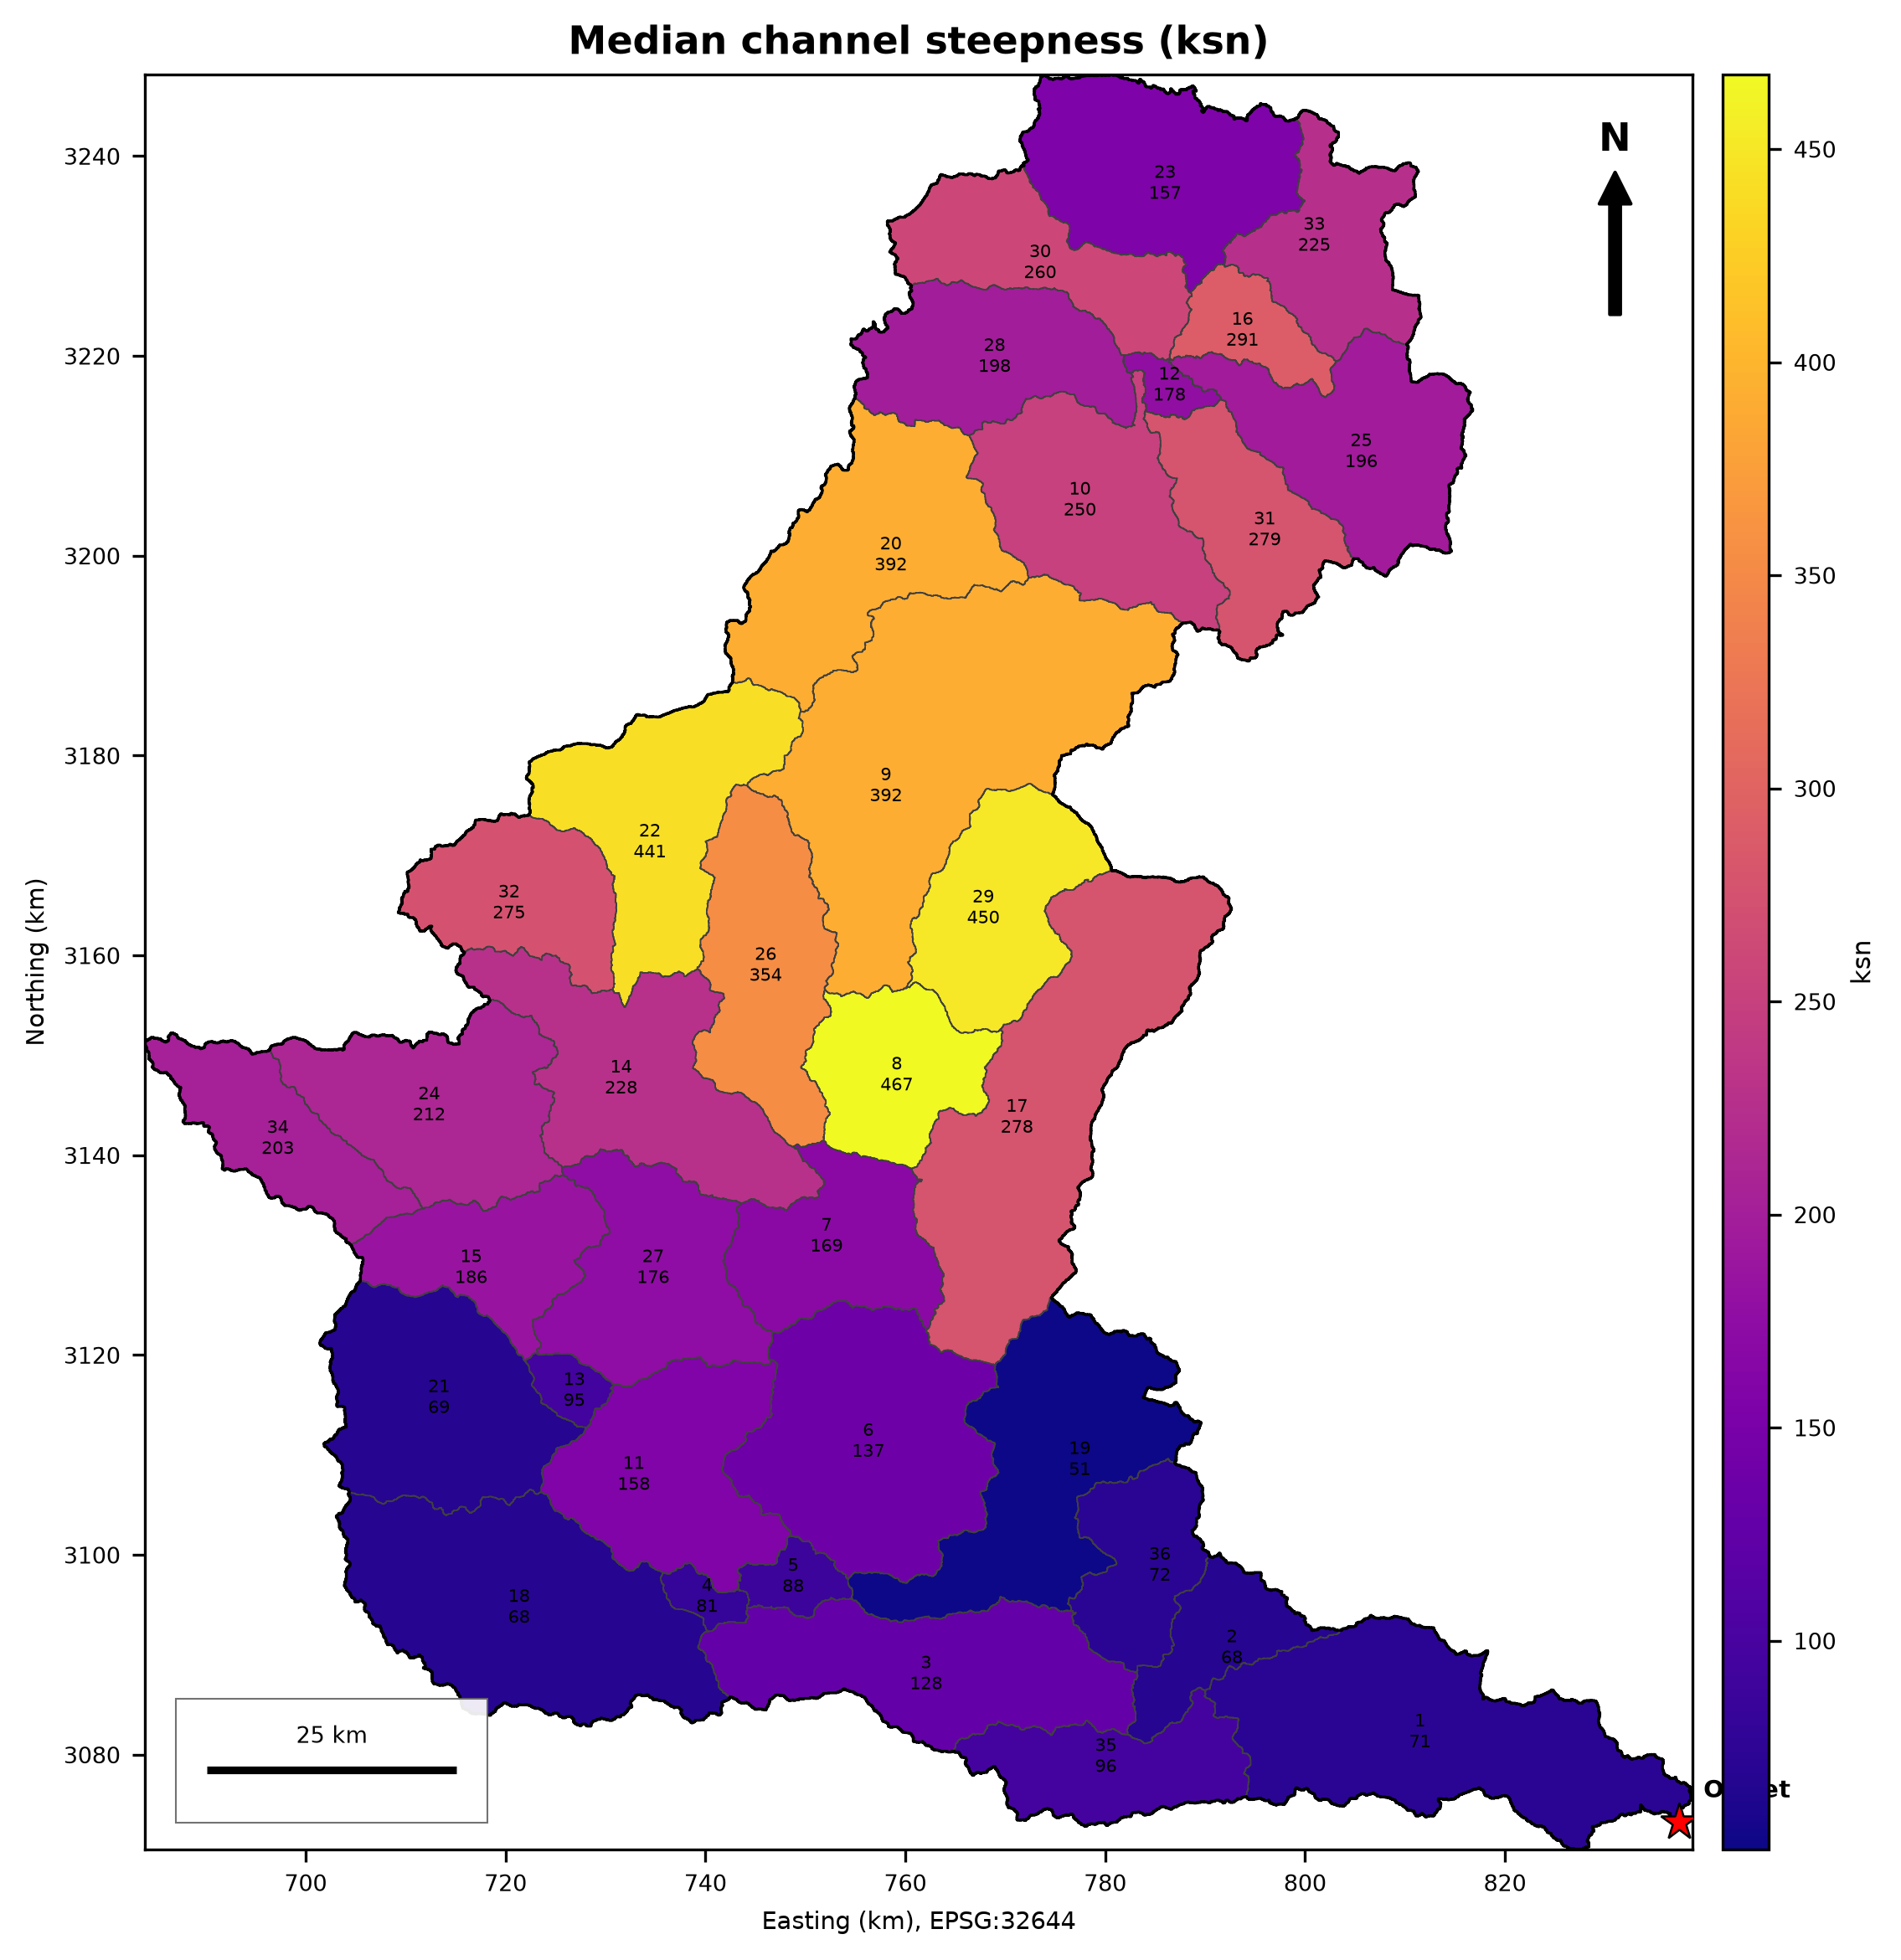

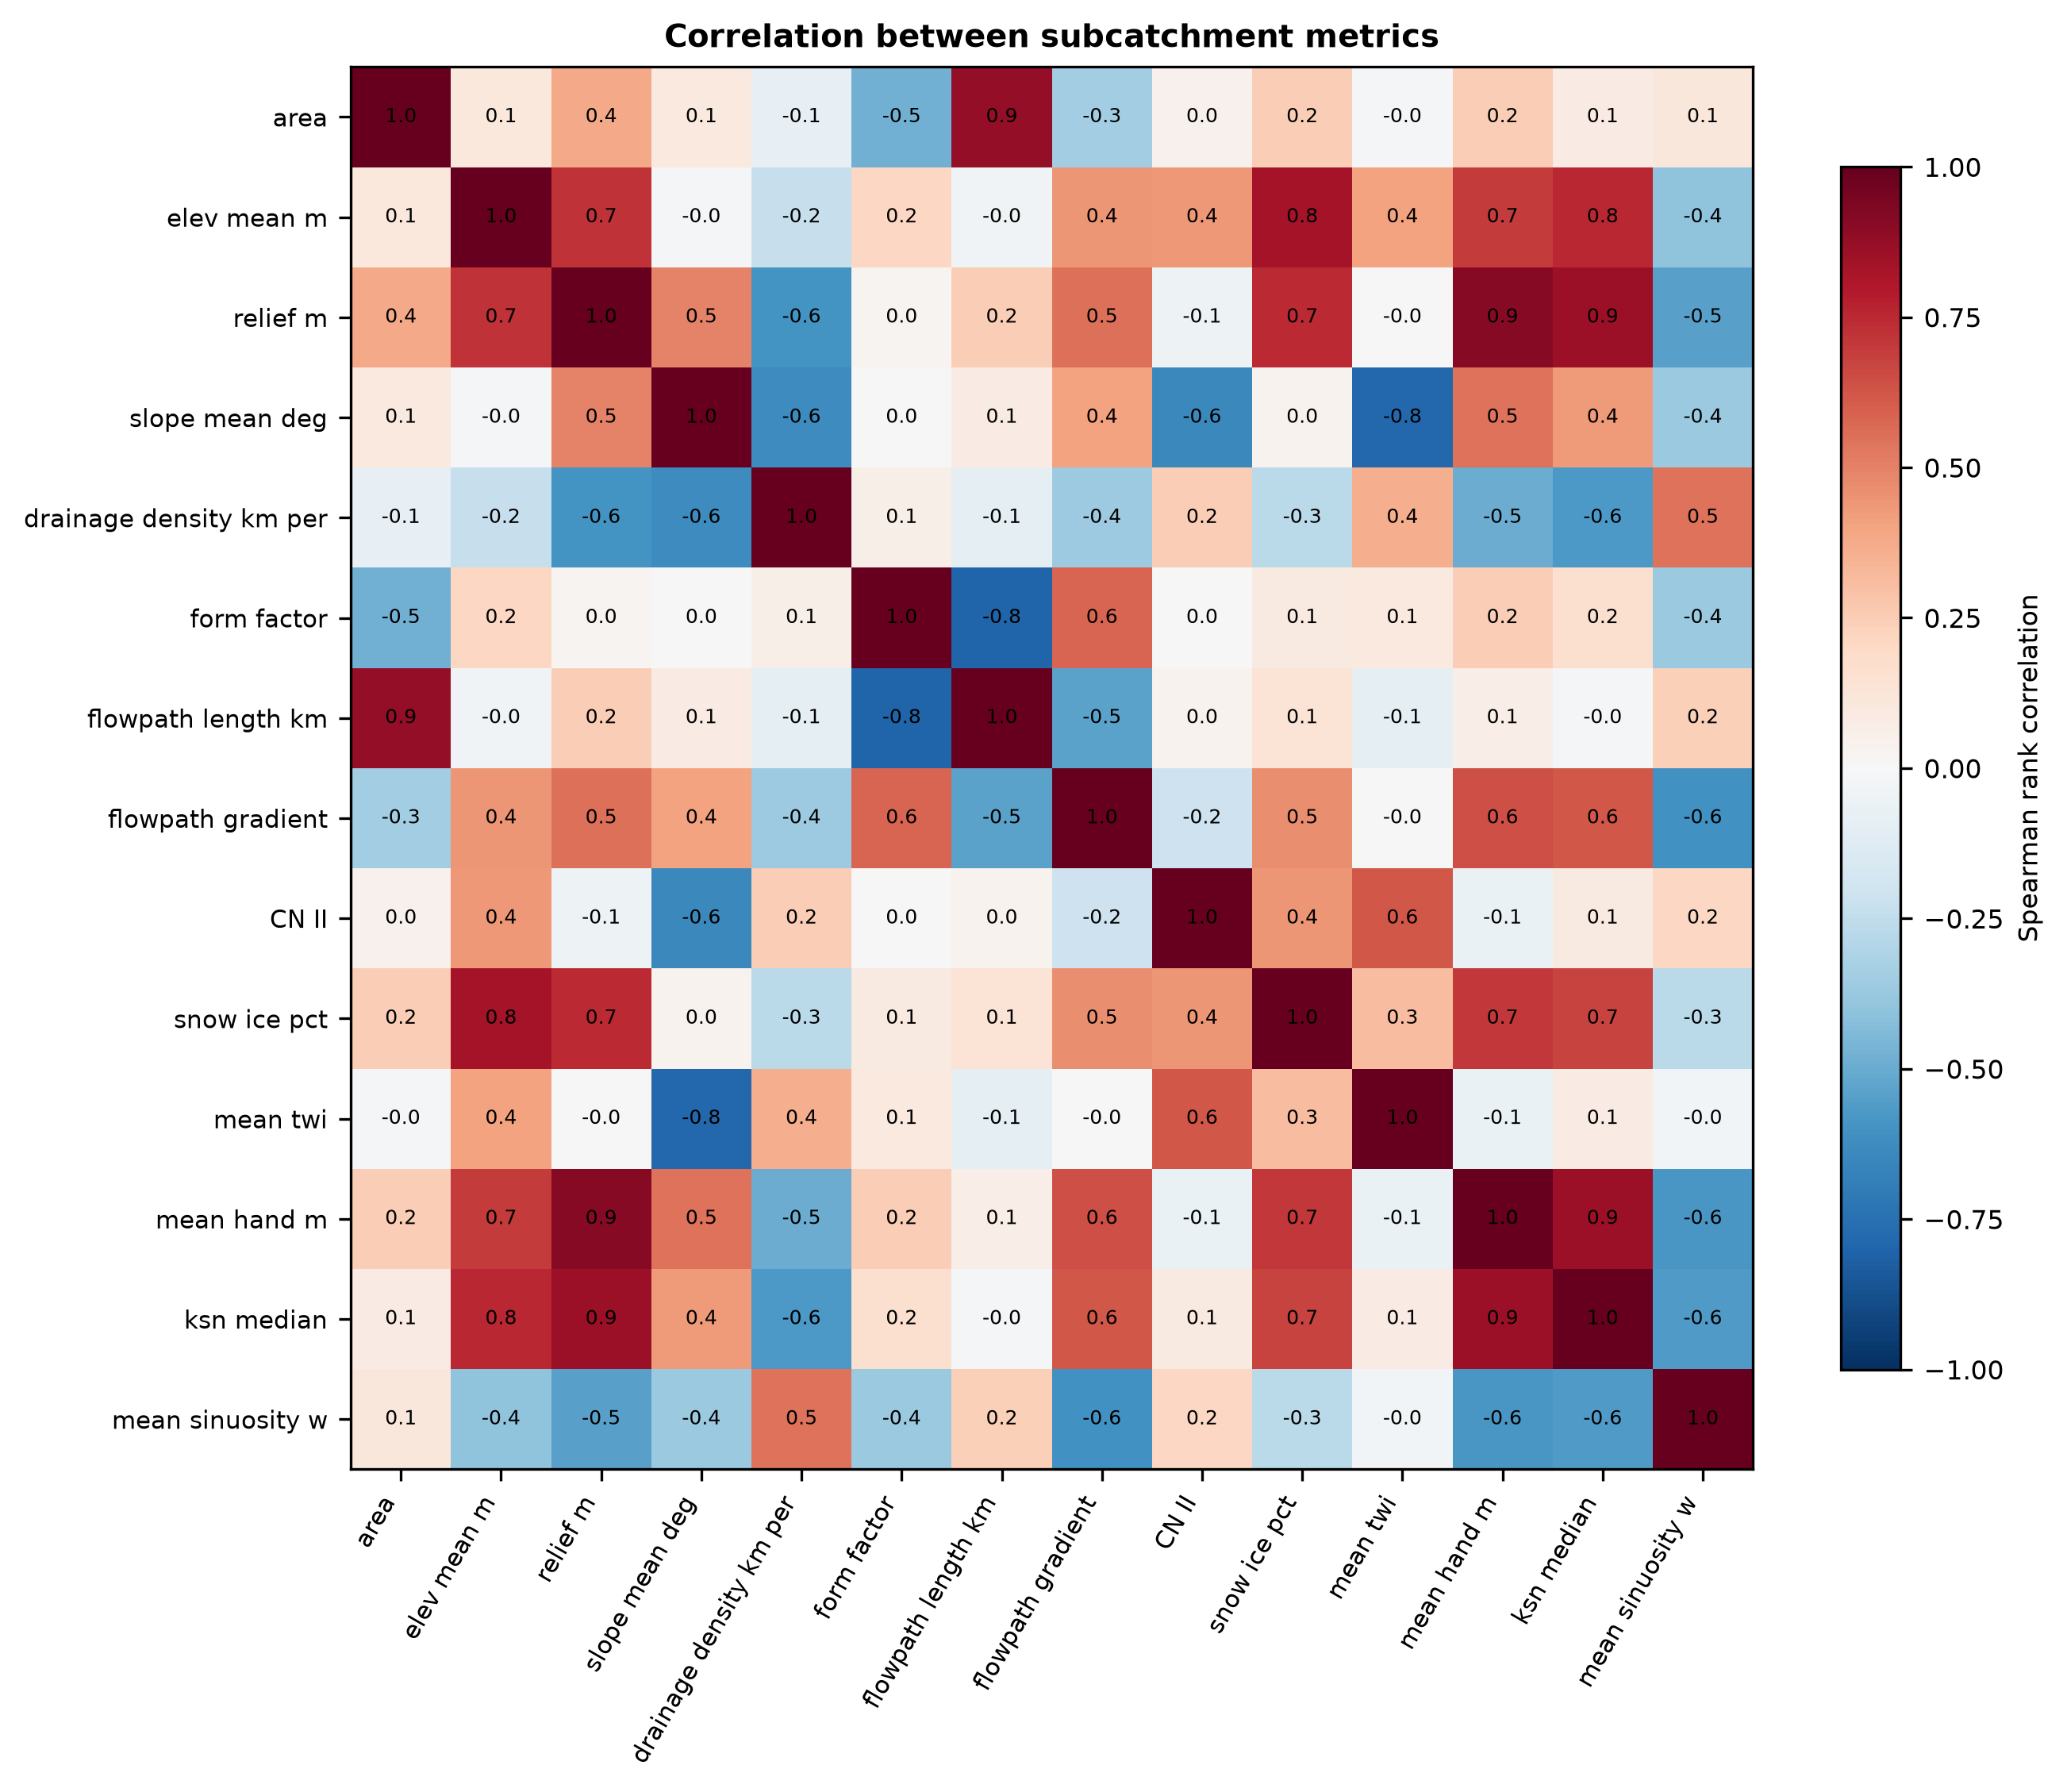

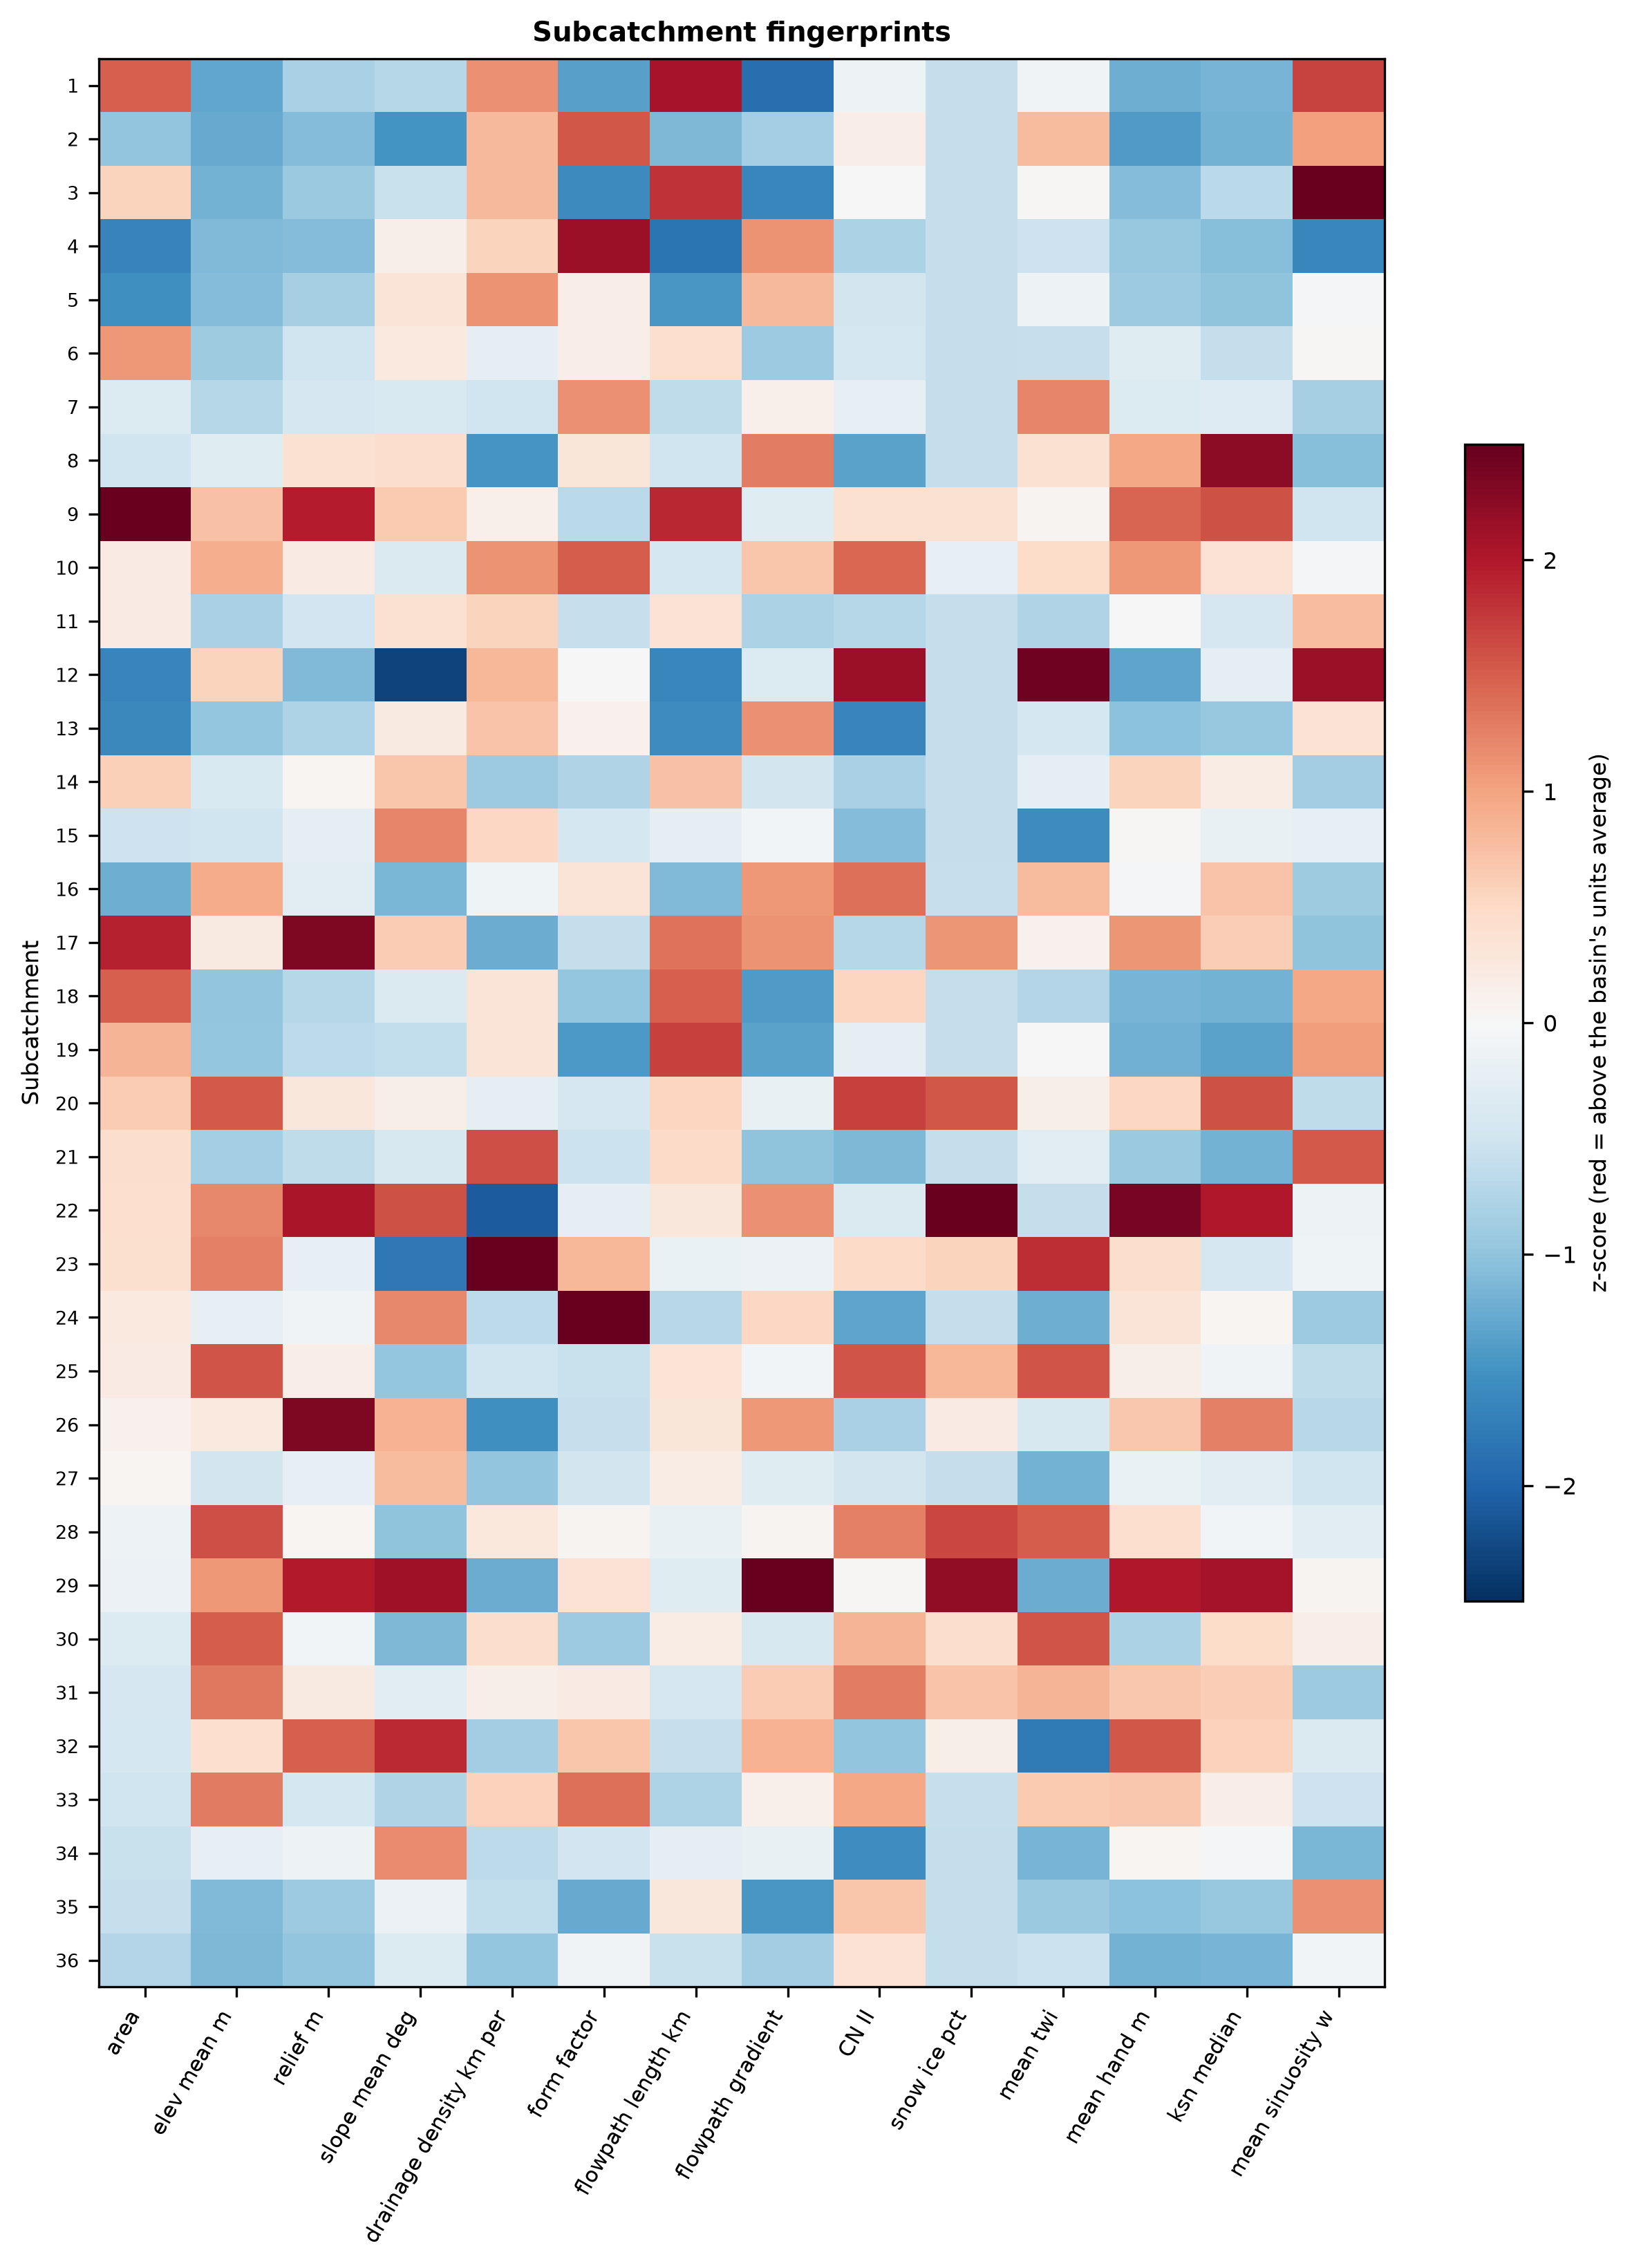

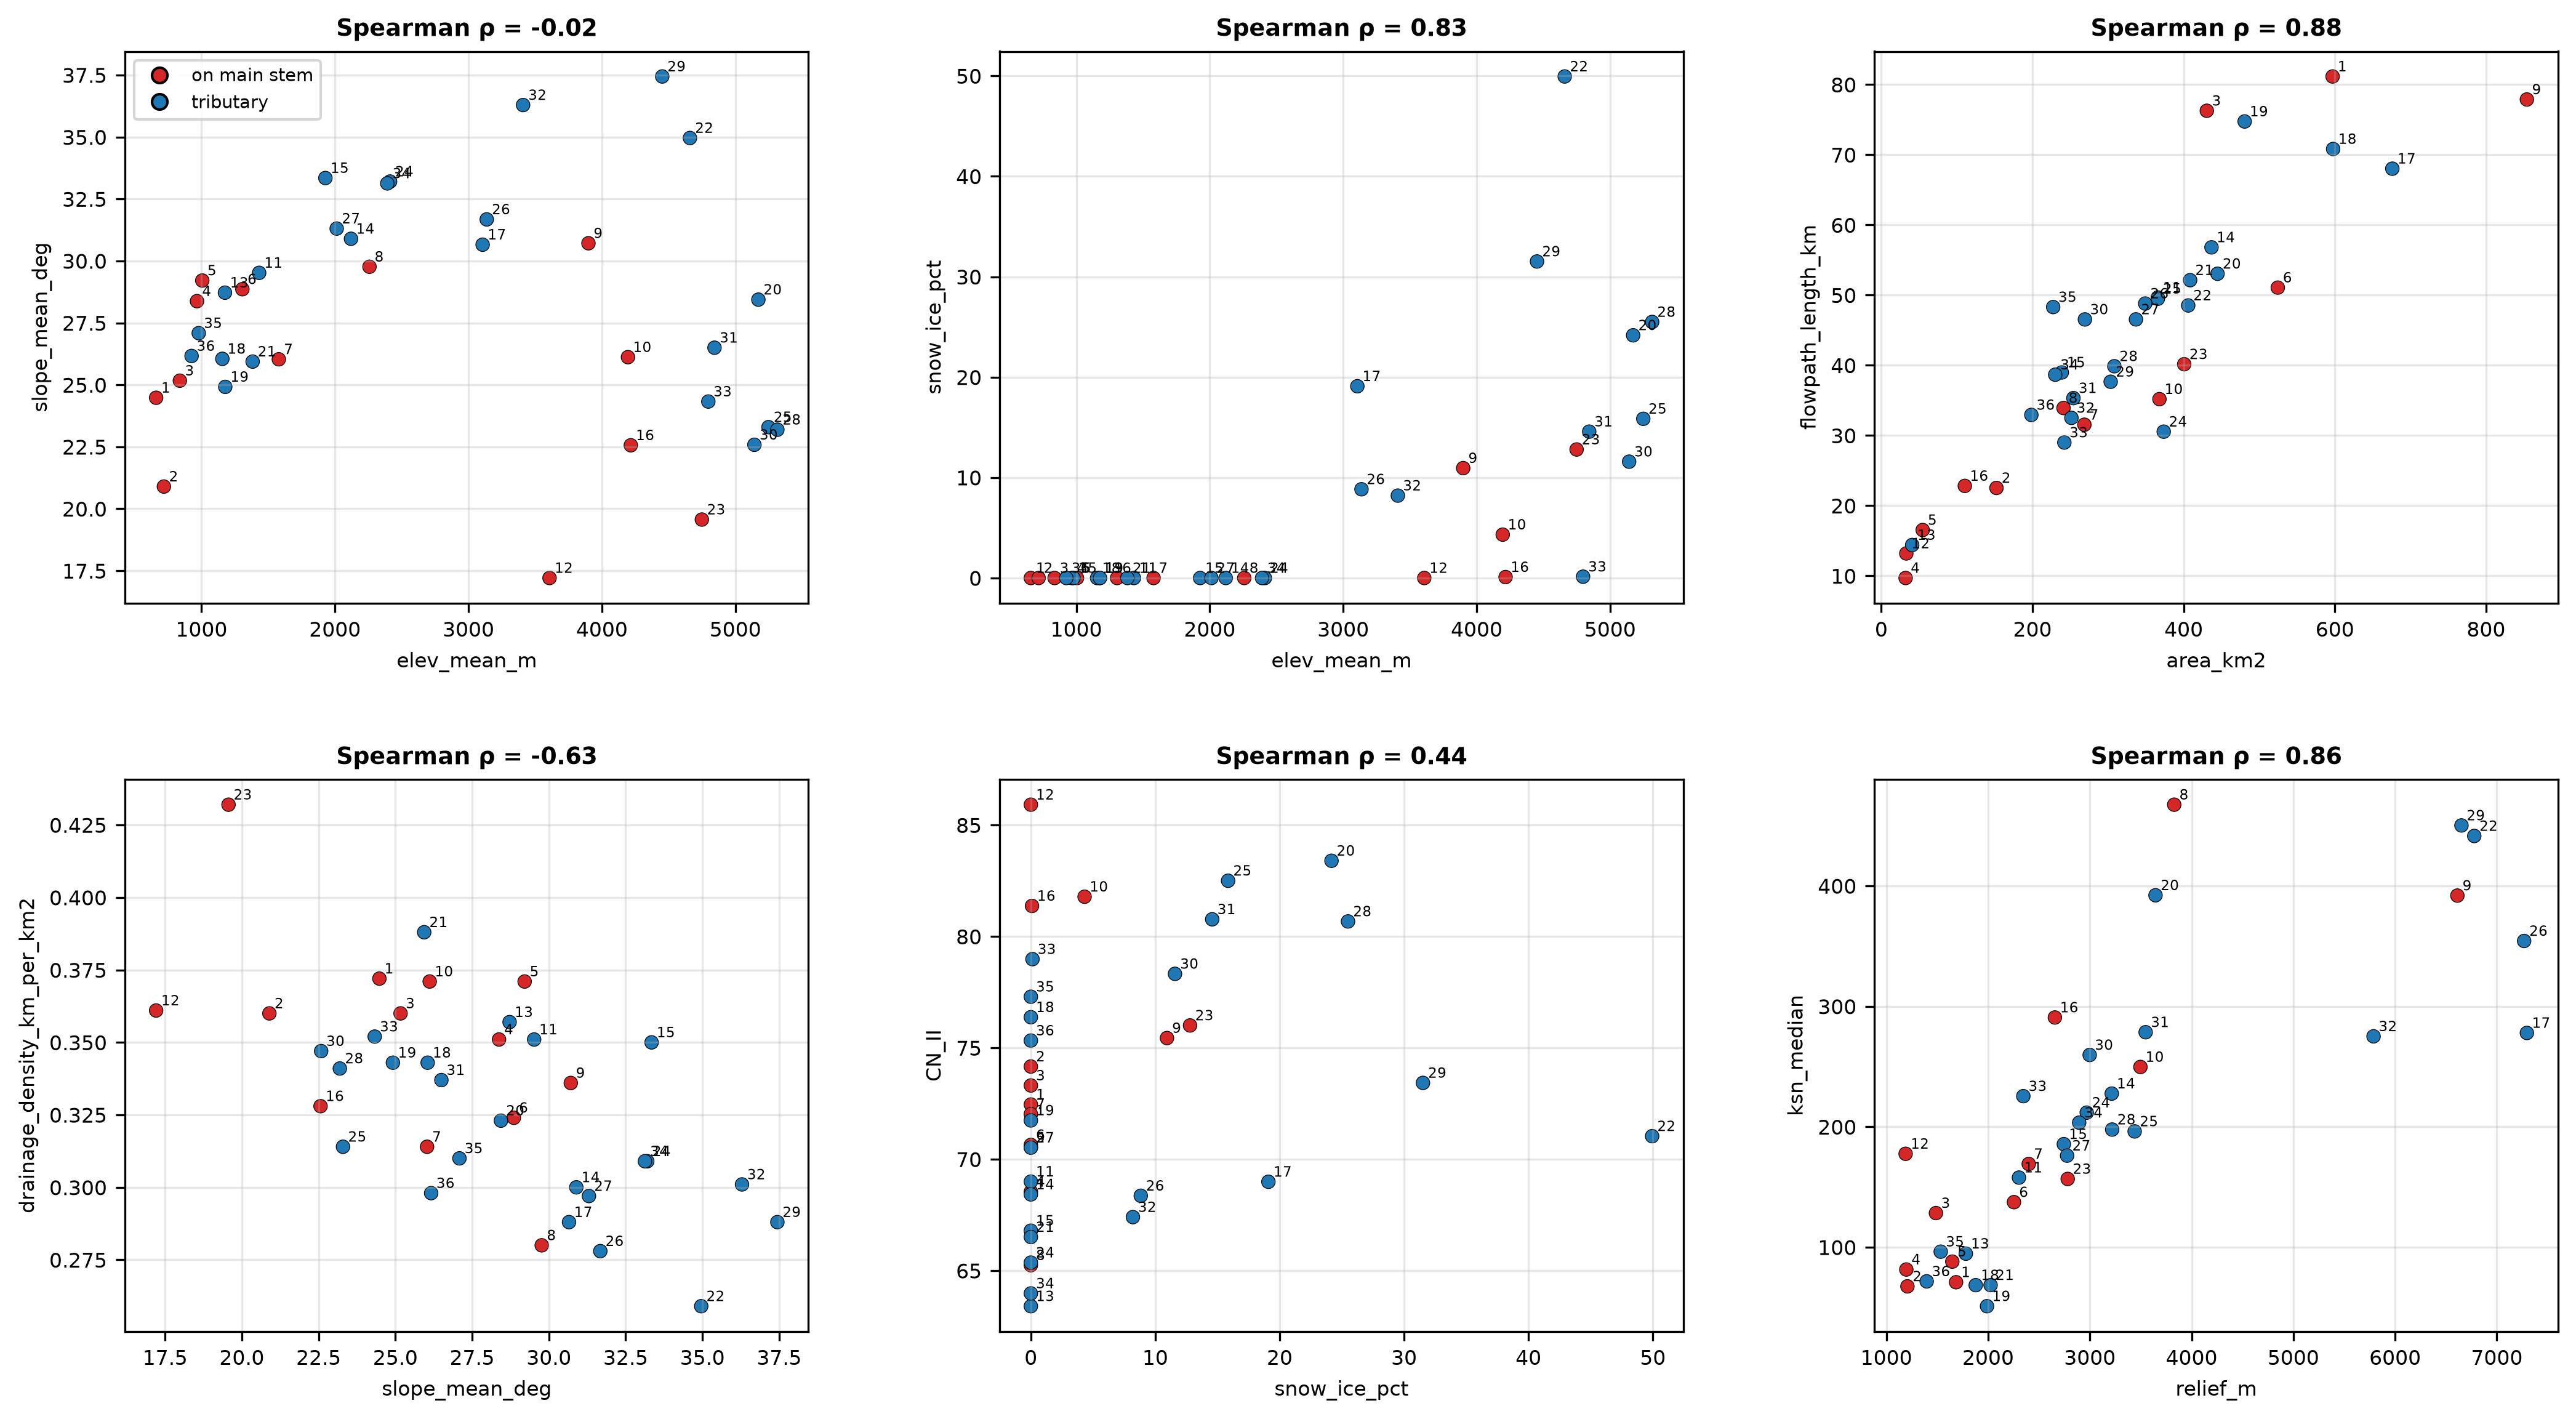

In [5]:
# ============================================================
# Cell 5: subbasin statistics - ranks, z-scores, screening score, correlations, maps
# ============================================================
SCORE_TERMS = {"CN_II": 0.30, "slope_mean_deg": 0.25, "drainage_density_km_per_km2": 0.20,
               "form_factor": 0.15, "tc_kirpich_h": -0.10}     # + = a higher value raises the score; - = a lower value raises it
KEY = ["area_km2", "elev_mean_m", "relief_m", "slope_mean_deg", "drainage_density_km_per_km2", "form_factor",
       "flowpath_length_km", "flowpath_gradient_m_per_m", "CN_II", "snow_ice_pct", "mean_twi", "mean_hand_m",
       "ksn_median", "mean_sinuosity_w"]

rs = pd.read_csv(P.TAB / "06_subcatchment_river_stats.csv")
rs = rs.drop(columns=[c for c in ("stream_length_km", "n_links", "max_order") if c in rs.columns])
sb = master.merge(rs, on="sub_id", how="left").sort_values("sub_id").reset_index(drop=True)
KEY = [c for c in KEY if c in sb.columns and sb[c].notna().any()]
sb["area_share_pct"] = 100 * sb.area_km2 / sb.area_km2.sum()
for c in KEY:
    sb[f"rank_{c}"] = sb[c].rank(ascending=False, method="min").astype("Int64")      # 1 = highest value
    sb[f"z_{c}"] = (sb[c] - sb[c].mean()) / sb[c].std(ddof=0)

terms = {c: w for c, w in SCORE_TERMS.items() if c in sb.columns and sb[c].notna().all()}
tot_w = sum(abs(w) for w in terms.values())
score = np.zeros(len(sb))
for c, w in terms.items():
    rk = sb[c].rank(pct=True).values
    if w < 0:
        rk = 1 - rk + 1 / len(sb)
    score += abs(w) * rk
sb["runoff_screening_score"] = 100 * score / tot_w
sb["score_rank"] = sb.runoff_screening_score.rank(ascending=False, method="min").astype(int)
print(f"Screening score built from {list(terms)} (weights {[terms[c] for c in terms]}). "
      "It ranks units by runoff-producing tendencies; it is NOT a hazard or discharge model.")

save_table(sb.round(4), P.TAB / "07_subbasin_statistics.csv")
dist = sb[KEY].describe().T
dist["cv_pct"] = 100 * dist["std"] / dist["mean"]
dist.insert(0, "metric", dist.index)
save_table(dist.round(4), P.TAB / "07_subbasin_metric_distribution.csv")
display(dist.round(3))

show = [c for c in ["sub_id", "area_km2", "CN_II", "slope_mean_deg", "drainage_density_km_per_km2", "form_factor",
                    "tc_kirpich_h", "snow_ice_pct", "runoff_screening_score", "score_rank", "cn_caution"] if c in sb.columns]
print("\nHighest screening scores:"); display(sb.sort_values("score_rank")[show].head(6).round(2))
print("Lowest screening scores:"); display(sb.sort_values("score_rank")[show].tail(6).round(2))

# ---------- raster and GeoPackage ----------
lab = np.nan_to_num(read_grid(P.RAS / "subcatchments.tif"), nan=0).astype(int)
lut = np.concatenate([[np.nan], sb.runoff_screening_score.values])
ws.save(lut[lab].astype("float32"), P.RAS / "subbasin_runoff_score.tif")
del lab
geom = gpd.read_file(P.VEC / "subcatchments.gpkg")[["sub_id", "geometry"]]
gfull = geom.merge(sb, on="sub_id", how="left")
gfull = gfull.astype({c: "float64" for c in gfull.columns if str(gfull[c].dtype) == "Int64"})
gfull.to_file(P.VEC / "subbasin_statistics.gpkg", driver="GPKG")


def choropleth(col, fname, title, label, cmap="YlOrRd", fmt="{:.0f}"):
    vals = gfull[col].values.astype(float)
    e = ws.extent
    fig, ax = plt.subplots(figsize=(8.6, float(np.clip(8 * (e[3] - e[2]) / (e[1] - e[0]), 5, 11))))
    gfull.plot(ax=ax, column=col, cmap=cmap, edgecolor="0.25", linewidth=0.4, legend=False)
    cax = make_axes_locatable(ax).append_axes("right", size="3%", pad=0.12)
    cb = fig.colorbar(plt.cm.ScalarMappable(cmap=cmap, norm=mcolors.Normalize(vmin=np.nanmin(vals), vmax=np.nanmax(vals))), cax=cax)
    cb.set_label(label, fontsize=7.5); cb.ax.tick_params(labelsize=6.5)
    for p_, i_, v_ in zip(gfull.representative_point(), gfull["sub_id"], vals):
        ax.text(p_.x, p_.y, f"{i_}\n{fmt.format(v_)}" if np.isfinite(v_) else str(i_), fontsize=5, ha="center", va="center")
    map_furniture(ax, ws, title)
    fig.savefig(P.FIG / fname, dpi=300, bbox_inches="tight", facecolor="white")
    plt.show(); plt.close(fig)

for col, fn, ttl, lbl, cm, fm in [
        ("runoff_screening_score", "07_map_screening_score.png", "Runoff screening score (rank-based, 0-100)", "score", "YlOrRd", "{:.0f}"),
        ("slope_mean_deg", "07_map_mean_slope.png", "Mean slope per subcatchment", "slope (deg)", "YlOrBr", "{:.0f}"),
        ("drainage_density_km_per_km2", "07_map_drainage_density.png", "Drainage density per subcatchment", "km/km²", "Blues", "{:.2f}"),
        ("ksn_median", "07_map_ksn.png", "Median channel steepness (ksn)", "ksn", "plasma", "{:.0f}")]:
    if col in gfull.columns:
        choropleth(col, fn, ttl, lbl, cm, fm)

# ---------- correlations ----------
corr = sb[KEY].corr(method="spearman")
save_table(corr.round(3).reset_index().rename(columns={"index": "metric"}), P.TAB / "07_subbasin_correlation.csv")
lbl = [c.replace("_km2", "").replace("_m_per_m", "").replace("_per_km2", "").replace("_", " ") for c in KEY]
fig, ax = plt.subplots(figsize=(9.5, 8.2))
im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(KEY))); ax.set_xticklabels(lbl, rotation=60, ha="right", fontsize=7.5)
ax.set_yticks(range(len(KEY))); ax.set_yticklabels(lbl, fontsize=7.5)
for i in range(len(KEY)):
    for j in range(len(KEY)):
        ax.text(j, i, f"{corr.values[i, j]:.1f}", ha="center", va="center", fontsize=6)
fig.colorbar(im, ax=ax, shrink=0.8, label="Spearman rank correlation")
ax.set_title("Correlation between subcatchment metrics", fontweight="bold")
fig.savefig(P.FIG / "07_subbasin_correlation.png", dpi=250, bbox_inches="tight", facecolor="white")
plt.show(); plt.close(fig)

# ---------- fingerprint heatmap (z-scores) ----------
Z = sb[[f"z_{c}" for c in KEY]].values
fig, ax = plt.subplots(figsize=(10, 0.28 * len(sb) + 2))
im = ax.imshow(Z, cmap="RdBu_r", vmin=-2.5, vmax=2.5, aspect="auto")
ax.set_xticks(range(len(KEY))); ax.set_xticklabels(lbl, rotation=60, ha="right", fontsize=7.5)
ax.set_yticks(range(len(sb))); ax.set_yticklabels(sb.sub_id, fontsize=6.5); ax.set_ylabel("Subcatchment")
fig.colorbar(im, ax=ax, shrink=0.6, label="z-score (red = above the basin's units average)")
ax.set_title("Subcatchment fingerprints", fontweight="bold")
fig.savefig(P.FIG / "07_subbasin_fingerprints.png", dpi=250, bbox_inches="tight", facecolor="white")
plt.show(); plt.close(fig)

# ---------- scatter panels ----------
PAIRS = [("elev_mean_m", "slope_mean_deg"), ("elev_mean_m", "snow_ice_pct"), ("area_km2", "flowpath_length_km"),
         ("slope_mean_deg", "drainage_density_km_per_km2"), ("snow_ice_pct", "CN_II"), ("relief_m", "ksn_median")]
PAIRS = [(a_, b_) for a_, b_ in PAIRS if a_ in sb.columns and b_ in sb.columns]
fig, axs = plt.subplots(2, 3, figsize=(17, 9), gridspec_kw={"hspace": 0.32, "wspace": 0.28})
cols = np.where(sb.on_main_stem.astype(bool), "tab:red", "tab:blue")
for ax, (a_, b_) in zip(axs.ravel(), PAIRS):
    ax.scatter(sb[a_], sb[b_], c=cols, s=28, edgecolor="k", linewidth=0.3)
    for x_, y_, i_ in zip(sb[a_], sb[b_], sb.sub_id):
        ax.annotate(str(i_), (x_, y_), fontsize=5.5, xytext=(2, 2), textcoords="offset points")
    rho = sb[[a_, b_]].corr(method="spearman").iloc[0, 1]
    ax.set_xlabel(a_); ax.set_ylabel(b_); ax.set_title(f"Spearman ρ = {rho:.2f}", fontsize=9, fontweight="bold"); ax.grid(alpha=0.3)
for ax in axs.ravel()[len(PAIRS):]:
    ax.axis("off")
axs[0, 0].legend(handles=[Line2D([0], [0], marker="o", color="w", mfc="tab:red", mec="k", label="on main stem"),
                          Line2D([0], [0], marker="o", color="w", mfc="tab:blue", mec="k", label="tributary")],
                 fontsize=7, loc="best")
fig.savefig(P.FIG / "07_subbasin_scatter.png", dpi=250, bbox_inches="tight", facecolor="white")
plt.show(); plt.close(fig)

,section,metric,value,unit
0,main_stem,length_km,417.87142,km
1,main_stem,head_elev_m,5633.35040,m
2,main_stem,outlet_elev_m,185.08550,m
3,main_stem,total_drop_m,5448.26490,m
4,main_stem,mean_gradient_m_per_m,0.01304,m/m
5,main_stem,median_gradient_m_per_m,0.00420,m/m
6,main_stem,p90_gradient_m_per_m,0.03450,m/m
7,main_stem,steepest_10km_gradient,0.08430,m/m
8,main_stem,gentlest_10km_gradient,0.00070,m/m
9,main_stem,profile_concavity_index,0.54922,-


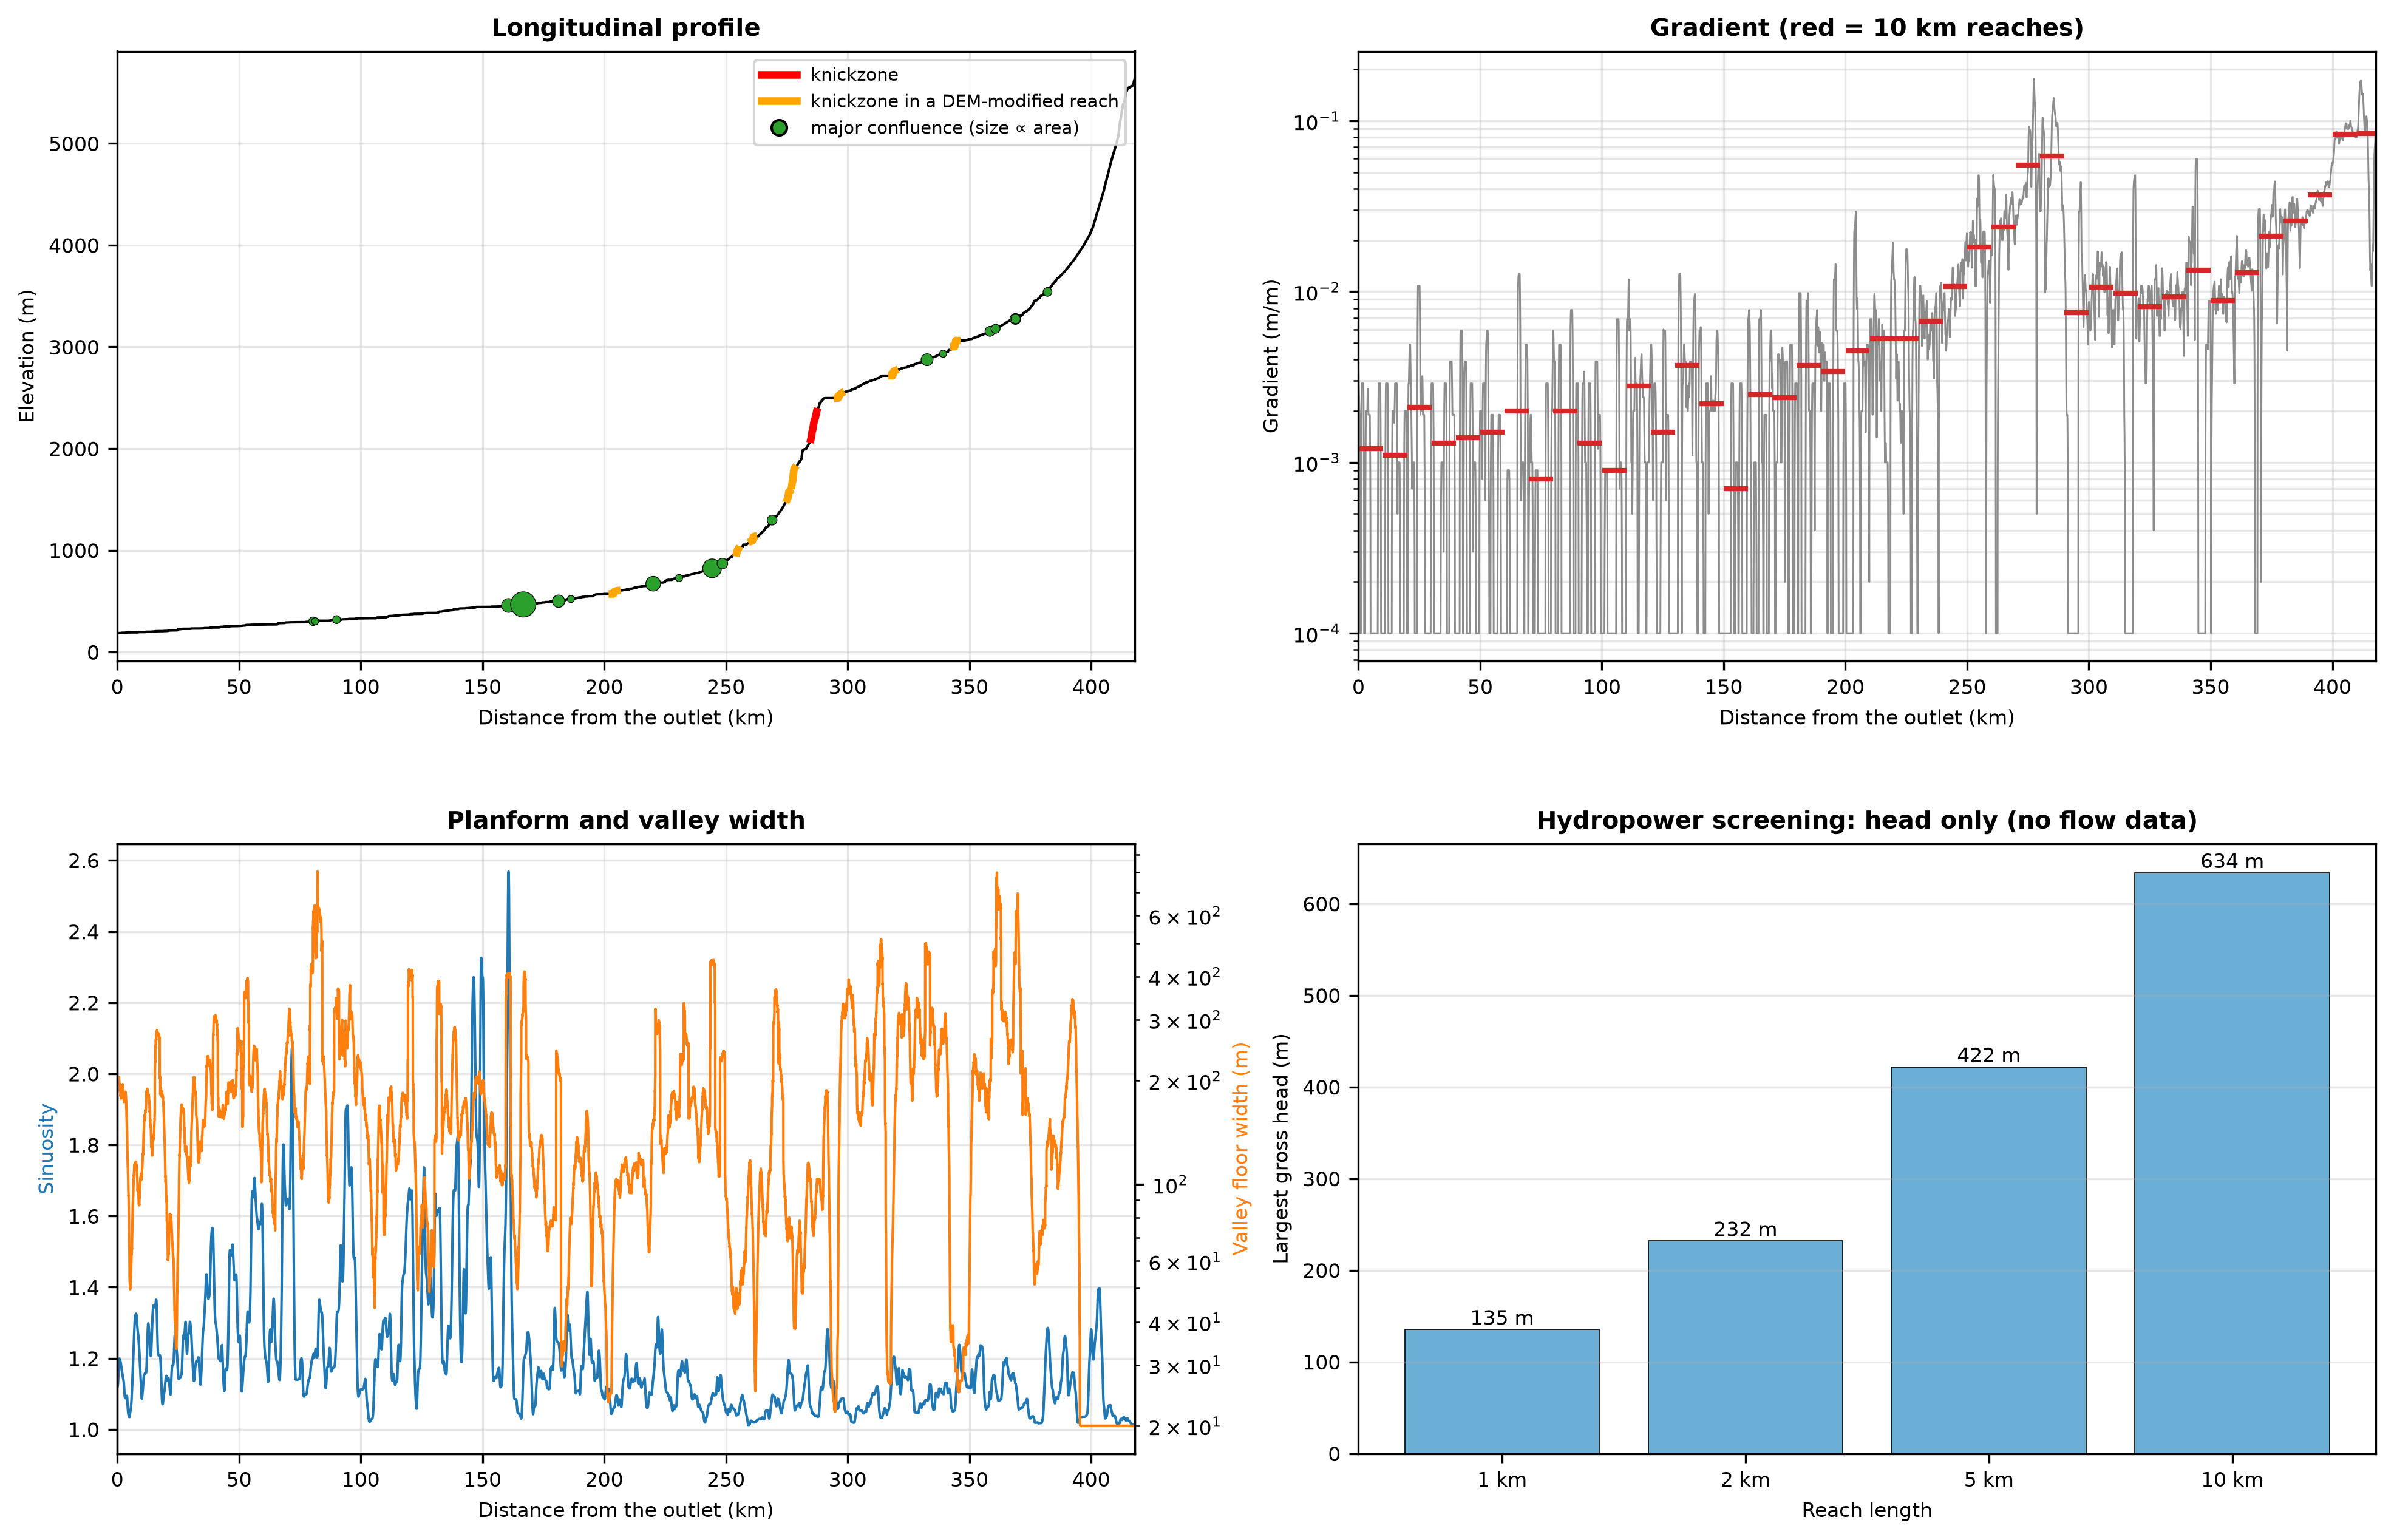

In [6]:
# ============================================================
# Cell 6: river statistics -> 07_river_statistics.csv
# ============================================================
def opt(name):
    p = P.TAB / name
    return pd.read_csv(p) if p.exists() else None

rsum = pd.read_csv(P.TAB / "06_river_summary.csv").set_index("metric")["value"]
reach = pd.read_csv(P.TAB / "06_reaches_10km.csv")
conf = pd.read_csv(P.TAB / "06_confluences.csv")
kz, bends, hp, trib = opt("06_knickzones.csv"), opt("06_bends.csv"), opt("06_hydropower_main_stem.csv"), opt("06_hydropower_tributary_links.csv")

d = river_t.d_out_m.values; zs = river_t.z_smooth.values; gr = river_t.gradient.values
L = float(d.max()); drop = float(zs[0] - zs[-1])
rows = []
add(rows, "main_stem", "length_km", L / 1000, "km")
add(rows, "main_stem", "head_elev_m", zs[0], "m"); add(rows, "main_stem", "outlet_elev_m", zs[-1], "m")
add(rows, "main_stem", "total_drop_m", drop, "m")
add(rows, "main_stem", "mean_gradient_m_per_m", drop / L, "m/m")
add(rows, "main_stem", "median_gradient_m_per_m", float(np.median(gr)), "m/m", "1 km window")
add(rows, "main_stem", "p90_gradient_m_per_m", float(np.percentile(gr, 90)), "m/m")
add(rows, "main_stem", "steepest_10km_gradient", float(reach.gradient_m_per_m.max()), "m/m",
    f"block starting {reach.loc[reach.gradient_m_per_m.idxmax(), 'from_km']:.0f} km from the outlet")
add(rows, "main_stem", "gentlest_10km_gradient", float(reach.gradient_m_per_m.min()), "m/m",
    f"block starting {reach.loc[reach.gradient_m_per_m.idxmin(), 'from_km']:.0f} km from the outlet")
xn = river_t.s_m.values / river_t.s_m.max()
en = (zs - zs[-1]) / max(zs[0] - zs[-1], 1e-9)
integral = float(np.sum((en[1:] + en[:-1]) / 2 * np.diff(xn)))
add(rows, "main_stem", "profile_concavity_index", 1 - 2 * integral, "-", "0 = straight, > 0 = concave-up (steep headwaters)")
for k_, (a_, b_) in enumerate([(0, 1 / 3), (1 / 3, 2 / 3), (2 / 3, 1.0)], start=1):
    i0 = int(np.searchsorted(xn, a_)); i1 = min(int(np.searchsorted(xn, b_, side="right")) - 1, len(xn) - 1)
    add(rows, "main_stem", f"drop_share_third_{k_}_pct", 100 * (zs[i0] - zs[i1]) / drop, "%",
        "third 1 = headwaters, third 3 = lower reach")

for k_ in ("slope_area_theta", "slope_area_ks", "slope_area_r2", "ksn_median"):
    if k_ in rsum.index:
        add(rows, "slope_area", k_, float(rsum[k_]), "-")

add(rows, "planform", "sinuosity_overall", float(rsum.get("sinuosity_overall", np.nan)), "-", "30 m raster line, approximate")
for c_ in ("sin_1km", "sin_5km"):
    if c_ in river_t.columns:
        v = river_t[c_].dropna()
        add(rows, "planform", f"{c_}_median", float(v.median()), "-"); add(rows, "planform", f"{c_}_p90", float(np.percentile(v, 90)), "-")
add(rows, "planform", "radius_of_curvature_median_m", float(river_t.radius_m.median()), "m")
vw = river_t.valley_width_m
add(rows, "planform", "valley_width_median_m", float(vw.median()), "m", "HAND-based valley floor")
add(rows, "planform", "valley_width_p90_m", float(np.percentile(vw, 90)), "m")
for lb, sh in river_t.confinement.value_counts(normalize=True).items():
    add(rows, "planform", f"pct_length_{lb.split(' (')[0].replace(' ', '_')}", 100 * float(sh), "%")
if bends is not None and len(bends):
    add(rows, "bends", "n_bends", len(bends), "-"); add(rows, "bends", "n_bends_tight", int(bends.tight.sum()), "-")
    add(rows, "bends", "mean_bend_sinuosity", float(bends.sinuosity.mean()), "-")
    for lb, g_ in bends.groupby("bend_class"):
        add(rows, "bends", f"n_{lb.split(' (')[0].replace(' ', '_')}", len(g_), "-")

if kz is not None and len(kz):
    real = kz[~kz.likely_artefact]
    add(rows, "knickzones", "n_knickzones", len(kz), "-")
    add(rows, "knickzones", "n_knickzones_major", int((kz.kz_class == "major").sum()), "-")
    add(rows, "knickzones", "n_knickzones_artefact", int(kz.likely_artefact.sum()), "-", "overlap DEM-modified reaches")
    add(rows, "knickzones", "knickzone_drop_m", float(real.drop_m.sum()), "m", "excluding artefacts")
    add(rows, "knickzones", "knickzone_drop_share_pct", 100 * float(real.drop_m.sum()) / drop, "%")
    add(rows, "knickzones", "knickzones_per_100km", 100 * len(real) / (L / 1000), "1/100km", "excluding artefacts")
    if len(real):
        big = real.loc[real.drop_m.idxmax()]
        add(rows, "knickzones", "largest_knickzone_drop_m", float(big.drop_m), "m",
            f"id {int(big.kz_id)}, lip {big.lip_dist_from_outlet_km:.0f} km from the outlet")
else:
    add(rows, "knickzones", "n_knickzones", 0, "-")

add(rows, "confluences", "n_major_confluences", len(conf), "-")
add(rows, "confluences", "n_tributary_larger_than_main", int(conf.tributary_larger_than_main.sum()), "-")
add(rows, "confluences", "largest_tributary_area_km2", float(conf.tributary_area_km2.max()), "km2")
runs = int(np.sum(np.diff(np.r_[0, river_t.dem_modified.astype(int).values]) == 1))
add(rows, "dem_quality", "pct_main_stem_dem_modified", 100 * float(river_t.dem_modified.mean()), "%")
add(rows, "dem_quality", "n_dem_modified_zones", runs, "-")

if hp is not None and len(hp):
    for w_, g_ in hp.groupby("window_km"):
        b = g_.loc[g_.gross_head_m.idxmax()]
        add(rows, "hydropower_screening", f"max_head_{w_:g}km_m", float(b.gross_head_m), "m",
            f"intake {b.intake_km_from_outlet:.0f} km from the outlet at {b.intake_elev_m:.0f} m")
        add(rows, "hydropower_screening", f"max_power_{w_:g}km_MW_placeholder_flow", float(g_.power_MW.max()), "MW",
            "uses the placeholder specific discharge from notebook 06; indicative only")
if trib is not None and len(trib):
    add(rows, "hydropower_screening", "top_tributary_link_power_MW_placeholder_flow", float(trib.power_MW.max()), "MW",
        "placeholder flow")

add(rows, "network", "total_link_length_km", float(links.length_km.sum()), "km")
add(rows, "network", "median_link_gradient", float(links.gradient_m_per_m.median()), "m/m")
add(rows, "network", "pct_network_length_gradient_gt_0.1", 100 * float(links.loc[links.gradient_m_per_m > 0.1, "length_km"].sum() / links.length_km.sum()), "%")
add(rows, "network", "median_ksn", float(links.ksn.median()), "-")

riv_stats = pd.DataFrame(rows)
riv_stats["value"] = riv_stats["value"].astype(float).round(5)
save_table(riv_stats, P.TAB / "07_river_statistics.csv")
display(riv_stats[["section", "metric", "value", "unit"]])

# ---------- figure ----------
x_km = d / 1000
fig, axs = plt.subplots(2, 2, figsize=(16, 10), gridspec_kw={"hspace": 0.3, "wspace": 0.22})
ax = axs[0, 0]
ax.plot(x_km, zs, color="k", lw=1)
for kid, gk in river_t[river_t.knickzone_id > 0].groupby("knickzone_id"):
    ax.plot(gk.d_out_m / 1000, gk.z_smooth, color="orange" if gk.dem_modified.mean() >= 0.3 else "red", lw=3)
ax.scatter(conf.dist_from_outlet_km, conf.elev_m, s=np.clip(conf.tributary_area_km2 / 20, 8, 120),
           color="tab:green", edgecolor="k", linewidth=0.3, zorder=5)
ax.legend(handles=[Line2D([0], [0], color="red", lw=3, label="knickzone"),
                   Line2D([0], [0], color="orange", lw=3, label="knickzone in a DEM-modified reach"),
                   Line2D([0], [0], marker="o", color="w", mfc="tab:green", mec="k", label="major confluence (size ∝ area)")],
          fontsize=7, loc="upper right")
ax.set_xlabel("Distance from the outlet (km)"); ax.set_ylabel("Elevation (m)"); ax.set_xlim(0, x_km.max())
ax.set_title("Longitudinal profile", fontweight="bold"); ax.grid(alpha=0.3)

ax = axs[0, 1]
ax.semilogy(x_km, np.maximum(gr, 1e-4), color="0.55", lw=0.7, label="1 km gradient")
for _, r_ in reach.iterrows():
    ax.hlines(r_.gradient_m_per_m, r_.from_km, r_.to_km, color="tab:red", lw=2)
ax.set_xlabel("Distance from the outlet (km)"); ax.set_ylabel("Gradient (m/m)"); ax.set_xlim(0, x_km.max())
ax.set_title("Gradient (red = 10 km reaches)", fontweight="bold"); ax.grid(alpha=0.3, which="both")

ax = axs[1, 0]
ax.plot(x_km, river_t.sin_5km, color="tab:blue", lw=1, label="sinuosity (5 km)")
ax.set_xlabel("Distance from the outlet (km)"); ax.set_ylabel("Sinuosity", color="tab:blue"); ax.set_xlim(0, x_km.max())
ax2 = ax.twinx()
ax2.semilogy(x_km, np.maximum(vw, 20), color="tab:orange", lw=1)
ax2.set_ylabel("Valley floor width (m)", color="tab:orange")
ax.set_title("Planform and valley width", fontweight="bold"); ax.grid(alpha=0.3)

ax = axs[1, 1]
if hp is not None and len(hp):
    mh = hp.groupby("window_km").gross_head_m.max()
    ax.bar([f"{w_:g} km" for w_ in mh.index], mh.values, color="#6baed6", edgecolor="k", linewidth=0.4)
    for i_, v_ in enumerate(mh.values):
        ax.text(i_, v_, f"{v_:.0f} m", ha="center", va="bottom", fontsize=8)
    ax.set_ylabel("Largest gross head (m)"); ax.set_xlabel("Reach length")
    ax.set_title("Hydropower screening: head only (no flow data)", fontweight="bold"); ax.grid(alpha=0.3, axis="y")
else:
    ax.axis("off")
fig.savefig(P.FIG / "07_river_statistics_panel.png", dpi=250, bbox_inches="tight", facecolor="white")
plt.show(); plt.close(fig)

,layer,unit,min,p2,p25,median,mean,p75,p98,max,std
0,TWI,-,1.096580,3.63527,4.80157,5.56824,6.005100,6.66047,11.61216,2.615685e+01,1.921400e+00
1,SPI,m,0.051510,3.56409,30.75816,80.89509,26856.541016,223.65964,7900.35475,5.759052e+08,1.252215e+06
2,STI,-,0.009390,1.88891,15.17264,26.59169,36.749722,42.11388,137.86844,1.918759e+04,8.627735e+01
3,SCA (D-inf),m,29.512739,29.51274,60.41986,136.56827,218897.421875,379.79131,25184.10156,4.022960e+08,7.773295e+06
4,flow length to outlet,m,29.512739,49681.68750,209479.78125,257303.03125,260435.468750,330074.28125,406986.59375,4.223041e+05,9.391912e+04
5,longest upstream flowpath,m,0.000000,0.00000,0.00000,71.25005,480.880615,201.52557,1835.21313,4.222746e+05,7.462933e+03
6,slope (conditioned DEM),deg,0.000030,4.16247,19.10460,27.95771,28.173361,36.66361,55.79784,8.485869e+01,1.273862e+01
7,HAND,m,0.000000,30.00043,381.00000,724.00195,887.601440,1210.00000,2841.00073,5.688001e+03,6.965415e+02
8,flow distance to stream,m,0.000000,130.27551,2316.67456,5516.63184,6704.306152,9671.48438,21256.72852,3.553111e+04,5.500460e+03
9,distance to stream,m,0.000000,106.40968,1547.37952,3394.47778,3856.239746,5623.55078,10727.21973,1.641402e+04,2.807627e+03


,section,metric,value
0,flowpath_and_conditioning,longest_flowpath_km,422.27460
1,flowpath_and_conditioning,flowpath_source_elev_m,6148.00000
2,flowpath_and_conditioning,flowpath_outlet_elev_m,184.00000
3,flowpath_and_conditioning,flowpath_mean_gradient_m_per_m,0.01410
4,flowpath_and_conditioning,cells_changed_by_conditioning_pct,0.70720
5,flowpath_and_conditioning,net_volume_change_million_m3,-416.47880
6,flow_accumulation,pct_cells_area_ge_1_km2,1.71500
7,flow_accumulation,pct_cells_area_ge_10_km2,0.61200
8,flow_accumulation,pct_cells_area_ge_100_km2,0.22200
9,flow_accumulation,pct_cells_area_ge_1000_km2,0.08900


,section,metric,value,unit
0,landcover,area_tree_cover_km2,6026.04459,km2
1,landcover,pct_tree_cover,50.75381,%
2,landcover,area_shrubland_km2,12.57901,km2
3,landcover,pct_shrubland,0.10595,%
4,landcover,area_grassland_km2,1730.28213,km2
5,landcover,pct_grassland,14.57314,%
6,landcover,area_cropland_km2,379.39349,km2
7,landcover,pct_cropland,3.19541,%
8,landcover,area_built_up_km2,24.19730,km2
9,landcover,pct_built_up,0.20380,%


,A,B,C,D,no soil group,total_km2
Tree cover,24.46,3319.78,1.66,2680.14,0.0,6026.04
Shrubland,0.00,3.24,0.00,9.34,0.0,12.58
Grassland,43.39,1347.12,3.04,336.74,0.0,1730.28
Cropland,0.02,229.15,0.00,150.22,0.0,379.39
Built-up,0.01,16.03,0.00,8.15,0.0,24.20
Bare / sparse vegetation,455.72,1872.10,6.77,7.73,0.0,2342.32
Snow and ice,530.92,419.62,1.70,0.00,0.0,952.24
Permanent water,3.60,46.82,0.00,3.38,0.0,53.81
Moss and lichen,26.31,325.56,0.35,0.00,0.0,352.22


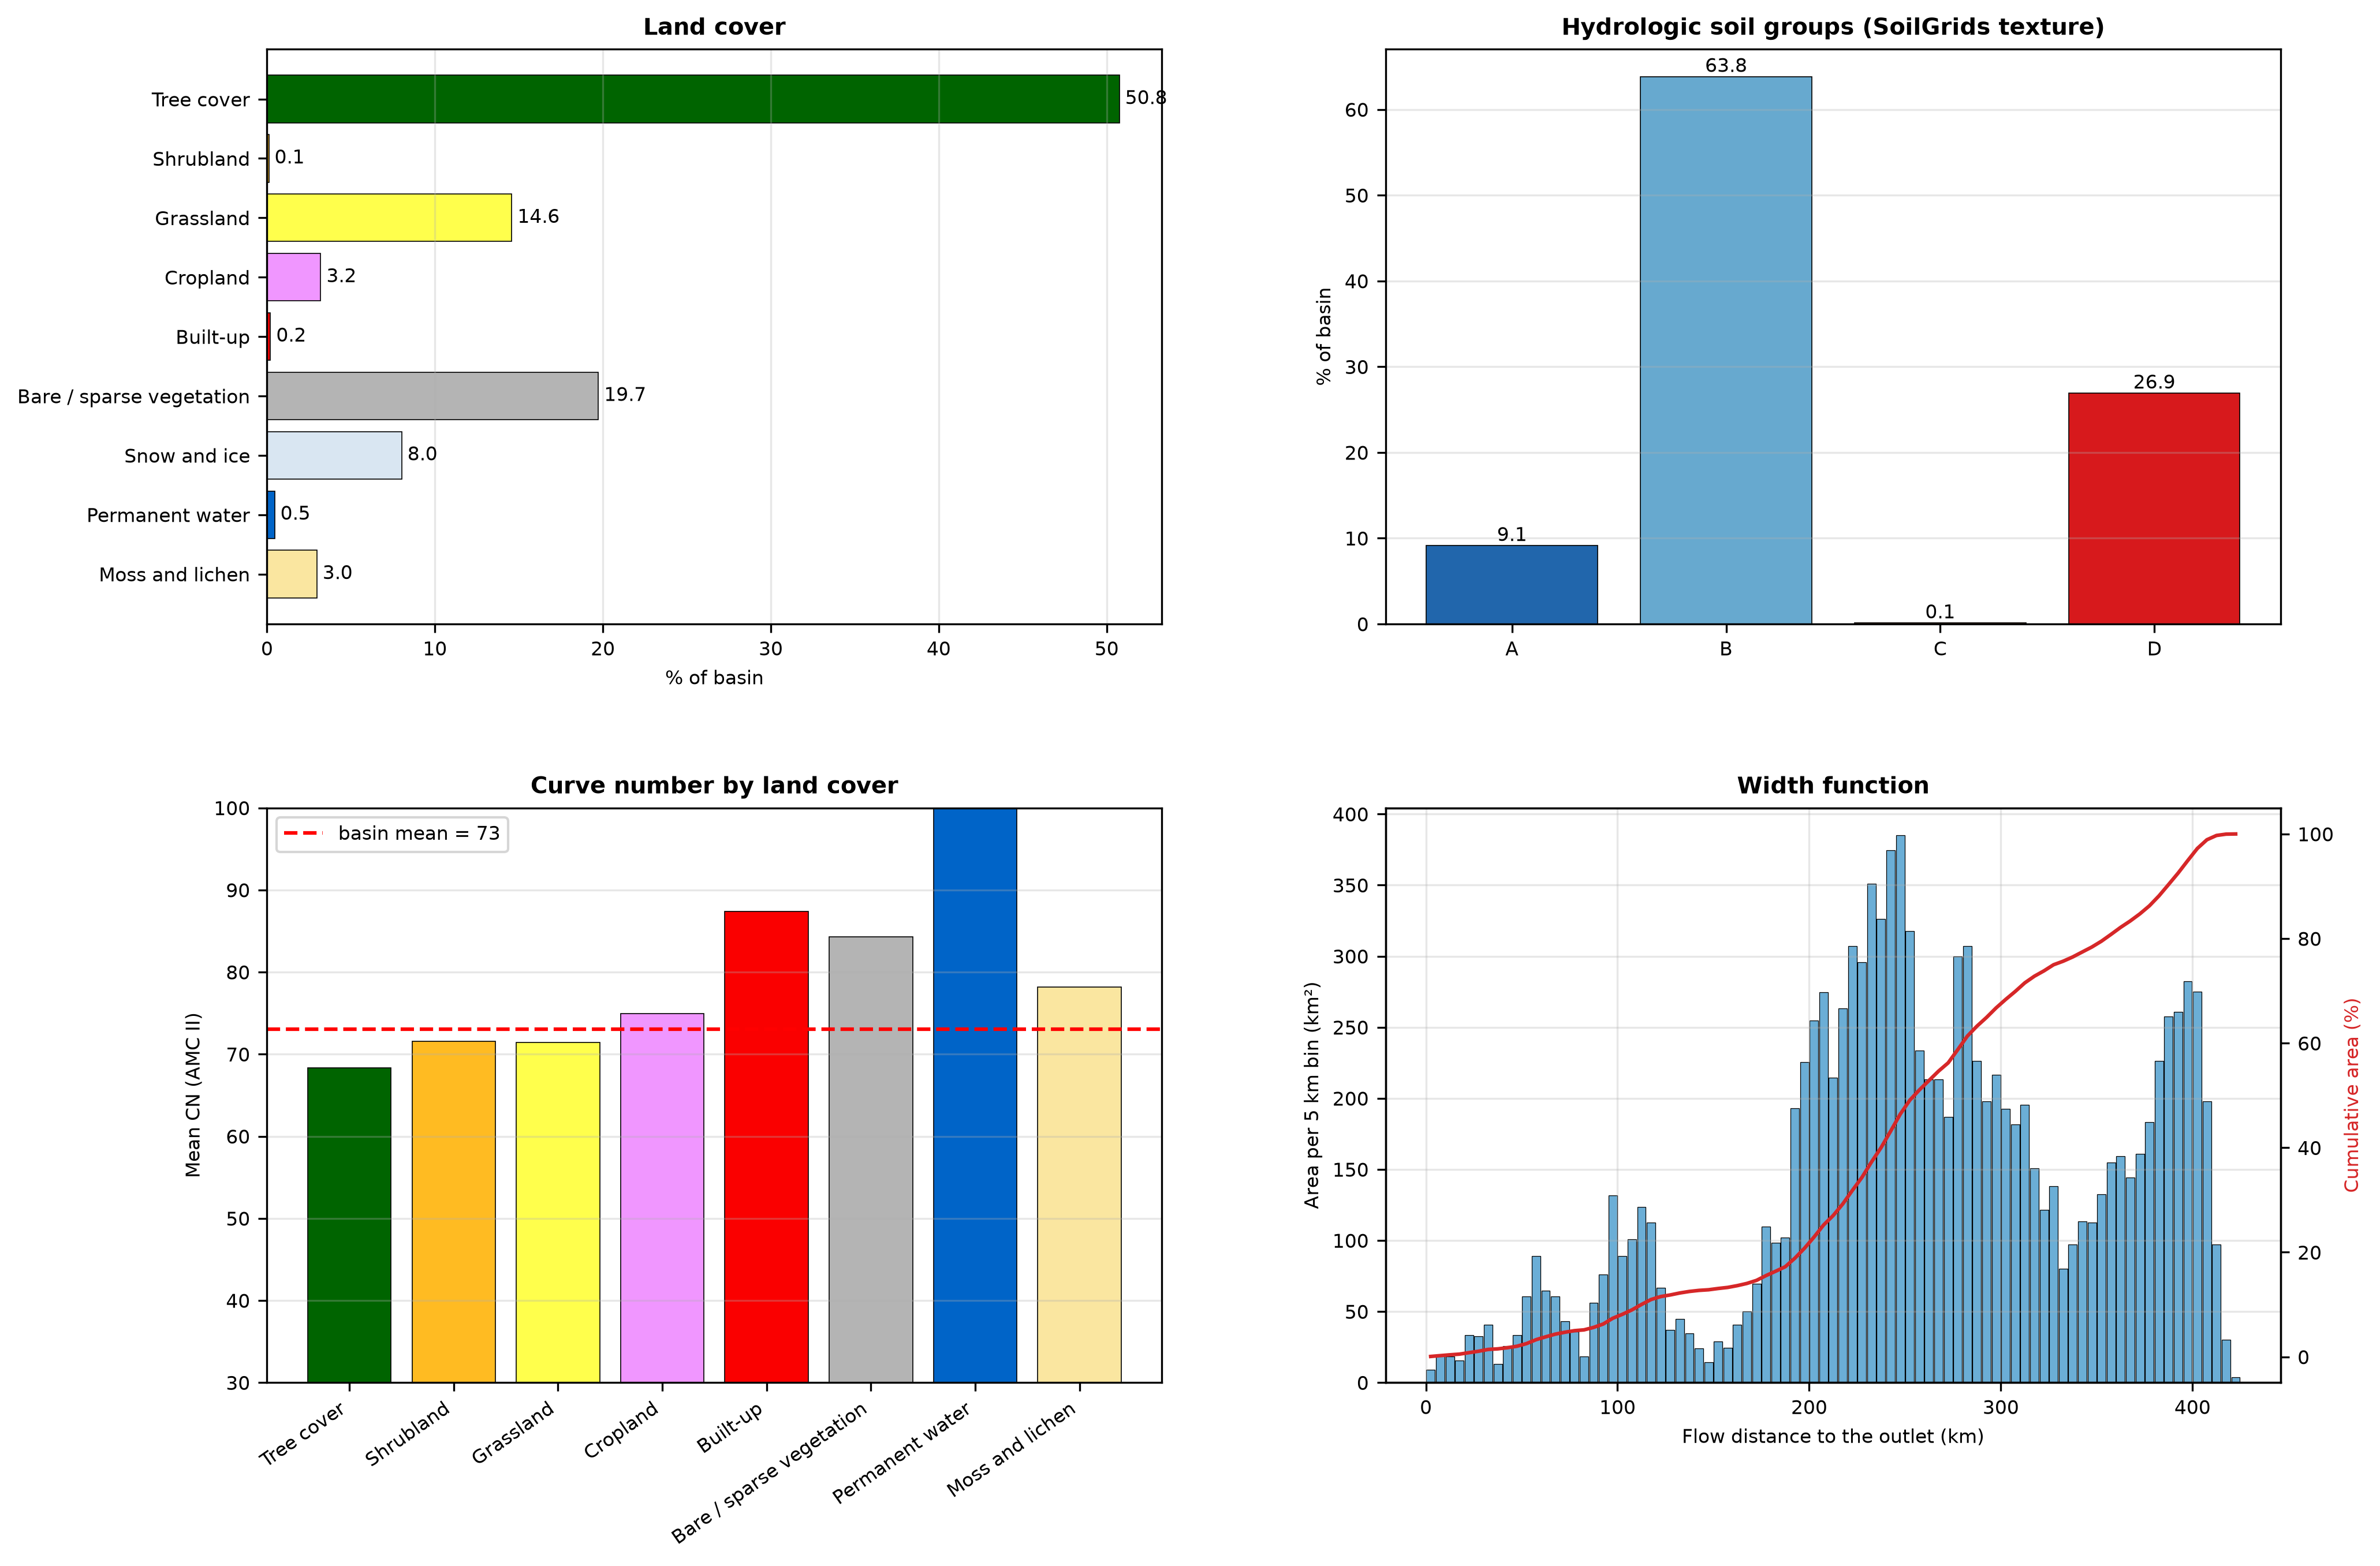

In [7]:
# ============================================================
# Cell 7: hydrology, land use, soil and curve-number statistics
# ============================================================
slug = lambda t: t.lower().replace(" / ", "_").replace(" ", "_").replace("-", "_")
WC_T = {10: ("Tree cover", "#006400"), 20: ("Shrubland", "#ffbb22"), 30: ("Grassland", "#ffff4c"),
        40: ("Cropland", "#f096ff"), 50: ("Built-up", "#fa0000"), 60: ("Bare / sparse vegetation", "#b4b4b4"),
        70: ("Snow and ice", "#d9e6f2"), 80: ("Permanent water", "#0064c8"),
        90: ("Herbaceous wetland", "#0096a0"), 95: ("Mangroves", "#00cf75"), 100: ("Moss and lichen", "#fae6a0")}
HSG_COL = {1: "#2166ac", 2: "#67a9cf", 3: "#fdae61", 4: "#d7191c"}

# ---------- hydrologic layers ----------
HYD = [("twi.tif", "TWI", "-"), ("spi.tif", "SPI", "m"), ("sti.tif", "STI", "-"), ("sca_dinf_m.tif", "SCA (D-inf)", "m"),
       ("flow_length_downstream_m.tif", "flow length to outlet", "m"),
       ("flow_length_upstream_max_m.tif", "longest upstream flowpath", "m"),
       ("slope_hydrologic_deg.tif", "slope (conditioned DEM)", "deg"), ("hand_m.tif", "HAND", "m"),
       ("flow_distance_to_stream_m.tif", "flow distance to stream", "m"),
       ("euclid_distance_to_stream_m.tif", "distance to stream", "m")]
rows = []
for fn, nm, un in HYD:
    v = basin_cells(fn, False)
    if v is not None:
        rows.append(layer_row(nm, un, v))
hyd_layers = pd.DataFrame(rows).round(5)
save_table(hyd_layers, P.TAB / "07_hydrology_layer_statistics.csv")
display(hyd_layers)

# ---------- hydrology metrics ----------
hr = []
for k_ in ("longest_flowpath_km", "flowpath_source_elev_m", "flowpath_outlet_elev_m", "flowpath_mean_gradient_m_per_m",
           "cells_changed_by_conditioning_pct", "net_volume_change_million_m3"):
    if k_ in hyd_sum.index:
        add(hr, "flowpath_and_conditioning", k_, float(hyd_sum[k_]))
acc_sum = opt("03_flow_accumulation_summary.csv")
if acc_sum is not None:
    for _, r_ in acc_sum.iterrows():
        if str(r_.metric).startswith("pct_cells_area_ge"):
            add(hr, "flow_accumulation", r_.metric, float(r_.value), "%")
twi_c = opt("03_twi_classes.csv")
if twi_c is not None:
    for _, r_ in twi_c.iterrows():
        add(hr, "twi", f"twi_class_{int(r_.class_id)}_upper_break", float(r_.twi_to), "-", "quantile class (20 % of cells each)")
h = R["hand"]
if h is not None:
    for t in (5, 15, 30, 100):
        add(hr, "hand", f"pct_basin_hand_le_{t}m", 100 * float((h <= t).mean()), "%", "includes the stream cells")
        add(hr, "hand", f"pct_basin_hand_le_{t}m_excl_streams", 100 * float(((h > 0) & (h <= t)).mean()), "%")
ed_ = basin_cells("euclid_distance_to_stream_m.tif", False)
if ed_ is not None:
    for t in (500, 1000, 2000, 5000):
        add(hr, "distance_to_streams", f"pct_basin_within_{t}m_of_a_stream", 100 * float((ed_ <= t).mean()), "%")

fl = basin_cells("flow_length_downstream_m.tif")
fl_km = fl[np.isfinite(fl)] / 1000
BIN = 5
edges_w = np.arange(0, np.ceil(fl_km.max() / BIN) * BIN + BIN, BIN)
cnt_w, _ = np.histogram(fl_km, bins=edges_w)
wf = pd.DataFrame({"from_km": edges_w[:-1], "to_km": edges_w[1:], "area_km2": cnt_w * CELL_KM2})
wf["cum_area_pct"] = 100 * np.cumsum(cnt_w) / cnt_w.sum()
save_table(wf.round(3), P.TAB / "07_width_function.csv")
add(hr, "width_function", "mean_flow_length_to_outlet_km", float(fl_km.mean()), "km")
add(hr, "width_function", "median_flow_length_to_outlet_km", float(np.median(fl_km)), "km")
add(hr, "width_function", "max_flow_length_to_outlet_km", float(fl_km.max()), "km")
add(hr, "width_function", "peak_width_bin_start_km", float(wf.loc[wf.area_km2.idxmax(), "from_km"]), "km", f"{BIN} km bins")
add(hr, "width_function", "peak_width_area_km2", float(wf.area_km2.max()), "km2")
hydro = pd.DataFrame(hr)
hydro["value"] = hydro["value"].astype(float).round(5)
save_table(hydro, P.TAB / "07_hydrology_statistics.csv")
display(hydro[["section", "metric", "value"]])

# ---------- land use, soil, curve number ----------
lc, hsg, cn = R["lc"], R["hsg"], R["cn"]
rows = []
codes = [c for c in WC_T if lc is not None and (lc == c).any()]
for c in codes:
    n_ = int((lc == c).sum())
    add(rows, "landcover", f"area_{slug(WC_T[c][0])}_km2", n_ * CELL_KM2, "km2")
    add(rows, "landcover", f"pct_{slug(WC_T[c][0])}", 100 * n_ / lc.size, "%")
groups = {"vegetated": [10, 20, 30, 40, 90, 95, 100], "forest_and_shrub": [10, 20], "agriculture": [40],
          "bare_snow_ice": [60, 70], "high_mountain_unvegetated": [60, 70, 100]}
for gname, gc in groups.items():
    add(rows, "landcover_groups", f"pct_{gname}", 100 * float(np.isin(lc, gc).mean()), "%")
if hsg is not None:
    for g_, nm in zip((1, 2, 3, 4), "ABCD"):
        add(rows, "soil", f"pct_hsg_{nm}", 100 * float((hsg == g_).mean()), "%")
    add(rows, "soil", "pct_no_soil_group_snow_ice_water", 100 * float((hsg == 0).mean()), "%")
for fn, nm in (("soil_sand_pct.tif", "mean_sand_pct"), ("soil_clay_pct.tif", "mean_clay_pct")):
    v = basin_cells(fn, False)
    if v is not None:
        add(rows, "soil", nm, float(np.nanmean(v)), "%", "0-100 cm thickness-weighted (SoilGrids 2.0)")
if cn is not None:
    okc = np.isfinite(cn)
    cv = cn[okc]
    cn_mean = float(cv.mean())
    add(rows, "curve_number", "basin_cn_amcII", cn_mean, "-", "snow and ice excluded")
    add(rows, "curve_number", "cn_median", float(np.median(cv)), "-")
    add(rows, "curve_number", "cn_p10", float(np.percentile(cv, 10)), "-"); add(rows, "curve_number", "cn_p90", float(np.percentile(cv, 90)), "-")
    add(rows, "curve_number", "pct_basin_without_cn", 100 * float((~okc).mean()), "%", "snow and ice")
    add(rows, "curve_number", "pct_cells_cn_ge_80", 100 * float((cv >= 80).mean() * okc.mean()), "% of basin")
    S_mm = 25400 / cn_mean - 254
    add(rows, "curve_number", "retention_S_mm_at_basin_cn", S_mm, "mm"); add(rows, "curve_number", "initial_abstraction_mm", 0.2 * S_mm, "mm")
    for c in codes:
        m_ = (lc == c) & okc
        if m_.any():
            add(rows, "curve_number_by_landcover", f"cn_{slug(WC_T[c][0])}", float(cn[m_].mean()), "-")
    if hsg is not None:
        for g_, nm in zip((1, 2, 3, 4), "ABCD"):
            m_ = (hsg == g_) & okc
            if m_.any():
                add(rows, "curve_number_by_soil", f"cn_hsg_{nm}", float(cn[m_].mean()), "-")
cn_sub = master.CN_II
add(rows, "subcatchment_cn", "cn_min", float(cn_sub.min()), "-"); add(rows, "subcatchment_cn", "cn_max", float(cn_sub.max()), "-")
add(rows, "subcatchment_cn", "cn_median", float(cn_sub.median()), "-")
if "cn_caution" in master.columns:
    add(rows, "subcatchment_cn", "n_units_cn_caution", int(master.cn_caution.sum()), "-", "snow and ice >= 25 % of the unit")
luc = pd.DataFrame(rows)
luc["value"] = luc["value"].astype(float).round(5)
save_table(luc, P.TAB / "07_landuse_soil_cn_statistics.csv")
display(luc[["section", "metric", "value", "unit"]])

# ---------- land cover x soil group (km2) ----------
if lc is not None and hsg is not None:
    xt = pd.DataFrame({nm: [float(((lc == c) & (hsg == g_)).sum() * CELL_KM2) for c in codes]
                       for g_, nm in zip((1, 2, 3, 4), "ABCD")}, index=[WC_T[c][0] for c in codes])
    xt["no soil group"] = [float(((lc == c) & (hsg == 0)).sum() * CELL_KM2) for c in codes]
    xt["total_km2"] = xt.sum(axis=1)
    xt = xt.round(2)
    save_table(xt.reset_index().rename(columns={"index": "land_cover"}), P.TAB / "07_landcover_x_hsg_km2.csv")
    display(xt)

# ---------- figure ----------
fig, axs = plt.subplots(2, 2, figsize=(15, 10), gridspec_kw={"hspace": 0.32, "wspace": 0.25})
ax = axs[0, 0]
if codes:
    pc = [100 * float((lc == c).mean()) for c in codes]
    ax.barh([WC_T[c][0] for c in codes], pc, color=[WC_T[c][1] for c in codes], edgecolor="k", linewidth=0.4)
    for i_, v_ in enumerate(pc):
        ax.text(v_, i_, f" {v_:.1f}", va="center", fontsize=8)
    ax.invert_yaxis(); ax.set_xlabel("% of basin")
ax.set_title("Land cover", fontweight="bold"); ax.grid(alpha=0.3, axis="x")

ax = axs[0, 1]
if hsg is not None:
    ph = [100 * float((hsg == g_).mean()) for g_ in (1, 2, 3, 4)]
    ax.bar(list("ABCD"), ph, color=[HSG_COL[g_] for g_ in (1, 2, 3, 4)], edgecolor="k", linewidth=0.4)
    for i_, v_ in enumerate(ph):
        ax.text(i_, v_, f"{v_:.1f}", ha="center", va="bottom", fontsize=8)
    ax.set_ylabel("% of basin")
ax.set_title("Hydrologic soil groups (SoilGrids texture)", fontweight="bold"); ax.grid(alpha=0.3, axis="y")

ax = axs[1, 0]
if cn is not None:
    names_c = [(WC_T[c][0], float(cn[(lc == c) & np.isfinite(cn)].mean()), WC_T[c][1])
               for c in codes if ((lc == c) & np.isfinite(cn)).any()]
    ax.bar([n_[0] for n_ in names_c], [n_[1] for n_ in names_c], color=[n_[2] for n_ in names_c], edgecolor="k", linewidth=0.4)
    ax.axhline(cn_mean, color="red", ls="--", label=f"basin mean = {cn_mean:.0f}")
    ax.set_ylim(30, 100); ax.set_ylabel("Mean CN (AMC II)"); ax.legend(fontsize=8)
    plt.setp(ax.get_xticklabels(), rotation=35, ha="right", fontsize=8)
ax.set_title("Curve number by land cover", fontweight="bold"); ax.grid(alpha=0.3, axis="y")

ax = axs[1, 1]
cen_w = (wf.from_km + wf.to_km) / 2
ax.bar(cen_w, wf.area_km2, width=BIN * 0.9, color="#6baed6", edgecolor="k", linewidth=0.3)
ax.set_xlabel("Flow distance to the outlet (km)"); ax.set_ylabel(f"Area per {BIN} km bin (km²)")
ax2 = ax.twinx(); ax2.plot(cen_w, wf.cum_area_pct, color="tab:red", lw=1.5); ax2.set_ylabel("Cumulative area (%)", color="tab:red")
ax.set_title("Width function", fontweight="bold"); ax.grid(alpha=0.3)
fig.savefig(P.FIG / "07_landuse_soil_cn_panel.png", dpi=250, bbox_inches="tight", facecolor="white")
plt.show(); plt.close(fig)

,metric,value,unit,source
0,Basin area,11873.0888,km²,morphometry
1,Perimeter,905.5939,km,morphometry
2,Longest flowpath,422.2746,km,morphometry
3,Form factor,0.0666,-,morphometry
4,Circularity ratio,0.1819,-,morphometry
5,Minimum elevation,184.0000,m,morphometry
6,Maximum elevation,8141.0000,m,morphometry
7,Mean elevation,2797.2752,m,morphometry
8,Relief,7957.0000,m,morphometry
9,Hypsometric integral,0.3284,-,morphometry


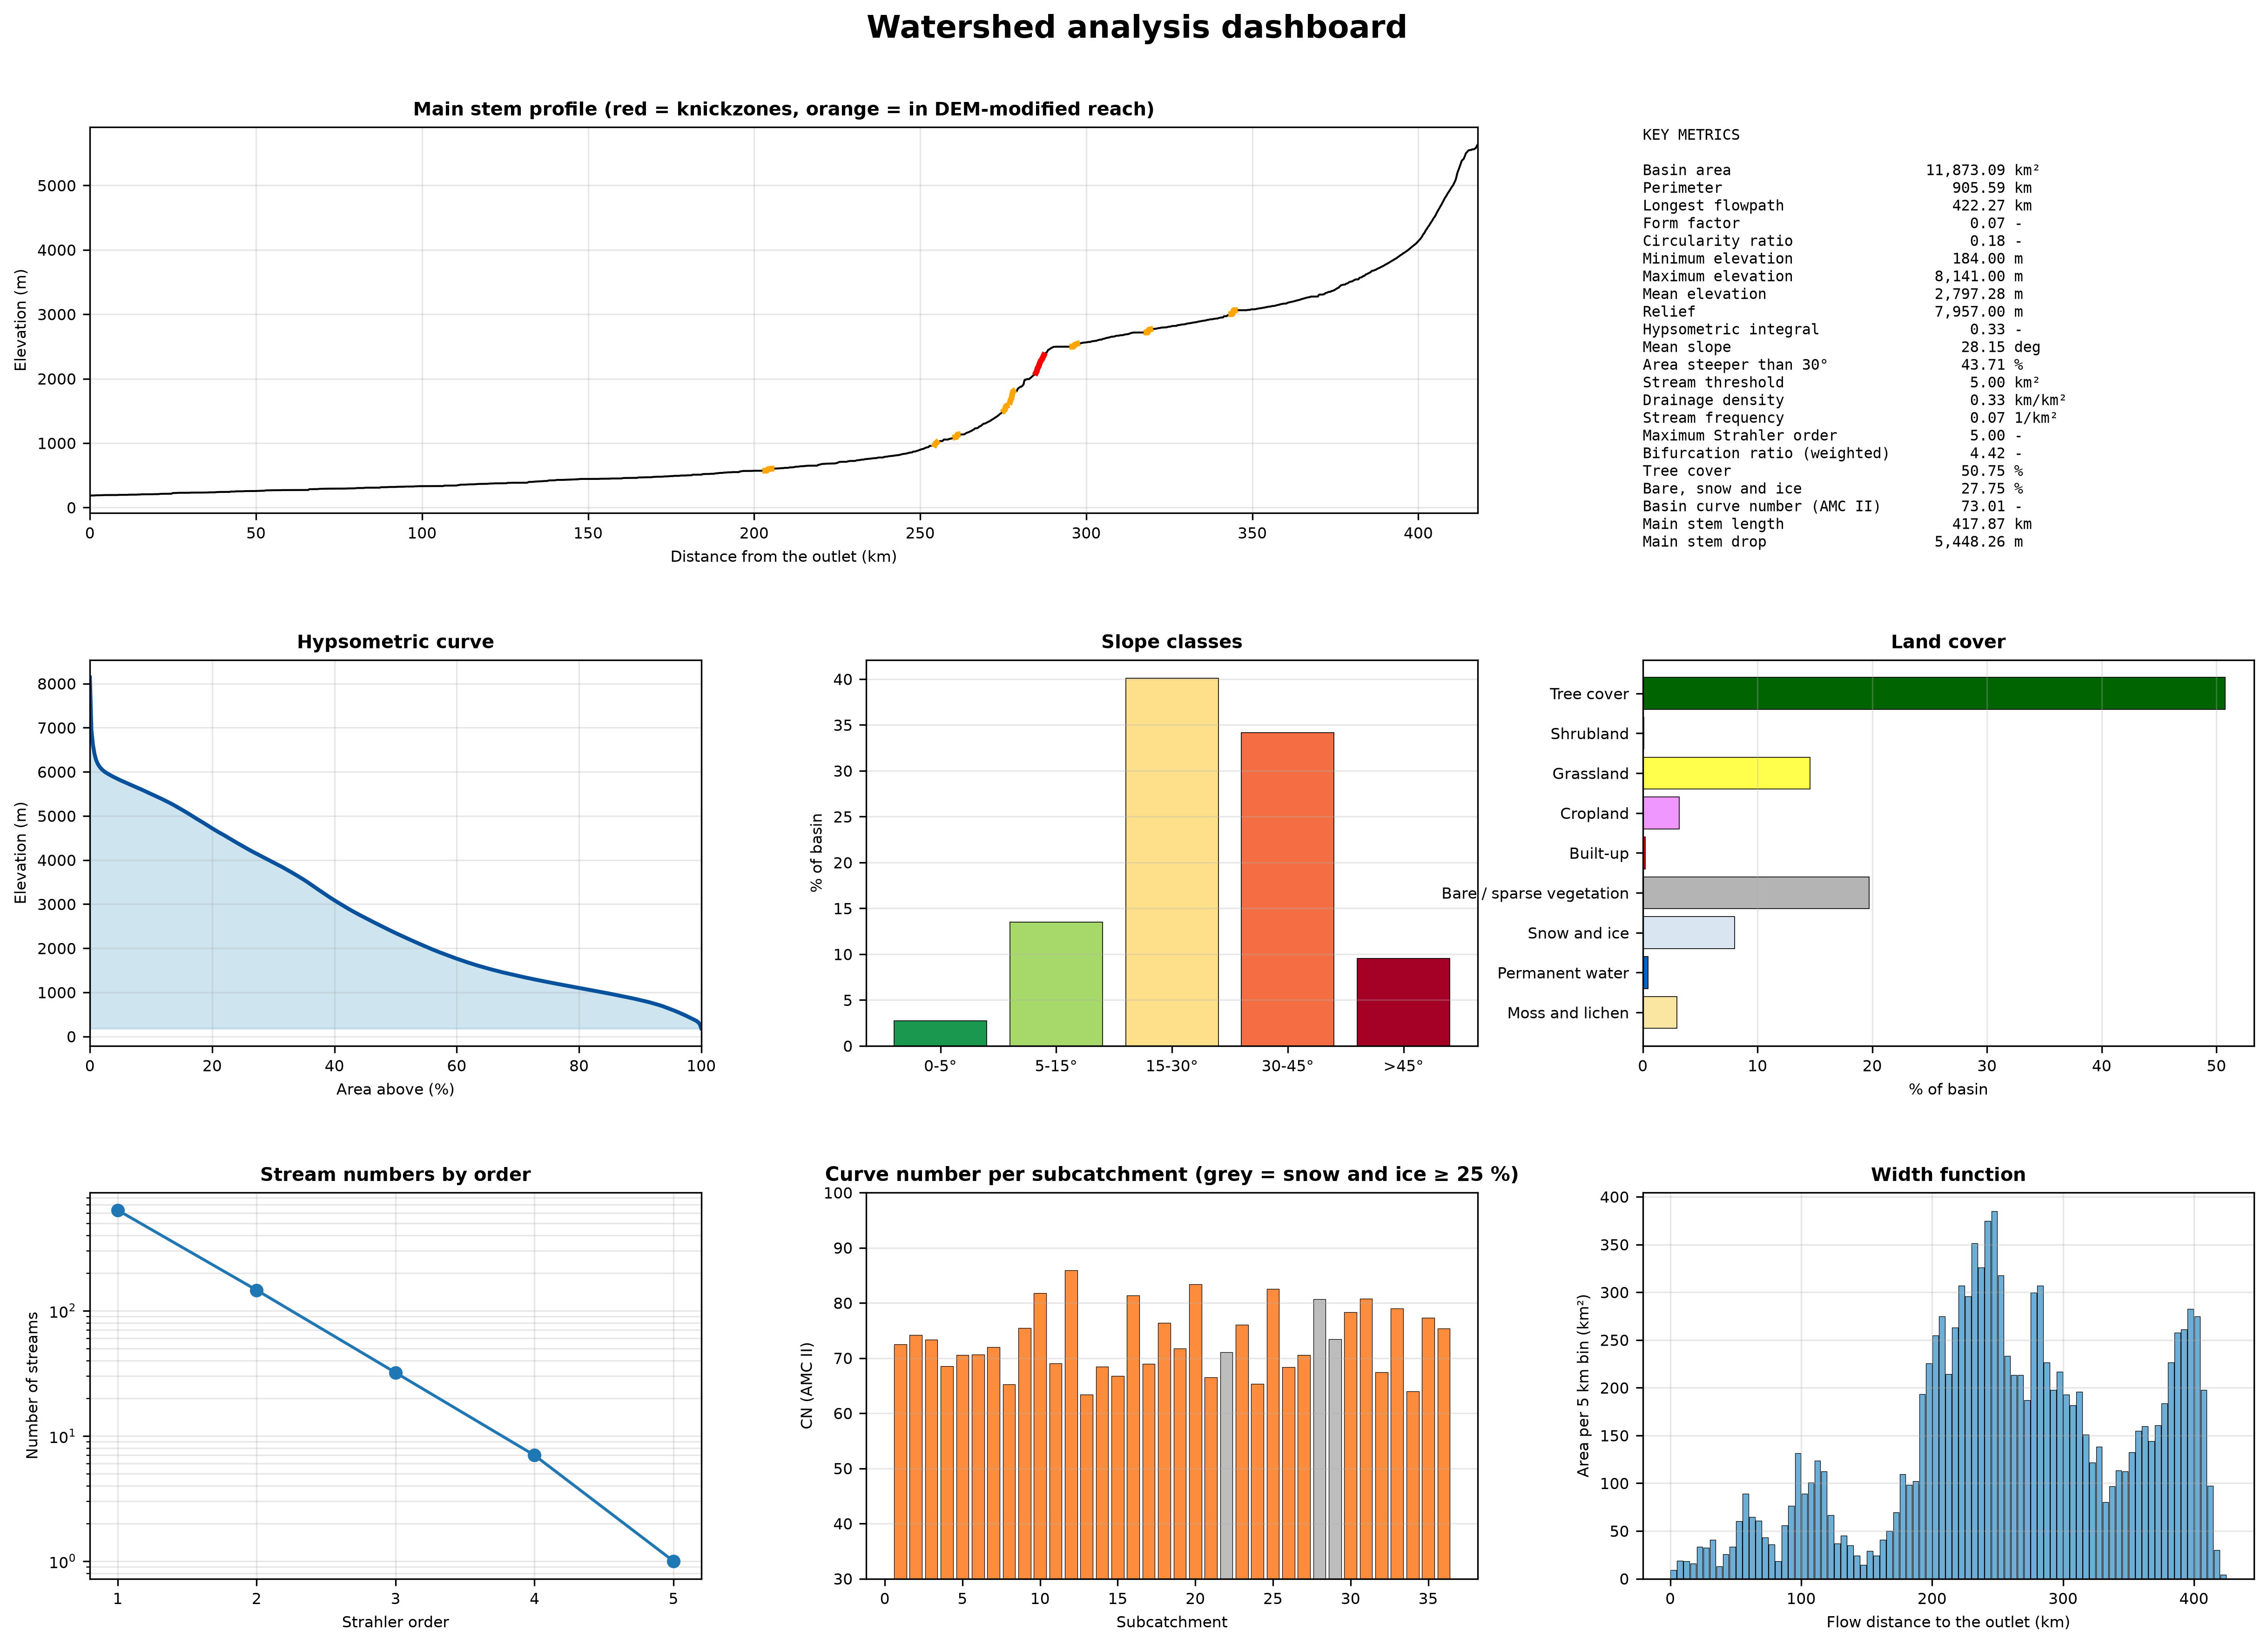

Report written: D:\Watershed_Analysis\Outputs\07_basin_report.md
         files  size_mb
folder                 
Figures    119    142.5
Rasters     59   2966.4
Tables      79      4.3
Vectors    136    981.6
Scratch (_tmp) files: 0, 0 MB (safe to delete)
Soil download cache: 4 MB in Inputs/soilgrids_wcs_cache
openpyxl is not installed, so no Excel workbook was written (conda install -c conda-forge openpyxl, then rerun this cell).


In [10]:
# ============================================================
# Cell 8: key metrics, dashboard, data dictionary, report, manifest
# ============================================================
def load(name):
    p = P.TAB / name
    return pd.read_csv(p) if p.exists() else None

def gv(df, metric, default=np.nan):
    if df is None:
        return default
    r = df.loc[df.metric == metric, "value"]
    return float(r.iloc[0]) if len(r) else default

morph = load("07_watershed_morphometry.csv"); slope_s = load("07_slope_statistics.csv")
riv = load("07_river_statistics.csv"); luc_t = load("07_landuse_soil_cn_statistics.csv"); sbs = load("07_subbasin_statistics.csv")

KM = [("Basin area", gv(morph, "area_km2"), "km²", "morphometry"),
      ("Perimeter", gv(morph, "perimeter_km"), "km", "morphometry"),
      ("Longest flowpath", gv(morph, "basin_length_longest_flowpath_km"), "km", "morphometry"),
      ("Form factor", gv(morph, "form_factor"), "-", "morphometry"),
      ("Circularity ratio", gv(morph, "circularity_ratio"), "-", "morphometry"),
      ("Minimum elevation", gv(morph, "min_elevation_m"), "m", "morphometry"),
      ("Maximum elevation", gv(morph, "max_elevation_m"), "m", "morphometry"),
      ("Mean elevation", gv(morph, "mean_elevation_m"), "m", "morphometry"),
      ("Relief", gv(morph, "relief_m"), "m", "morphometry"),
      ("Hypsometric integral", gv(morph, "hypsometric_integral"), "-", "morphometry"),
      ("Mean slope", gv(morph, "mean_slope_deg"), "deg", "morphometry"),
      ("Area steeper than 30°", gv(slope_s, "area_slope_gt_30deg_pct"), "%", "slope"),
      ("Stream threshold", gv(morph, "stream_threshold_km2"), "km²", "morphometry"),
      ("Drainage density", gv(morph, "drainage_density_km_per_km2"), "km/km²", "morphometry"),
      ("Stream frequency", gv(morph, "stream_frequency_per_km2"), "1/km²", "morphometry"),
      ("Maximum Strahler order", gv(morph, "max_strahler_order"), "-", "morphometry"),
      ("Bifurcation ratio (weighted)", gv(morph, "bifurcation_ratio_weighted_mean"), "-", "morphometry"),
      ("Tree cover", gv(luc_t, "pct_tree_cover"), "%", "land use"),
      ("Bare, snow and ice", gv(luc_t, "pct_bare_snow_ice"), "%", "land use"),
      ("Basin curve number (AMC II)", gv(luc_t, "basin_cn_amcII"), "-", "land use"),
      ("Main stem length", gv(riv, "length_km"), "km", "river"),
      ("Main stem drop", gv(riv, "total_drop_m"), "m", "river"),
      ("Main stem mean gradient", gv(riv, "mean_gradient_m_per_m"), "m/m", "river"),
      ("Main stem sinuosity", gv(riv, "sinuosity_overall"), "-", "river"),
      ("Slope-area concavity θ", gv(riv, "slope_area_theta"), "-", "river"),
      ("Knickzones (all)", gv(riv, "n_knickzones"), "-", "river"),
      ("Bends", gv(riv, "n_bends"), "-", "river"),
      ("Largest 5 km head", gv(riv, "max_head_5km_m"), "m", "river (head only)"),
      ("Subcatchments", float(len(sbs)) if sbs is not None else np.nan, "-", "subbasins"),
      ("Median subcatchment area", float(sbs.area_km2.median()) if sbs is not None else np.nan, "km²", "subbasins"),
      ("Largest subcatchment", float(sbs.area_km2.max()) if sbs is not None else np.nan, "km²", "subbasins")]
key = pd.DataFrame(KM, columns=["metric", "value", "unit", "source"])
key["value"] = key["value"].round(4)
save_table(key, P.TAB / "07_key_metrics.csv")
display(key)

# ---------- dashboard ----------
hy = load("07_hypsometric_curve.csv"); sc_ = load("07_slope_classes.csv"); st_ = load("07_stream_statistics.csv")
wf_ = load("07_width_function.csv"); lcc = load("05_landcover_classes.csv")
fig = plt.figure(figsize=(20, 13.5))
gs = fig.add_gridspec(3, 3, hspace=0.38, wspace=0.27)

ax = fig.add_subplot(gs[0, :2])
xk = river_t.d_out_m / 1000
ax.plot(xk, river_t.z_smooth, color="k", lw=1)
for kid, gk in river_t[river_t.knickzone_id > 0].groupby("knickzone_id"):
    ax.plot(gk.d_out_m / 1000, gk.z_smooth, color="orange" if gk.dem_modified.mean() >= 0.3 else "red", lw=3)
ax.set_xlim(0, xk.max()); ax.set_xlabel("Distance from the outlet (km)"); ax.set_ylabel("Elevation (m)")
ax.set_title("Main stem profile (red = knickzones, orange = in DEM-modified reach)", fontweight="bold"); ax.grid(alpha=0.3)

ax = fig.add_subplot(gs[0, 2]); ax.axis("off")
lines_ = [f"{m_:<30}{v_:>11,.2f} {u_}" for m_, v_, u_ in zip(key.metric, key.value, key.unit)][:22]
ax.text(0, 1, "KEY METRICS\n\n" + "\n".join(lines_), va="top", family="monospace", fontsize=7.6)

ax = fig.add_subplot(gs[1, 0])
if hy is not None:
    ax.plot(hy.area_above_pct, hy.elevation_m, color="#08519c", lw=2); ax.fill_between(hy.area_above_pct, hy.elevation_m, hy.elevation_m.min(), color="#9ecae1", alpha=0.5)
    ax.set_xlim(0, 100); ax.set_xlabel("Area above (%)"); ax.set_ylabel("Elevation (m)")
ax.set_title("Hypsometric curve", fontweight="bold"); ax.grid(alpha=0.3)

ax = fig.add_subplot(gs[1, 1])
if sc_ is not None:
    ax.bar(range(len(sc_)), sc_.percent, color=SLOPE_COLORS[:len(sc_)], edgecolor="k", linewidth=0.4)
    ax.set_xticks(range(len(sc_))); ax.set_xticklabels([c_.split(" ")[0] for c_ in sc_["class"]], fontsize=8); ax.set_ylabel("% of basin")
ax.set_title("Slope classes", fontweight="bold"); ax.grid(alpha=0.3, axis="y")

ax = fig.add_subplot(gs[1, 2])
if lcc is not None:
    ax.barh(lcc["class"], lcc.percent, color=[WC_T[int(c_)][1] for c_ in lcc.code], edgecolor="k", linewidth=0.4)
    ax.invert_yaxis(); ax.set_xlabel("% of basin"); ax.tick_params(axis="y", labelsize=8)
ax.set_title("Land cover", fontweight="bold"); ax.grid(alpha=0.3, axis="x")

ax = fig.add_subplot(gs[2, 0])
if st_ is not None:
    ax.semilogy(st_["order"], st_.streams_N, "o-", color="tab:blue"); ax.set_xticks(st_["order"])
    ax.set_xlabel("Strahler order"); ax.set_ylabel("Number of streams")
ax.set_title("Stream numbers by order", fontweight="bold"); ax.grid(alpha=0.3, which="both")

ax = fig.add_subplot(gs[2, 1])
if sbs is not None and "CN_II" in sbs.columns:
    ax.bar(sbs.sub_id, sbs.CN_II, color=np.where(sbs.cn_caution, "#bdbdbd", "#fd8d3c"), edgecolor="k", linewidth=0.3)
    ax.set_ylim(30, 100); ax.set_xlabel("Subcatchment"); ax.set_ylabel("CN (AMC II)")
ax.set_title("Curve number per subcatchment (grey = snow and ice ≥ 25 %)", fontweight="bold", fontsize=10); ax.grid(alpha=0.3, axis="y")

ax = fig.add_subplot(gs[2, 2])
if wf_ is not None:
    cw = (wf_.from_km + wf_.to_km) / 2
    ax.bar(cw, wf_.area_km2, width=4.5, color="#6baed6", edgecolor="k", linewidth=0.3)
    ax.set_xlabel("Flow distance to the outlet (km)"); ax.set_ylabel("Area per 5 km bin (km²)")
ax.set_title("Width function", fontweight="bold"); ax.grid(alpha=0.3)
fig.suptitle("Watershed analysis dashboard", fontsize=16, fontweight="bold", y=0.94)
fig.savefig(P.FIG / "07_basin_dashboard.png", dpi=220, bbox_inches="tight", facecolor="white")
plt.show(); plt.close(fig)

# ---------- data dictionary ----------
FILES = {
 "07_consistency_checks.csv": "cross-notebook audit: areas, counts, lengths, bookkeeping",
 "07_watershed_morphometry.csv": "basin shape, relief and drainage indices (section, metric, value, unit, note)",
 "07_elevation_statistics.csv": "elevation distribution, hypsometric integral, area above thresholds",
 "07_elevation_bands.csv": "500 m bands: area, slope, land cover shares, CN, cumulative area",
 "07_hypsometric_curve.csv": "area-elevation curve (401 points)",
 "07_slope_statistics.csv": "slope distribution and area above 15, 30 and 45 degrees",
 "07_slope_classes.csv": "slope classes with area, mean elevation and TWI",
 "07_slope_by_aspect.csv": "aspect directions with area, slope and elevation",
 "07_terrain_layer_statistics.csv": "min, percentiles, mean, max of elevation, slope, TRI, relief, curvature and TPI",
 "07_stream_statistics.csv": "Strahler table with gradient, sinuosity and ksn by order",
 "07_stream_threshold_scale.csv": "drainage density and link counts at several thresholds",
 "07_subbasin_statistics.csv": "one row per subcatchment: morphometry, land use, soil, CN, river stats, ranks, z-scores, screening score",
 "07_subbasin_metric_distribution.csv": "spread of each metric across subcatchments",
 "07_subbasin_correlation.csv": "Spearman correlations between subcatchment metrics",
 "07_river_statistics.csv": "main stem profile, knickzones, planform, confinement, confluences, head drops",
 "07_hydrology_layer_statistics.csv": "statistics of TWI, SPI, STI, SCA, flow lengths, HAND and stream distances",
 "07_hydrology_statistics.csv": "flowpath, conditioning, HAND shares, distance to streams, width function",
 "07_width_function.csv": "area per 5 km of flow distance to the outlet",
 "07_landuse_soil_cn_statistics.csv": "land cover, soil group and curve-number statistics",
 "07_landcover_x_hsg_km2.csv": "area of each land cover by hydrologic soil group",
 "07_key_metrics.csv": "headline numbers for reports",
 "07_output_manifest.csv": "every output file with size and date"}
COLS = {
 "sub_id": "subcatchment id (1 = outlet unit; downstream ids are always smaller)", "down_id": "id of the downstream unit (0 = basin outlet)",
 "n_direct_upstream": "number of units draining directly into this one", "on_main_stem": "unit contains the main stem",
 "area_km2": "unit area", "upstr_area_km2": "contributing area at the unit outlet", "perimeter_km": "outline length (simplified by one cell)",
 "elev_mean_m": "mean elevation", "relief_m": "max minus min elevation", "hypsometric_integral": "(mean - min) / (max - min)",
 "slope_mean_deg": "mean slope", "mean_twi": "mean topographic wetness index", "mean_hand_m": "mean height above nearest drainage",
 "flowpath_length_km": "longest flowpath inside the unit", "flowpath_gradient_m_per_m": "elevation drop over that flowpath",
 "form_factor": "area / length^2", "elongation_ratio": "1.128 sqrt(area) / length", "circularity_ratio": "4 pi area / perimeter^2",
 "compactness_gravelius": "perimeter / (2 sqrt(pi area))", "relief_ratio": "relief / flowpath length",
 "stream_length_km": "stream length in the unit at the stream threshold", "drainage_density_km_per_km2": "stream length / area",
 "n_links": "stream links in the unit", "n_channel_heads": "channel heads in the unit", "max_strahler_order": "highest Strahler order",
 "n_merged": "slivers merged into this unit", "dominant_landcover": "land cover with the largest share", "dominant_hsg": "hydrologic soil group with the largest share",
 "snow_ice_pct": "share of snow and ice", "CN_II": "composite curve number, AMC II, snow and ice excluded",
 "CN_II_incl_snow": "same with snow and ice at CN 100", "CN_II_slopeadj": "slope-adjusted CN (Sharpley-Williams)",
 "CN_I": "dry-condition CN", "CN_III": "wet-condition CN", "S_mm": "potential maximum retention", "Ia_mm": "initial abstraction (0.2 S)",
 "cn_caution": "True when snow and ice cover 25 % or more, so CN describes little of the unit",
 "tc_kirpich_h": "Kirpich time of concentration (hours; calibrated on small catchments)", "tlag_scs_h": "SCS lag time (hours)", "tc_scs_h": "SCS time of concentration (hours)",
 "mean_gradient_m_per_m": "stream gradient (total link drop / stream length)", "max_link_gradient": "steepest stream link", "mean_sinuosity_w": "length-weighted mean sinuosity",
 "ksn_median": "median channel steepness index", "ksn_mean_w": "length-weighted mean ksn", "area_share_pct": "share of the basin area",
 "runoff_screening_score": "0-100 rank-based index (editable weights); NOT a hazard or discharge model", "score_rank": "rank by that score (1 = highest)"}
dd = [{"kind": "file", "name": f, "description": d_} for f, d_ in FILES.items()]
dd += [{"kind": "column", "name": c_, "description": COLS.get(c_, "rank_<metric> = rank (1 = highest); z_<metric> = z-score across units" if c_.startswith(("rank_", "z_")) else "see the notebook that created it (04 geometry, 05 land use / soil / CN, 06 river)")}
       for c_ in (sbs.columns if sbs is not None else [])]
save_table(pd.DataFrame(dd), P.TAB / "07_data_dictionary.csv")

# ---------- Markdown report ----------
k = {m_: v_ for m_, v_ in zip(key.metric, key.value)}
top = sbs.sort_values("score_rank").head(5)
report = f"""# Watershed analysis report

*Generated by 07_Statistics.ipynb. All numbers come from the files listed in `07_output_manifest.csv`.*

## Basin
- Area **{k['Basin area']:,.0f} km²**, perimeter {k['Perimeter']:,.0f} km, longest flowpath {k['Longest flowpath']:,.0f} km
- Form factor {k['Form factor']:.2f}, circularity ratio {k['Circularity ratio']:.2f} (elongated basin)
- Elevation {k['Minimum elevation']:,.0f} to {k['Maximum elevation']:,.0f} m, mean {k['Mean elevation']:,.0f} m, relief {k['Relief']:,.0f} m
- Hypsometric integral {k['Hypsometric integral']:.2f}; mean slope {k['Mean slope']:.1f}°; {k['Area steeper than 30°']:.0f} % of the basin is steeper than 30°

## Drainage network (threshold {k['Stream threshold']:g} km²)
- Drainage density {k['Drainage density']:.2f} km/km², stream frequency {k['Stream frequency']:.3f} per km², maximum Strahler order {k['Maximum Strahler order']:.0f}
- Weighted bifurcation ratio {k['Bifurcation ratio (weighted)']:.2f}. Drainage figures depend on the threshold.

## Land use, soil and runoff
- Tree cover {k['Tree cover']:.0f} %; bare ground, snow and ice {k['Bare, snow and ice']:.0f} %
- Basin curve number (AMC II, snow and ice excluded) {k['Basin curve number (AMC II)']:.0f}
- CN describes rainfall-runoff only. Units flagged `cn_caution` have 25 % or more snow and ice.

## Main river
- Length {k['Main stem length']:.0f} km, drop {k['Main stem drop']:,.0f} m, mean gradient {k['Main stem mean gradient']:.4f} m/m, sinuosity {k['Main stem sinuosity']:.2f}
- {k['Knickzones (all)']:.0f} knickzones and {k['Bends']:.0f} bends detected; the largest 5 km gross head is {k['Largest 5 km head']:.0f} m
- Hydropower figures are screening values: head comes from the DEM, flow is a placeholder, so treat power as indicative only

## Subcatchments
- {k['Subcatchments']:.0f} units, median area {k['Median subcatchment area']:,.0f} km², largest {k['Largest subcatchment']:,.0f} km²
- Highest screening scores (rank-based, not a hazard model): {', '.join(f"unit {int(i_)} ({s_:.0f})" for i_, s_ in zip(top.sub_id, top.runoff_screening_score))}

## Data and caveats
- DEM: `kali44N.tif`, reprojected to UTM 44N, {ws.res[0]:.1f} m cells; conditioned with least-cost breaching (reach 250 cells)
- Land cover: © ESA WorldCover project 2021 / Contains modified Copernicus Sentinel data (2021) processed by ESA WorldCover consortium
- Soil: SoilGrids 2.0 (ISRIC), CC-BY 4.0; hydrologic soil groups are derived from texture (no depth to bedrock), so they are approximate
- CN values are assumptions from TR-55-style tables and are listed in `Inputs/cn_lookup.csv`
- Time-of-concentration formulas were calibrated on small catchments; use them as order-of-magnitude only
- Audit: see `07_consistency_checks.csv`
"""
(P.TAB.parent / "07_basin_report.md").write_text(report, encoding="utf-8")
print("Report written:", P.TAB.parent / "07_basin_report.md")

# ---------- manifest ----------
rows = []
for folder, label in [(P.RAS, "Rasters"), (P.VEC, "Vectors"), (P.FIG, "Figures"), (P.TAB, "Tables")]:
    for p in sorted(folder.rglob("*")):
        if p.is_file():
            rows.append({"folder": label, "file": p.relative_to(folder).as_posix(), "size_mb": round(p.stat().st_size / 1e6, 3),
                         "modified": pd.Timestamp(p.stat().st_mtime, unit="s").strftime("%Y-%m-%d %H:%M"),
                         "scratch": p.parent.name == "_tmp"})
man = pd.DataFrame(rows)
save_table(man, P.TAB / "07_output_manifest.csv")
print(man[~man.scratch].groupby("folder").agg(files=("file", "count"), size_mb=("size_mb", "sum")).round(1))
print(f"Scratch (_tmp) files: {int(man.scratch.sum())}, {man.loc[man.scratch, 'size_mb'].sum():,.0f} MB (safe to delete)")
cache = P.INPUTS / "soilgrids_wcs_cache"
if cache.exists():
    print(f"Soil download cache: {sum(f.stat().st_size for f in cache.glob('*.tif')) / 1e6:.0f} MB in Inputs/{cache.name}")

# ---------- optional Excel workbook ----------
try:
    import openpyxl  # noqa: F401
    with pd.ExcelWriter(P.TAB / "07_basin_statistics.xlsx") as xw:
        for f in ["07_key_metrics", "07_watershed_morphometry", "07_elevation_statistics", "07_slope_statistics",
                  "07_stream_statistics", "07_subbasin_statistics", "07_river_statistics", "07_hydrology_statistics",
                  "07_landuse_soil_cn_statistics", "07_consistency_checks"]:
            t_ = load(f + ".csv")
            if t_ is not None:
                t_.to_excel(xw, sheet_name=f[3:31], index=False)
    print("Excel workbook written: Outputs/Tables/07_basin_statistics.xlsx")
except ImportError:
    print("openpyxl is not installed, so no Excel workbook was written "
          "(conda install -c conda-forge openpyxl, then rerun this cell).")

In [11]:
from pathlib import Path
from PIL import Image

root = Path(r"D:\Watershed_Analysis")
out = root / "docs" / "images"
out.mkdir(parents=True, exist_ok=True)
pick = ["07_basin_dashboard.png", "04_subcatchments.png", "04_stream_order.png", "05_landcover.png",
        "05_cn_by_subcatchment.png", "06_longitudinal_profile.png", "02_dem_hillshade.png",
        "03_twi.png", "01_watershed.png"]
for name in pick:
    src = root / "Outputs" / "Figures" / name
    if not src.exists():
        print("missing:", name); continue
    im = Image.open(src).convert("RGB")
    im.thumbnail((1600, 1600))
    im.save(out / (Path(name).stem + ".jpg"), quality=85, optimize=True)
    print("saved", name)

saved 07_basin_dashboard.png
saved 04_subcatchments.png
saved 04_stream_order.png
saved 05_landcover.png
saved 05_cn_by_subcatchment.png
saved 06_longitudinal_profile.png
saved 02_dem_hillshade.png
saved 03_twi.png
saved 01_watershed.png
